# Visual Grounding and Parameter-Efficient Adaptation for Wildfire Visual Question Answering

### An Exploratory Study on FLAMEVQA

**Author:** Sajjad Ahmad

**Research Area:** Multimodal AI, Computer Vision,
Vision-Language Models, and Wildfire Monitoring

**Date:** November 2026

---

## Introduction

This study investigates the effectiveness of vision-language
models for wildfire visual question answering using FLAMEVQA.

I compare zero-shot inference, frozen visual feature
classifiers, temperature-based augmentation, classifier-guided
prediction, and parameter-efficient fine-tuning using LoRA.

The study focuses on three wildfire-related tasks: vegetation
affected by fire, smoke obstruction, and smoke plume
localization.

I also investigate visual grounding, answer-order robustness,
and class-level performance using controlled experiments
and paired block-bootstrap analysis.

Due to limited image availability, the completed experiments
represent a within-site pilot study on Sycan Marsh rather
than a complete cross-site evaluation.

## Research Objectives

- Evaluate zero-shot vision-language model performance.
- Compare frozen DINOv2 and CLIP feature classifiers.
- Investigate temperature information and prediction hints.
- Evaluate parameter-efficient LoRA adaptation.
- Examine dependence on relevant visual information.
- Measure robustness to answer-option ordering.
- Analyze statistical uncertainty and class imbalance.

##setup

In [1]:
!nvidia-smi

Wed Nov 25 18:08:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
%pip install -q -U transformers accelerate peft "huggingface_hub>=0.25.0,<2.0" scikit-learn

In [4]:
!pip check

ipython 7.34.0 requires jedi, which is not installed.


In [5]:
%pip install -q jedi

In [6]:
!pip check

No broken requirements found.


In [7]:
# imports and settings
from google.colab import drive
drive.mount("/content/drive")

import os, re, json, ast, gc, time, random, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

random.seed(42); np.random.seed(42); torch.manual_seed(42)

repo = "mobiiin/WildFire_VQA"
work = Path("/content/drive/MyDrive/wildfire_vqa_study")
for name in ["cache", "results", "figures", "images", "lora"]:
    (work / name).mkdir(parents=True, exist_ok=True)

# the three questions (regex on the question text, I verify them in stage 2)
targets = {
    "DS4": r"covered by (visible or thermal )?fire|visible or thermal fire",
    "DS6": r"active thermal hotspots",
    "LD3": r"dominant fire activity",
}
ordinal = ["DS4", "DS6"]
burn_names = {"sycan": "sycan_marsh", "willamette": "willamette", "shoetank": "shoetank"}

test_burn = "willamette"            # unseen burn for the main experiment
frames_per_burn = 400               # evenly spaced frames per burn (lower it if Colab is slow)
block_size = 10                     # neighbouring frames that are treated as one block
max_side = 448                      # image size for the VLM (the benchmark used 768, my T4 is smaller)
vlm_names = ["Qwen/Qwen3-VL-2B-Instruct", "Qwen/Qwen2-VL-2B-Instruct"]

lora_r, lora_alpha, lora_lr = 16, 32, 1e-4
lora_epochs, accum_steps = 2, 8
train_cap, val_cap = 1200, 150      # max training / validation questions
print("work folder:", work, "| GPU:", torch.cuda.is_available())

Mounted at /content/drive
work folder: /content/drive/MyDrive/wildfire_vqa_study | GPU: True


## Stage 1: what is inside the Hugging Face dataset?
I only list the files and download the small annotation files.

In [8]:
# 1.1 list the files in the repo
from huggingface_hub import HfApi, snapshot_download, hf_hub_download
info = HfApi().dataset_info(repo, files_metadata=True)
files = pd.DataFrame([(f.rfilename, f.size or 0) for f in info.siblings], columns=["path", "size"])
files["ext"] = files.path.str.extract(r"(\.[A-Za-z0-9]+)$")[0].str.lower().fillna("none")
print("files:", len(files), "| total size (GB):", round(files["size"].sum() / 1e9, 2))
print(files.groupby("ext").agg(n=("path", "count"), GB=("size", lambda x: round(x.sum() / 1e9, 3))).sort_values("n", ascending=False).head(12))
print("\nfirst folders:", files.path.str.split("/").str[0].value_counts().head(10).to_dict())
print("\nfirst 20 paths:"); print(files.path.head(20).to_string())
print("\nCHECK: are the images normal .jpg/.png files, or are they inside .zip/.tar files? Are there .json/.jsonl files?")

files: 10 | total size (GB): 0.22
                n     GB
ext                     
.json           8  0.217
.gitattributes  1  0.000
.md             1  0.000

first folders: {'.gitattributes': 1, 'README.md': 1, 'vqa_response_Shoetank_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json': 1, 'vqa_response_Shoetank_NoFIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json': 1, 'vqa_response_Sycan_2A_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json': 1, 'vqa_response_Sycan_2D_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json': 1, 'vqa_response_Sycan_2D_NoFIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json': 1, 'vqa_response_Wilamette_Hay_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json': 1, 'vqa_response_Wilamette_Office_NoFIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json': 1, 'vqa_response_Wilamette_Rathbone_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_D

# The repository contains 8 JSON files across three burn sites.
# No separate image files or compressed archives are available.

In [10]:
# 1.2 download only the annotation files (json / jsonl / md)
is_ann = files.ext.isin([".json", ".jsonl", ".md", ".txt"])
print("annotation files:", is_ann.sum(), "| GB:", round(files[is_ann]["size"].sum() / 1e9, 3))
ann_dir = snapshot_download(repo, repo_type="dataset", local_dir=str(work / "cache" / "annotations"),
                            allow_patterns=["*.json", "*.jsonl", "*.md", "*.txt"])
for p in sorted(Path(ann_dir).glob("*")):
    if p.is_file():
        print(p.relative_to(ann_dir), f"({p.stat().st_size / 1e6:.1f} MB)")
card = Path(ann_dir) / "README.md"
if card.exists():
    print("\n--- dataset card (first 2000 chars) ---")
    print(card.read_text()[:2000])

annotation files: 9 | GB: 0.217


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

README.md (0.0 MB)
vqa_response_Shoetank_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json (45.4 MB)
vqa_response_Shoetank_NoFIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json (72.7 MB)
vqa_response_Sycan_2A_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json (13.2 MB)
vqa_response_Sycan_2D_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json (8.6 MB)
vqa_response_Sycan_2D_NoFIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json (3.8 MB)
vqa_response_Wilamette_Hay_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json (10.2 MB)
vqa_response_Wilamette_Office_NoFIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json (3.4 MB)
vqa_response_Wilamette_Rathbone_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json (59.8 MB)

--- dataset card (first 2000 chars) ---
---
license: apache-2.0
pretty_name: WildFire VQA
---

**WildFire VQA** is an open-source 

All eight annotation JSON files and the dataset README were
successfully downloaded (approximately 217 MB). The repository
contains annotations from three burn sites: Shoetank, Sycan,
and Willamette. Image references and modality availability
will be verified in the next stage.

**What stage 1 tells me:** The Hugging Face repository contains
eight JSON annotation files but no separate images or archives.
All annotation files were successfully downloaded. I will inspect
the JSON files to find the image paths and determine how to obtain
the RGB and thermal images.

## Stage 2: Load the questions and check the data

In this stage, I inspect the downloaded JSON files, extract
the questions, answer options, ground-truth answers, and image
paths. I also check the different JSON structures and filter
the questions relevant to this study (DS4, DS6, and LD3).

In [12]:
# 2.1 read every annotation file
def read_rows(path):
    path = str(path)
    if path.endswith(".jsonl"):
        items = [json.loads(line) for line in open(path) if line.strip()]
    else:
        obj = json.load(open(path))
        items = obj
        if isinstance(obj, dict) and obj.get("type") == "checkpoint":
            items = []
            for key, entry in obj["items"].items():
                row = dict(entry.get("meta", {}))
                row["gt_answer"] = entry.get("human_answer")      # same as the benchmark evaluator
                items.append(row)
        elif isinstance(obj, dict):
            items = obj.get("results") or obj.get("items") or []
            if isinstance(items, dict):
                items = list(items.values())
    rows = []
    for r in items:
        if isinstance(r, dict) and r.get("question") and r.get("options"):
            if r.get("gt_answer") is None:
                r["gt_answer"] = r.get("answer")
            r["file"] = Path(path).name
            rows.append(r)
    return rows

rows = []
for p in sorted(Path(ann_dir).glob("*")):
    if p.suffix.lower() in [".json", ".jsonl"]:
        try:
            got = read_rows(p)
        except Exception as e:
            print("could not read", p.name, "->", str(e)[:100]); continue
        if got:
            print(f"{p.name}: {len(got):,} questions"); rows += got
data = pd.DataFrame(rows)
print("\ntotal question rows:", len(data), "\ncolumns:", list(data.columns))
assert len(data) > 0, "no questions found: send me the output of stage 1 and this cell"
print("\none example row:"); print({k: str(v)[:100] for k, v in data.iloc[0].to_dict().items()})

vqa_response_Shoetank_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json: 43,690 questions
vqa_response_Shoetank_NoFIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json: 76,670 questions
vqa_response_Sycan_2A_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json: 12,376 questions
vqa_response_Sycan_2D_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json: 8,772 questions
vqa_response_Sycan_2D_NoFIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json: 3,944 questions
vqa_response_Wilamette_Hay_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json: 7,888 questions
vqa_response_Wilamette_Office_NoFIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json: 3,366 questions
vqa_response_Wilamette_Rathbone_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json: 50,592 questions

total question rows: 207298 
columns: ['image_id', 'rgb_path', 'thermal_path', 'temp_s

In [13]:
# 2.2 clean the columns: options as list, gold answer, frame id
def as_list(x):
    if isinstance(x, (list, tuple, np.ndarray)): return [str(o).strip() for o in x]
    if isinstance(x, str):
        for fn in (json.loads, ast.literal_eval):
            try:
                v = fn(x)
                if isinstance(v, list): return [str(o).strip() for o in v]
            except Exception:
                pass
    return []

def find_gold(options, answer):
    # the benchmark compares the answer text with the option text, so the gold answer must be one of the options
    if answer is None or (isinstance(answer, float) and np.isnan(answer)): return None
    for o in options:
        if o.lower() == str(answer).strip().lower(): return o
    return None

data["options"] = data["options"].apply(as_list)
data["gold"] = [find_gold(o, a) for o, a in zip(data.options, data.gt_answer)]
data["frame"] = data["rgb_path"].astype(str).str.replace("\\", "/", regex=False)
data["temp"] = data["temp_summary"] if "temp_summary" in data.columns else None

print("rows with a gold answer      : %.1f%%" % (100 * data.gold.notna().mean()))
print("rows with answer but not in options:", int((data.gt_answer.notna() & data.gold.isna()).sum()))
data = data[data.gold.notna()].reset_index(drop=True)
print("rows kept:", len(data), "| unique frames:", data.frame.nunique())
print("\nCHECK: most rows should have a gold answer. If only a small part has one, the dataset has only a human-checked subset.")

rows with a gold answer      : 100.0%
rows with answer but not in options: 11
rows kept: 207287 | unique frames: 6097

CHECK: most rows should have a gold answer. If only a small part has one, the dataset has only a human-checked subset.


**Data cleaning results:** Out of 207,298 question rows,
207,287 have valid answers matching the provided options.
Only 11 invalid rows were removed. The cleaned dataset
contains 6,097 unique frame references.

In [15]:
# 2.3 identify burn sites and question types

burn_names = {
    "sycan": "sycan_marsh",
    "willamette": "willamette",
    "wilamette": "willamette",
    "shoetank": "shoetank"
}

def which_burn(text):
    text = str(text).lower()
    for key, name in burn_names.items():
        if key in text:
            return name
    return "unknown"

data["burn_file"] = data.file.apply(which_burn)
data["burn_path"] = data.frame.apply(which_burn)

print(pd.crosstab(data.burn_file, data.burn_path))

data["burn"] = np.where(
    data.burn_file != "unknown",
    data.burn_file,
    data.burn_path
)

# Select target questions using their original IDs
qids = data["question_id"].astype(str).str.strip().str.upper()
data["qtype"] = qids.where(qids.isin(targets), "other")

data = data.drop_duplicates(
    ["frame", "qtype", "question"]
).reset_index(drop=True)

print("\nQuestions per burn:")
print(data.burn.value_counts())

print("\nQuestions per type:")
print(data.qtype.value_counts())

print("\nTarget questions per burn:")
print(pd.crosstab(data.burn, data.qtype))

# Verify question selection
print("\nSelected question IDs:")
print(pd.crosstab(data.qtype, qids.reindex(data.index).where(
    qids.reindex(data.index).isin(targets), "other"
)))

print("\nCHECK: Unknown burn rows:", (data.burn == "unknown").sum())

burn_path    shoetank  sycan_marsh  willamette
burn_file                                     
shoetank       120352            0           0
sycan_marsh         0        25091           0
willamette          0            0       61844

Questions per burn:
burn
shoetank       120352
willamette      61844
sycan_marsh     25091
Name: count, dtype: int64

Questions per type:
qtype
other    188996
DS4        6097
DS6        6097
LD3        6097
Name: count, dtype: int64

Target questions per burn:
qtype         DS4   DS6   LD3   other
burn                                 
shoetank     3540  3540  3540  109732
sycan_marsh   738   738   738   22877
willamette   1819  1819  1819   56387

Selected question IDs:
question_id   DS4   DS6   LD3   other
qtype                                
DS4          6097     0     0       0
DS6             0  6097     0       0
LD3             0     0  6097       0
other           0     0     0  188996

CHECK: Unknown burn rows: 0


**Observation:** All three burn sites were correctly identified
with no unknown rows. Using the original question IDs instead
of text matching, I identified 6,097 questions for each target
type (DS4, DS6, and LD3), giving a total of 18,291 target
question rows across 6,097 frame references.

In [16]:
# 2.4 look at the three target questions: wording, options, label balance
target_rows = data[data.qtype.isin(targets)].copy()
for q, g in target_rows.groupby("qtype"):
    print("=" * 80); print(q, "| rows:", len(g), "| frames:", g.frame.nunique())
    print("different question wordings:", g.question.str.strip().nunique(), "->", g.question.str.strip().iloc[0])
    option_sets = g.options.apply(lambda o: tuple(sorted(o))).value_counts()
    print("different option sets:", len(option_sets), "| most common:", list(option_sets.index[0]))
    print(pd.crosstab(g.burn, g.gold))
    pos = [o.index(a) for o, a in zip(g.options, g.gold)]
    print("position of the correct option in the list:", pd.Series(pos).value_counts(normalize=True).round(2).sort_index().to_dict())
print("\nCHECK: one wording per question type. The correct option should not always sit at the same position.")

DS4 | rows: 6097 | frames: 6097
different question wordings: 1 -> What proportion of visible vegetation is affected by fire, either actively burning or already burned?
different option sets: 1 | most common: ['1-25%', '25-50%', '>50%', 'None']
gold         1-25%  25-50%  >50%  None
burn                                  
shoetank       815     341   129  2255
sycan_marsh    314     214    66   144
willamette    1357     178   185    99
position of the correct option in the list: {0: 0.41, 1: 0.12, 2: 0.06, 3: 0.41}
DS6 | rows: 6097 | frames: 6097
different question wordings: 1 -> What percentage of the RGB image is obstructed by smoke?
different option sets: 1 | most common: ['1-25%', '25-50%', '50-75%', '75-100%', 'No smoke']
gold         1-25%  25-50%  50-75%  75-100%  No smoke
burn                                                 
shoetank       708      65       0        1      2766
sycan_marsh    189     281      85       67       116
willamette    1355     365       0        0     

DS4 ['None', '1-25%', '25-50%', '>50%']
DS6 ['No smoke', '1-25%', '25-50%', '50-75%', '75-100%']
LD3 ['Bottom-left', 'Bottom-right', 'Center', 'No smoke visible', 'Spread equally', 'Top-left', 'Top-right']

CHECK: for DS4 and DS6 the list must go from the smallest to the largest coverage. If not, tell me the printed lists.


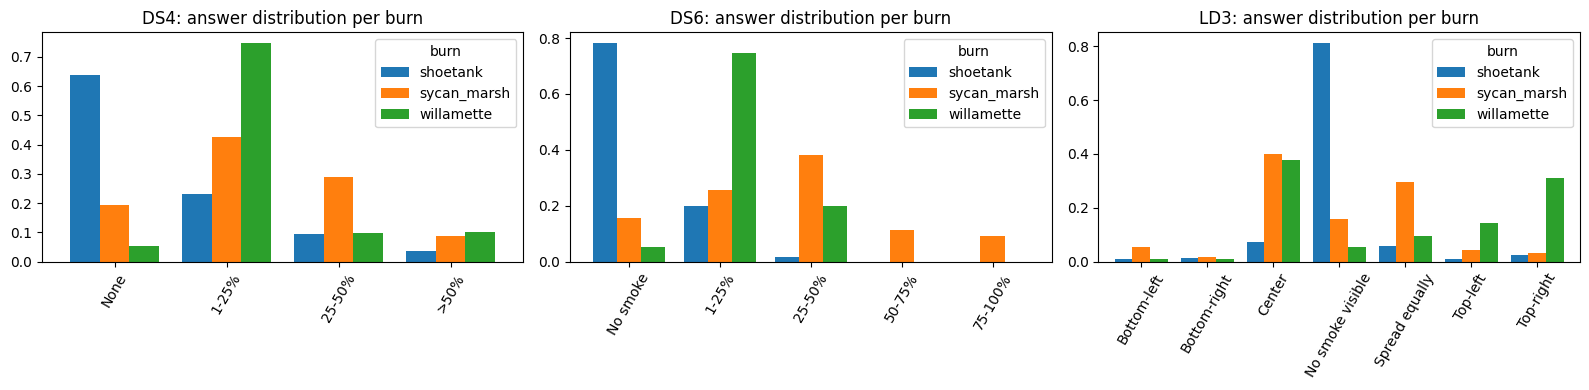

In [18]:
# 2.5 order of the percentage bins (small -> large) and the label lists
def bin_value(text):
    s = str(text).lower().strip()
    nums = [float(x) for x in re.findall(r"\d+(?:\.\d+)?", s)]
    if not nums:
        return -1.0 if re.search(r"\bnone\b|\bno\b|not visible|absent", s) else 1e9
    if re.search(r">|more than|over|above|\+|greater", s): return max(nums) + 0.5
    if re.search(r"<|less than|under|below|fewer", s): return min(nums) - 0.5
    return float(np.mean(nums))

labels, label_rank = {}, {}
for q in targets:
    found = sorted(set(o for opts in target_rows[target_rows.qtype == q].options for o in opts))
    labels[q] = sorted(found, key=bin_value) if q in ordinal else found
    label_rank[q] = {l: i for i, l in enumerate(labels[q])}
    print(q, labels[q])
print("\nCHECK: for DS4 and DS6 the list must go from the smallest to the largest coverage. If not, tell me the printed lists.")

# label distribution per burn (figure for the report)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, q in zip(axes, targets):
    g = target_rows[target_rows.qtype == q]
    t = pd.crosstab(g.gold, g.burn).reindex(labels[q]).fillna(0)
    (t / t.sum()).plot(kind="bar", ax=ax, width=0.8)
    ax.set_title(q + ": answer distribution per burn"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60)
plt.tight_layout()

# Save the figure for the report
plt.savefig(work / "figures" / "fig_label_distribution.png",
            dpi=300, bbox_inches="tight")

plt.savefig(work / "figures" / "fig_label_distribution.pdf",
            bbox_inches="tight")

plt.show()

**What stage 2 tells me:** After cleaning, I have 207,287
valid question rows across 6,097 frames. All three burn
sites are correctly identified, and each target question
(DS4, DS6, and LD3) has 6,097 samples.

The answer distributions are imbalanced and differ across
burn sites. Therefore, I will use a majority-class baseline,
selected from the training data, to check whether the models
perform better than a simple constant prediction.

## Stage 3: Select frames, split by burn, and download images

- I sample frames evenly across each burn to reduce redundancy
  between neighbouring frames.
- I use Shoetank and Sycan Marsh for training and validation,
  while keeping Willamette as an independent test site.
- I separate training and validation using blocks of neighbouring
  frames to reduce data leakage.
- These blocks are also used for grouped cross-validation
  and bootstrap confidence intervals.
- I locate and download the images corresponding to the
  selected frame references.

In [19]:
# 3.1 frames that have all three questions, then even sampling per burn
count = target_rows.groupby("frame").qtype.nunique()
good = set(count[count == len(targets)].index)
pool = target_rows[target_rows.frame.isin(good) & (target_rows.burn != "unknown")].copy()
print("frames with all three questions, per burn:", pool.groupby("burn").frame.nunique().to_dict())

def even_pick(frames, n):
    frames = sorted(frames)
    if len(frames) <= n: return frames
    idx = sorted(set(np.linspace(0, len(frames) - 1, n).round().astype(int)))
    return [frames[i] for i in idx]

parts = []
for burn, g in pool.groupby("burn"):
    parts.append(g[g.frame.isin(even_pick(g.frame.unique(), frames_per_burn))])
subset = pd.concat(parts).reset_index(drop=True)
assert test_burn in set(subset.burn), f"{test_burn} not in {set(subset.burn)}"

block_of, split_of = {}, {}
for burn, g in subset.groupby("burn"):
    for i, f in enumerate(sorted(g.frame.unique())):
        b = i // block_size
        block_of[f] = f"{burn}_{b}"
        split_of[f] = "test" if burn == test_burn else ("val" if b % 5 == 4 else "train")
subset["block"] = subset.frame.map(block_of)
subset["split"] = subset.frame.map(split_of)

# a frame must never be in two splits
assert subset.groupby("frame").split.nunique().max() == 1
print(pd.crosstab([subset.burn, subset.split], subset.qtype))
print("CHECK: test is only", test_burn, "; train/val come from the other burns.")

frames with all three questions, per burn: {'shoetank': 3540, 'sycan_marsh': 738, 'willamette': 1819}
qtype              DS4  DS6  LD3
burn        split               
shoetank    train  320  320  320
            val     80   80   80
sycan_marsh train  320  320  320
            val     80   80   80
willamette  test   400  400  400
CHECK: test is only willamette ; train/val come from the other burns.


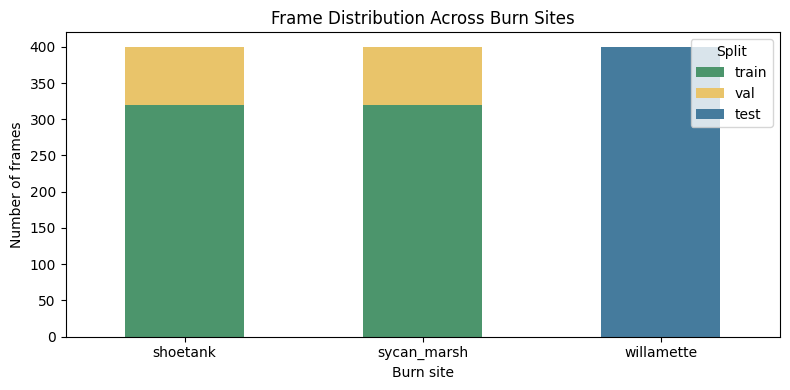

In [20]:
# Plot the dataset split by burn site
split_counts = subset.groupby(["burn", "split"]).frame.nunique().unstack(fill_value=0)
split_counts = split_counts.reindex(columns=["train", "val", "test"])

ax = split_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 4),
    color=["#4C956C", "#E9C46A", "#457B9D"]
)

ax.set_title("Frame Distribution Across Burn Sites")
ax.set_xlabel("Burn site")
ax.set_ylabel("Number of frames")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Split")

plt.tight_layout()
plt.savefig(work / "figures" / "fig_data_split.png",
            dpi=300, bbox_inches="tight")
plt.savefig(work / "figures" / "fig_data_split.pdf",
            bbox_inches="tight")
plt.show()

In [21]:
subset[["frame", "burn", "block", "split"]].drop_duplicates().to_csv(
    work / "results" / "frame_splits.csv", index=False
)

In [23]:
# 3.2 inspect the Kaggle dataset
%pip install -q kagglehub

In [24]:
import kagglehub

kaggle_dir = Path(
    kagglehub.dataset_download("caseypiere/wildfire-vqa")
)

print("Dataset folder:", kaggle_dir)

kaggle_files = [
    p for p in kaggle_dir.rglob("*") if p.is_file()
]

print("Total files:", len(kaggle_files))

print("\nFile types:")
print(pd.Series([
    p.suffix.lower() for p in kaggle_files
]).value_counts())

print("\nExample paths:")
for p in kaggle_files[:15]:
    print(p.relative_to(kaggle_dir))

100%|██████████| 12.3M/12.3M [00:00<00:00, 33.5MB/s]

Extracting files...


Dataset folder: /root/.cache/kagglehub/datasets/caseypiere/wildfire-vqa/versions/1
Total files: 9

File types:
.json    9
Name: count, dtype: int64

Example paths:
updated_updated_updated_updated_updated_vqa_response_Wilamette_Hay_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json
updated_updated_updated_updated_updated_vqa_response_Shoetank_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json
updated_updated_updated_updated_updated_vqa_response_Shoetank_NoFIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json
updated_updated_updated_updated_updated_vqa_response_Sycan_2A_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json
updated_updated_updated_updated_updated_vqa_response_Wilamette_Rathbone_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json
updated_updated_updated_updated_updated_vqa_response_Sycan_2D_FIRE_altitude_GT_hotspot_PD7_DS1_DS3_DS7_DS8_LD1_CMR4_PD8_CL1_CL1.json
updated_updated_updat

In [25]:
# Download the original FLAME 3 Sycan Marsh image subset
flame_dir = Path(kagglehub.dataset_download(
    "brycehopkins/flame-3-computer-vision-subset-sycan-marsh"
))

flame_files = [p for p in flame_dir.rglob("*") if p.is_file()]

print("Dataset folder:", flame_dir)
print("Total files:", len(flame_files))

print("\nFile types:")
print(pd.Series([
    p.suffix.lower() for p in flame_files
]).value_counts())

print("\nExample paths:")
for p in flame_files[:20]:
    print(p.relative_to(flame_dir))

100%|██████████| 6.23G/6.23G [01:37<00:00, 68.7MB/s]

Extracting files...


Dataset folder: /root/.cache/kagglehub/datasets/brycehopkins/flame-3-computer-vision-subset-sycan-marsh/versions/1
Total files: 2952

File types:
.jpg     2214
.tiff     738
Name: count, dtype: int64

Example paths:
FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Celsius TIFF/00139.TIFF
FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Celsius TIFF/00163.TIFF
FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Celsius TIFF/00612.TIFF
FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Celsius TIFF/00207.TIFF
FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Celsius TIFF/00216.TIFF
FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Celsius TIFF/00250.TIFF
FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Celsius TIFF/00354.TIFF
FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Celsius TIFF/00190.TIFF
FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Celsius TIFF/00121.TIFF
FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Celsius TIFF/00585.TIFF
FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Celsius TIFF/00476.TIFF
FLAME 3 CV Dat

In [26]:
# Inspect the image folders
folder_counts = pd.Series([
    str(p.parent.relative_to(flame_dir))
    for p in flame_files
]).value_counts()

print(folder_counts.to_string())

print("\nAnnotation path examples:")
sycan = subset[subset.burn == "sycan_marsh"]

for p in sycan.frame.unique()[:8]:
    print(p)

FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Celsius TIFF       622
FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Raw JPG            622
FLAME 3 CV Dataset (Sycan Marsh)/Fire/RGB/Corrected FOV          622
FLAME 3 CV Dataset (Sycan Marsh)/Fire/RGB/Raw                    622
FLAME 3 CV Dataset (Sycan Marsh)/No Fire/Thermal/Celsius TIFF    116
FLAME 3 CV Dataset (Sycan Marsh)/No Fire/Thermal/Raw JPG         116
FLAME 3 CV Dataset (Sycan Marsh)/No Fire/RGB/Corrected FOV       116
FLAME 3 CV Dataset (Sycan Marsh)/No Fire/RGB/Raw                 116

Annotation path examples:
/home/mhabibp/Downloads/flame3333/Flame 3 Computer Vision Sets/Sycan/Sycan 2A/Images/Fire/RGB/Corrected FOV/00001.JPG
/home/mhabibp/Downloads/flame3333/Flame 3 Computer Vision Sets/Sycan/Sycan 2A/Images/Fire/RGB/Corrected FOV/00003.JPG
/home/mhabibp/Downloads/flame3333/Flame 3 Computer Vision Sets/Sycan/Sycan 2A/Images/Fire/RGB/Corrected FOV/00005.JPG
/home/mhabibp/Downloads/flame3333/Flame 3 Computer Vision Sets/Syca

In [27]:
# Compare annotation and downloaded image numbering
sycan_all = target_rows[
    target_rows.burn == "sycan_marsh"
].drop_duplicates("frame").copy()

sycan_all["sequence"] = sycan_all.frame.str.extract(
    r"(Sycan 2[A-Z])"
)

sycan_all["condition"] = sycan_all.frame.apply(
    lambda p: Path(p).parent.parent.parent.name
)

sycan_all["filename"] = sycan_all.frame.apply(
    lambda p: Path(p).name
)

print("Annotation sequences:")
print(sycan_all.groupby(["sequence", "condition"]).filename.agg(
    ["count", "min", "max"]
))

print("\nDownloaded RGB folders:")
rgb_files = [
    p for p in flame_files
    if p.parent.name == "Corrected FOV"
]

for folder in sorted(set(p.parent for p in rgb_files)):
    names = sorted(p.name for p in rgb_files if p.parent == folder)
    print(folder.relative_to(flame_dir))
    print("Count:", len(names), "| First:", names[0], "| Last:", names[-1])

print("\nRepeated annotation filenames:",
      sycan_all.filename.duplicated().sum())

Annotation sequences:
                    count        min        max
sequence condition                             
Sycan 2A Fire         364  00001.JPG  00364.JPG
Sycan 2D Fire         258  00001.JPG  00258.JPG
         No Fire      116  00001.JPG  00116.JPG

Downloaded RGB folders:
FLAME 3 CV Dataset (Sycan Marsh)/Fire/RGB/Corrected FOV
Count: 622 | First: 00001.JPG | Last: 00622.JPG
FLAME 3 CV Dataset (Sycan Marsh)/No Fire/RGB/Corrected FOV
Count: 116 | First: 00001.JPG | Last: 00116.JPG

Repeated annotation filenames: 374


In [28]:
# Verify Sycan image numbering using thermal statistics

sycan_all = target_rows[
    target_rows.burn == "sycan_marsh"
].drop_duplicates("frame").copy()

thermal_files = {
    (p.parent.parent.parent.name, p.stem): p
    for p in flame_files
    if p.suffix.lower() in [".tif", ".tiff"]
}

def check_mapping(order):
    results = []

    for _, row in sycan_all.iterrows():
        frame = row.frame
        number = int(Path(frame).stem)
        condition = row["frame"].split("/RGB/")[0].split("/")[-1]

        if condition == "Fire":
            if order == "2A_first" and "Sycan 2D" in frame:
                number += 364
            elif order == "2D_first" and "Sycan 2A" in frame:
                number += 258

        path = thermal_files.get(
            (condition, f"{number:05d}")
        )

        if path is None:
            continue

        temp = row["temp"]
        if not isinstance(temp, dict):
            continue

        with Image.open(path) as im:
            arr = np.asarray(im, dtype=np.float32)

        arr = arr[np.isfinite(arr)]

        if arr.size == 0:
            continue

        results.append({
            "condition": condition,
            "mean_error": abs(arr.mean() - float(temp["mean"])),
            "max_error": abs(arr.max() - float(temp["max"]))
        })

    result = pd.DataFrame(results)

    print("\nMapping:", order)
    print("Compared frames:", len(result))

    if not result.empty:
        print(result.groupby("condition")[
            ["mean_error", "max_error"]
        ].median())

check_mapping("2A_first")
check_mapping("2D_first")


Mapping: 2A_first
Compared frames: 738
           mean_error   max_error
condition                        
Fire         8.068386  104.609665
No Fire      4.051691    8.701594

Mapping: 2D_first
Compared frames: 738
           mean_error   max_error
condition                        
Fire         7.302190  104.373047
No Fire      4.051691    8.701594


In [29]:
# Inspect temperature values in the annotation and TIFF image
row = sycan_all.iloc[0]

print("Annotation frame:", row.frame)
print("Annotation temperature:", row["temp"])

path = thermal_files[("Fire", "00001")]

with Image.open(path) as im:
    arr = np.array(im)

print("\nTIFF path:", path)
print("Shape:", arr.shape)
print("Data type:", arr.dtype)
print("Minimum:", np.nanmin(arr))
print("Maximum:", np.nanmax(arr))
print("Mean:", np.nanmean(arr))
print("Std:", np.nanstd(arr))

Annotation frame: /home/mhabibp/Downloads/flame3333/Flame 3 Computer Vision Sets/Sycan/Sycan 2A/Images/Fire/RGB/Corrected FOV/00001.JPG
Annotation temperature: {'min': -22.789, 'max': 608.69, 'mean': 15.979, 'std': 31.33, 'top3_mean': 119.54, 'pct_over_200': 0.536, 'pct_over_400': 0.241}

TIFF path: /root/.cache/kagglehub/datasets/brycehopkins/flame-3-computer-vision-subset-sycan-marsh/versions/1/FLAME 3 CV Dataset (Sycan Marsh)/Fire/Thermal/Celsius TIFF/00001.TIFF
Shape: (512, 640)
Data type: float32
Minimum: -22.788565
Maximum: 573.0159
Mean: 12.966687
Std: 41.389927


In [30]:
# Extract temperature statistics from the downloaded TIFF images
thermal_stats = []

for (condition, name), path in tqdm(thermal_files.items()):
    with Image.open(path) as im:
        arr = np.asarray(im, dtype=np.float32)

    arr = arr[np.isfinite(arr)]

    thermal_stats.append({
        "condition": condition,
        "filename": name,
        "min": arr.min(),
        "max": arr.max(),
        "mean": arr.mean(),
        "std": arr.std()
    })

thermal_stats = pd.DataFrame(thermal_stats)

print(thermal_stats.head())
print("Total thermal frames:", len(thermal_stats))

# Save statistics to avoid recalculating them
thermal_stats.to_csv(
    work / "cache" / "sycan_thermal_stats.csv",
    index=False
)

  0%|          | 0/738 [00:00<?, ?it/s]

  condition filename        min         max       mean        std
0      Fire    00139 -22.788565  542.165283  15.213229  26.615498
1      Fire    00163  -2.123938  577.541687  15.230121  23.605202
2      Fire    00612 -22.788565  518.249756  24.604986  33.162582
3      Fire    00207 -12.836248  608.689758  17.604441  35.602032
4      Fire    00216 -22.788565  482.395966   4.859296  15.055748
Total thermal frames: 738


In [31]:
# Find the closest temperature matches
reference = sycan_all.iloc[0]["temp"]

comparison = thermal_stats[
    thermal_stats.condition == "Fire"
].copy()

for col in ["min", "max", "mean", "std"]:
    comparison[col + "_error"] = abs(
        comparison[col] - reference[col]
    )

comparison["score"] = (
    comparison["min_error"] +
    comparison["max_error"] +
    comparison["mean_error"] +
    comparison["std_error"]
)

print(comparison.sort_values("score").head(10).to_string(index=False))

condition filename        min        max      mean       std  min_error  max_error  mean_error  std_error    score
     Fire    00289 -22.788565 608.689758 15.978557 31.330181   0.000435   0.000244    0.000443   0.000181 0.001304
     Fire    00435 -22.788565 608.689758 16.854069 31.082027   0.000435   0.000244    0.875069   0.247972 1.123720
     Fire    00519 -22.788565 608.689758 15.051229 31.767048   0.000435   0.000244    0.927771   0.437048 1.365498
     Fire    00516 -22.788565 608.689758 14.861876 31.746952   0.000435   0.000244    1.117125   0.416952 1.534756
     Fire    00354 -22.788565 608.689758 16.051052 29.763821   0.000435   0.000244    0.072052   1.566179 1.638910
     Fire    00206 -22.788565 608.689758 17.641804 31.296049   0.000435   0.000244    1.662804   0.033951 1.697433
     Fire    00155 -22.788565 608.689758 14.832889 31.936766   0.000435   0.000244    1.146111   0.606766 1.753556
     Fire    00409 -22.788565 608.689758 17.866142 31.559875   0.000435   0.0002

In [32]:
# Match annotations with TIFF images using temperature statistics
matches = []
stats_cols = ["min", "max", "mean", "std"]

for _, row in tqdm(sycan_all.iterrows(), total=len(sycan_all)):
    condition = Path(row.frame).parent.parent.parent.name
    candidates = thermal_stats[
        thermal_stats.condition == condition
    ].copy()

    reference = row["temp"]

    if not isinstance(reference, dict):
        continue

    ref = np.array([reference[c] for c in stats_cols])
    values = candidates[stats_cols].to_numpy()

    errors = np.abs(values - ref)
    valid = candidates.loc[(errors < 0.001).all(axis=1)]

    if len(valid) == 1:
        best = valid.iloc[0]

        matches.append({
            "frame": row.frame,
            "condition": condition,
            "kaggle_id": best.filename,
            "score": float(
                np.abs(best[stats_cols].astype(float).values - ref).sum()
            )
        })

mapping = pd.DataFrame(matches)

print("Total annotation frames:", len(sycan_all))
print("Successfully matched:", len(mapping))
print("Unmatched:", len(sycan_all) - len(mapping))

if not mapping.empty:
    print("Duplicate image assignments:",
          mapping.duplicated(["condition", "kaggle_id"]).sum())

    print("\nMatches per condition:")
    print(mapping.condition.value_counts())

    print("\nMatching error statistics:")
    print(mapping.score.describe())

    print("\nExample matches:")
    print(mapping.head().to_string(index=False))

    mapping.to_csv(
        work / "cache" / "sycan_image_mapping.csv",
        index=False
    )

  0%|          | 0/738 [00:00<?, ?it/s]

Total annotation frames: 738
Successfully matched: 738
Unmatched: 0
Duplicate image assignments: 0

Matches per condition:
condition
Fire       622
No Fire    116
Name: count, dtype: int64

Matching error statistics:
count    738.000000
mean       0.001058
std        0.000290
min        0.000326
25%        0.000862
50%        0.001049
75%        0.001280
max        0.001770
Name: score, dtype: float64

Example matches:
                                                                                                                frame condition kaggle_id    score
/home/mhabibp/Downloads/flame3333/Flame 3 Computer Vision Sets/Sycan/Sycan 2A/Images/Fire/RGB/Corrected FOV/00001.JPG      Fire     00289 0.001302
/home/mhabibp/Downloads/flame3333/Flame 3 Computer Vision Sets/Sycan/Sycan 2A/Images/Fire/RGB/Corrected FOV/00002.JPG      Fire     00435 0.000773
/home/mhabibp/Downloads/flame3333/Flame 3 Computer Vision Sets/Sycan/Sycan 2A/Images/Fire/RGB/Corrected FOV/00003.JPG      Fire     0020

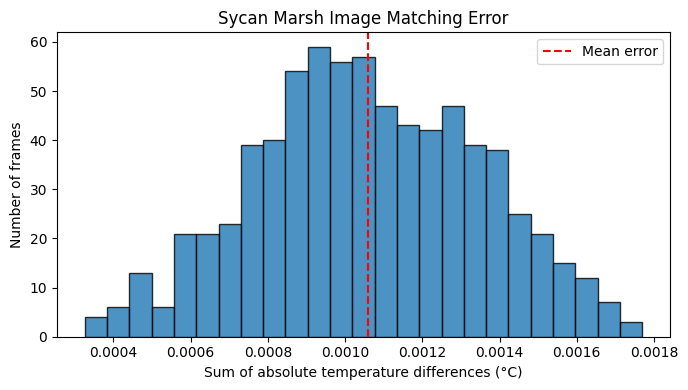

In [33]:
# Plot the distribution of image matching errors
plt.figure(figsize=(7, 4))

plt.hist(mapping.score, bins=25, edgecolor="black", alpha=0.8)

plt.axvline(
    mapping.score.mean(),
    color="red",
    linestyle="--",
    label="Mean error"
)

plt.xlabel("Sum of absolute temperature differences (°C)")
plt.ylabel("Number of frames")
plt.title("Sycan Marsh Image Matching Error")
plt.legend()
plt.tight_layout()

plt.savefig(work / "figures" / "fig_image_matching_error.png",
            dpi=300, bbox_inches="tight")

plt.savefig(work / "figures" / "fig_image_matching_error.pdf",
            bbox_inches="tight")

plt.show()

In [34]:
# Locate RGB images corresponding to the matched TIFF frames
rgb_lookup = {
    (p.parent.parent.parent.name, p.stem): str(p)
    for p in flame_files
    if p.parent.name == "Corrected FOV"
}

mapping["rgb_local"] = [
    rgb_lookup.get((condition, image_id))
    for condition, image_id in zip(
        mapping.condition, mapping.kaggle_id
    )
]

print("Matched RGB images:", mapping.rgb_local.notna().sum())
print("Missing RGB images:", mapping.rgb_local.isna().sum())
print("Duplicate RGB paths:", mapping.rgb_local.duplicated().sum())

mapping.to_csv(
    work / "cache" / "sycan_image_mapping.csv",
    index=False
)

Matched RGB images: 738
Missing RGB images: 0
Duplicate RGB paths: 0


**Image matching:** The public Sycan Marsh dataset uses
different image numbering from the WildFireVQA annotations.
I reconstructed the correspondence using four radiometric
temperature statistics: minimum, maximum, mean, and standard
deviation.

All 738 annotation frames were uniquely matched to thermal
TIFF images, with no unmatched frames or duplicate assignments.
The mean summed absolute matching error was 0.001058°C.

In [35]:
# 3.2 Save the matched Sycan RGB images to Google Drive

sycan_subset = subset[
    subset.burn == "sycan_marsh"
].copy()

rgb_map = mapping.set_index("frame")["rgb_local"].to_dict()

saved = {}

for frame in tqdm(sycan_subset.frame.unique()):
    source = rgb_map.get(frame)

    if source is None or not Path(source).is_file():
        continue

    relative = Path(source).relative_to(flame_dir)
    filename = re.sub(r"[^A-Za-z0-9_.-]", "_", str(relative))
    out = work / "images" / filename

    with Image.open(source) as im:
        im = im.convert("RGB")
        im.thumbnail((512, 512))
        im.save(out, quality=92)

    saved[frame] = str(out)

# Attach available image paths without removing other burns
subset["img_local"] = subset.frame.map(saved)

print("Saved Sycan images:", len(saved))
print("Total selected frames:", subset.frame.nunique())

print("\nImage availability per burn:")
print(
    subset.drop_duplicates("frame")
    .groupby("burn").img_local.count()
)

subset.to_pickle(work / "cache" / "subset_partial.pkl")

  0%|          | 0/400 [00:00<?, ?it/s]

Saved Sycan images: 400
Total selected frames: 1200

Image availability per burn:
burn
shoetank         0
sycan_marsh    400
willamette       0
Name: img_local, dtype: int64


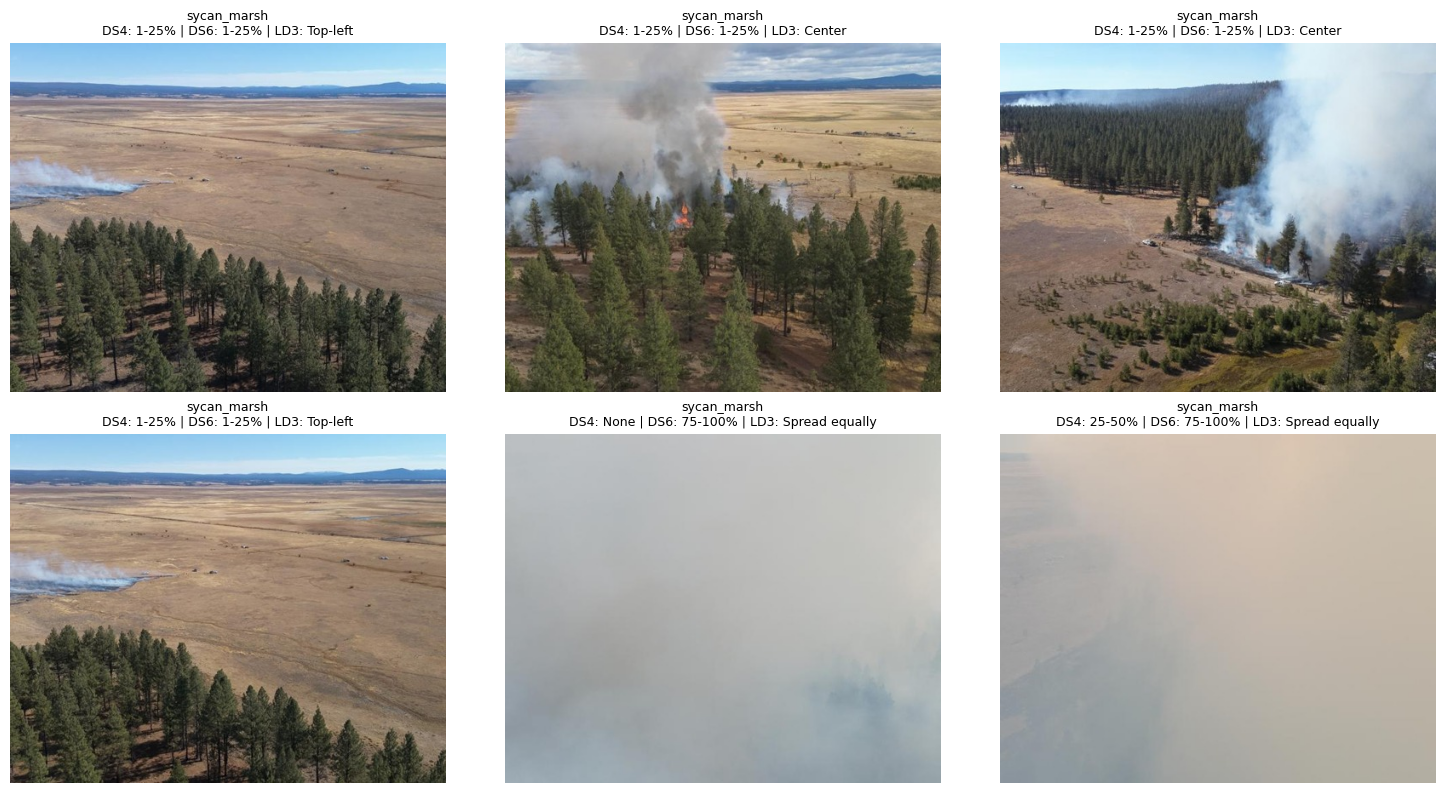

In [37]:
# 3.3 Visual inspection of images and ground-truth answers

available = subset[subset.img_local.notna()]
sample = available.drop_duplicates("frame").sample(
    n=min(6, available.frame.nunique()), random_state=42
)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax in axes.ravel():
    ax.axis("off")

for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    with Image.open(r.img_local) as im:
        ax.imshow(im)

    gold = subset[subset.frame == r.frame].set_index("qtype").gold.to_dict()

    ax.set_title(
        r.burn + "\n" +
        " | ".join(f"{k}: {v}" for k, v in gold.items()),
        fontsize=9
    )

plt.tight_layout()

# Save the figure for the research report
plt.savefig(work / "figures" / "fig_samples_sycan.png",
            dpi=300, bbox_inches="tight")

plt.savefig(work / "figures" / "fig_samples_sycan.pdf",
            bbox_inches="tight")

plt.show()

## Stage 4: Evaluation metrics and baseline performance

Before evaluating the models, I establish two simple
baselines:

- Majority baseline: Always predict the most common
  answer from the training data.
- Random baseline: Randomly select one of the available
  answer options.

I use the following evaluation metrics:

- Accuracy: Percentage of correct predictions.
- Within-one-bin accuracy: Predictions that are correct
  or at most one coverage bin away.
- Mean bin error: Average distance between the predicted
  and ground-truth coverage bins.

The ordinal metrics apply only to DS4 and DS6.
For invalid or unparseable predictions, I assign the
maximum possible bin error.

I estimate confidence intervals using block bootstrap
sampling to account for dependence between neighbouring
frames.

In [38]:
# 4.1 Prediction store and evaluation metrics

subset = pd.read_pickle(work / "cache" / "subset_partial.pkl")
block_of = dict(zip(subset.frame, subset.block))

preds_file = work / "results" / "all_preds_partial.csv"

all_preds = (
    pd.read_csv(preds_file, keep_default_na=False)
    if preds_file.exists() else pd.DataFrame()
)

def save_preds(df, method, fold):
    global all_preds

    df = df[["frame", "qtype", "gold", "pred"]].copy()
    df["method"] = method
    df["fold"] = fold

    if len(all_preds):
        all_preds = all_preds[
            ~((all_preds.method == method) &
              (all_preds.fold == fold))
        ]

    all_preds = pd.concat([all_preds, df], ignore_index=True)
    all_preds.to_csv(preds_file, index=False)


def add_scores(p):
    p = p.copy()
    p["block"] = p.frame.map(block_of)
    p["right"] = (p.pred == p.gold).astype(float)

    # Ordinal metrics apply only to DS4 and DS6
    p["bin_error"] = np.nan
    p["within_one"] = np.nan

    for q in ordinal:
        mask = p.qtype == q

        gold_rank = p.loc[mask, "gold"].map(label_rank[q])
        pred_rank = p.loc[mask, "pred"].map(label_rank[q])

        diff = (gold_rank - pred_rank).abs()
        valid = pred_rank.notna()

        diff = diff.fillna(len(labels[q]) - 1)

        p.loc[mask, "bin_error"] = diff
        p.loc[mask, "within_one"] = (
            (diff <= 1) & valid
        ).astype(float)

    return p


def ci(d, col, n_boot=1000):
    # Bootstrap over blocks of neighbouring frames
    if d.empty:
        return np.nan, np.nan, np.nan

    assert d.block.notna().all(), "Missing block assignments"

    g = d.groupby("block")[col].agg(["sum", "count"])
    g = g[g["count"] > 0]

    if g.empty:
        return np.nan, np.nan, np.nan

    s, c = g["sum"].values, g["count"].values

    idx = np.random.default_rng(42).integers(
        0, len(g), (n_boot, len(g))
    )

    boots = s[idx].sum(1) / c[idx].sum(1)

    return (
        s.sum() / c.sum(),
        np.percentile(boots, 2.5),
        np.percentile(boots, 97.5)
    )


def fmt(t, pct=True):
    m, lo, hi = t

    if np.isnan(m):
        return "N/A"

    if pct:
        return f"{100*m:.1f} [{100*lo:.1f}, {100*hi:.1f}]"

    return f"{m:.2f} [{lo:.2f}, {hi:.2f}]"


def show_table(methods, fold):
    rows = []

    for m in methods:
        if all_preds.empty:
            continue

        d = all_preds[
            (all_preds.method == m) &
            (all_preds.fold == fold)
        ]

        if d.empty:
            continue

        d = add_scores(d)
        row = {"method": m}

        for q in targets:
            dq = d[d.qtype == q]
            row[q + " acc"] = fmt(ci(dq, "right"))

            if q in ordinal:
                row[q + " within1"] = fmt(ci(dq, "within_one"))
                row[q + " bin err"] = fmt(
                    ci(dq, "bin_error"), pct=False
                )

        rows.append(row)

    return pd.DataFrame(rows)


pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)

print("Scoring functions ready.")
print("Stored predictions:", len(all_preds))
print("Total frames:", subset.frame.nunique())
print("Available images:",
      subset.drop_duplicates("frame").img_local.notna().sum())

print("\nQuestions per split:")
print(subset.split.value_counts())

Scoring functions ready.
Stored predictions: 0
Total frames: 1200
Available images: 400

Questions per split:
split
train    1920
test     1200
val       480
Name: count, dtype: int64


In [40]:
# 4.2 floor: majority and random on the main fold
train_part = subset[subset.split == "train"]
test_part = subset[subset.split == "test"]
rng = np.random.default_rng(0)
majority_rows, random_rows = [], []
for r in test_part.itertuples():
    common = train_part[train_part.qtype == r.qtype].gold.mode()[0]
    majority_rows.append(dict(frame=r.frame, qtype=r.qtype, gold=r.gold, pred=common if common in r.options else r.options[0]))
    random_rows.append(dict(frame=r.frame, qtype=r.qtype, gold=r.gold, pred=r.options[rng.integers(len(r.options))]))
save_preds(pd.DataFrame(majority_rows), "Majority", test_burn)
save_preds(pd.DataFrame(random_rows), "Random", test_burn)
print(show_table(["Random", "Majority"], test_burn).to_string(index=False))
print("\nCHECK: these are the numbers every method has to beat. Write them down.")

  method           DS4 acc       DS4 within1       DS4 bin err           DS6 acc       DS6 within1       DS6 bin err           LD3 acc
  Random 23.2 [19.2, 27.5] 69.8 [65.0, 74.2] 1.10 [1.03, 1.18] 20.0 [15.8, 24.2] 59.0 [55.0, 62.8] 1.38 [1.30, 1.47] 14.5 [11.0, 17.8]
Majority   5.5 [0.0, 12.5] 80.5 [68.8, 91.3] 1.24 [1.06, 1.45]   5.5 [0.0, 12.5] 80.5 [70.7, 89.3] 1.14 [1.02, 1.25]   5.5 [0.0, 12.5]

CHECK: these are the numbers every method has to beat. Write them down.


In [41]:
# Inspect the most frequent training answer for each question
for q in targets:
    common = train_part[train_part.qtype == q].gold.mode()[0]
    print(q, "majority answer:", common)

DS4 majority answer: None
DS6 majority answer: No smoke
LD3 majority answer: No smoke visible


In [42]:
# Save baseline results for the research report
baseline_table = show_table(["Random", "Majority"], test_burn)

baseline_table.to_csv(
    work / "results" / "baseline_results.csv",
    index=False
)

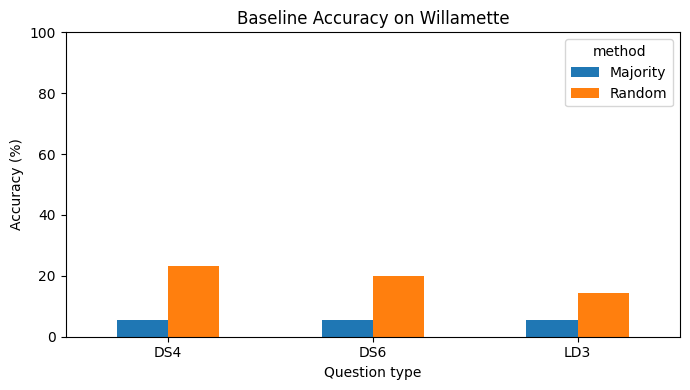

In [43]:
# Compare baseline accuracy across the three questions
baseline_scores = add_scores(
    all_preds[
        all_preds.method.isin(["Random", "Majority"]) &
        (all_preds.fold == test_burn)
    ]
)

baseline_acc = (
    baseline_scores.groupby(["qtype", "method"]).right.mean()
    .unstack() * 100
)

baseline_acc = baseline_acc.reindex(list(targets))

ax = baseline_acc.plot(kind="bar", figsize=(7, 4))

ax.set_title("Baseline Accuracy on Willamette")
ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Question type")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.savefig(work / "figures" / "fig_baseline_performance.png",
            dpi=300, bbox_inches="tight")

plt.savefig(work / "figures" / "fig_baseline_performance.pdf",
            bbox_inches="tight")

plt.show()

**Observation:** The preliminary majority baseline performs
poorly on Willamette compared with the random baseline.
This suggests a substantial difference in answer distributions
between the training and test sites. These baselines provide
reference scores for evaluating the adapted models.

## Stage 5: M1 – Frozen image features and lightweight prediction heads

I use frozen pretrained image encoders to extract RGB image
features. A logistic regression classifier predicts the answer
category for each target question.

For DS4 and DS6, I also use ridge regression to predict the
ordinal bin index, rounded and clipped to a valid bin.

The regularization strength is selected using grouped
cross-validation over training blocks.

The planned evaluation uses three leave-one-burn-out folds.
Currently, only Sycan Marsh imagery has been obtained and
matched to the annotations. Full cross-site evaluation requires
the remaining two burn sites.

In [45]:
# 5.1 Extract frozen image features

from transformers import AutoModel, AutoImageProcessor, CLIPModel, CLIPProcessor

# Use only frames with available images
frames_df = (
    subset[subset.img_local.notna()]
    .drop_duplicates("frame")[["frame", "img_local", "burn", "block"]]
    .reset_index(drop=True)
)

assert len(frames_df) > 0, "No images available"

print("Available frames:", len(frames_df))
print(frames_df.burn.value_counts())

@torch.no_grad()
def get_features(name, batch=16):

    npy = work / "cache" / f"feat_{name}_partial.npy"
    idx = work / "cache" / f"feat_{name}_partial_frames.csv"

    # Reuse features if the frame list is unchanged
    if npy.exists() and idx.exists():
        if list(pd.read_csv(idx).frame) == list(frames_df.frame):
            arr = np.load(npy)
            if len(arr) == len(frames_df):
                return arr

    if name == "dinov2":
        proc = AutoImageProcessor.from_pretrained("facebook/dinov2-base")
        net = AutoModel.from_pretrained(
            "facebook/dinov2-base"
        ).half().cuda().eval()
    else:
        proc = CLIPProcessor.from_pretrained(
            "openai/clip-vit-base-patch16"
        )
        net = CLIPModel.from_pretrained(
            "openai/clip-vit-base-patch16"
        ).half().cuda().eval()

    out = []

    for i in tqdm(range(0, len(frames_df), batch), desc=name):

        ims = []
        for p in frames_df.img_local.iloc[i:i + batch]:
            with Image.open(p) as im:
                ims.append(im.convert("RGB"))

        x = proc(
            images=ims, return_tensors="pt"
        )["pixel_values"].cuda().half()

        if name == "dinov2":
            h = net(pixel_values=x).last_hidden_state

            # Combine CLS token and average patch features
            f = torch.cat(
                [h[:, 0], h[:, 1:].mean(1)], dim=1
            )
        else:
            f = net.get_image_features(pixel_values=x)

            if not isinstance(f, torch.Tensor):
                f = f.pooler_output

            f = torch.nn.functional.normalize(f.float(), dim=-1)

        out.append(f.float().cpu().numpy())

    del net
    gc.collect()
    torch.cuda.empty_cache()

    arr = np.concatenate(out)

    assert np.isfinite(arr).all(), "Invalid feature values"

    # Save extracted features and frame identifiers
    np.save(npy, arr)
    frames_df[["frame"]].to_csv(idx, index=False)

    return arr

features = {
    name: get_features(name)
    for name in ["dinov2", "clip"]
}

print("\nExtracted feature shapes:")
print({k: v.shape for k, v in features.items()})

Available frames: 400
burn
sycan_marsh    400
Name: count, dtype: int64


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

dinov2:   0%|          | 0/25 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

... (7 outputs left out)

clip:   0%|          | 0/25 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            


Extracted feature shapes:
{'dinov2': (400, 1536), 'clip': (400, 512)}


In [46]:
# 5.2 Train lightweight prediction heads on Sycan Marsh

from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, GridSearchCV

row_of = {f: i for i, f in enumerate(frames_df.frame)}

# Use only frames with extracted features
pilot_data = subset[
    (subset.burn == "sycan_marsh") &
    subset.frame.isin(row_of)
].copy()

pilot_fold = "sycan_pilot"

def train_pilot_heads(backbone):
    X = features[backbone]
    lr_out, ridge_out = [], []

    for q in targets:
        d = pilot_data[pilot_data.qtype == q]

        tr = d[d.split == "train"]
        te = d[d.split == "val"]

        Xtr = X[[row_of[f] for f in tr.frame]]
        Xte = X[[row_of[f] for f in te.frame]]

        groups = tr.block.values
        cv = GroupKFold(n_splits=4)

        print(f"\n{backbone} | {q}")
        print("Train:", len(tr), "| Validation:", len(te))

        # Logistic regression classifier
        clf = GridSearchCV(
            make_pipeline(
                StandardScaler(),
                LogisticRegression(max_iter=3000)
            ),
            {"logisticregression__C": [0.001, 0.01, 0.1, 1]},
            cv=cv,
            scoring="accuracy",
            n_jobs=-1
        )

        clf.fit(Xtr, tr.gold.values, groups=groups)

        print("Best LR parameters:", clf.best_params_)
        print("LR CV accuracy:", round(clf.best_score_, 4))

        probs = clf.predict_proba(Xte)
        classes = list(clf.classes_)

        for r, p in zip(te.itertuples(), probs):
            options = [
                (p[classes.index(o)], o)
                for o in r.options if o in classes
            ]

            pred = max(options)[1] if options else r.options[0]

            lr_out.append(dict(
                frame=r.frame,
                qtype=q,
                gold=r.gold,
                pred=pred
            ))

        # Ridge regression for ordinal questions
        if q in ordinal:
            y = np.array([
                label_rank[q][g] for g in tr.gold
            ], dtype=float)

            reg = GridSearchCV(
                make_pipeline(StandardScaler(), Ridge()),
                {"ridge__alpha": [10, 100, 1000, 10000]},
                cv=cv,
                scoring="neg_mean_absolute_error",
                n_jobs=-1
            )

            reg.fit(Xtr, y, groups=groups)

            print("Best Ridge parameters:", reg.best_params_)
            print("Ridge CV MAE:", round(-reg.best_score_, 4))

            for r, v in zip(te.itertuples(), reg.predict(Xte)):
                ranks = [label_rank[q][o] for o in r.options]
                nearest = min(ranks, key=lambda k: abs(k - v))

                ridge_out.append(dict(
                    frame=r.frame,
                    qtype=q,
                    gold=r.gold,
                    pred=labels[q][nearest]
                ))

    return pd.DataFrame(lr_out), pd.DataFrame(ridge_out)


for backbone in ["dinov2", "clip"]:
    a, b = train_pilot_heads(backbone)

    save_preds(a, f"M1-{backbone}-LR", pilot_fold)
    save_preds(b, f"M1-{backbone}-Ridge", pilot_fold)

print("\nPilot training completed.")

print(show_table([
    "M1-dinov2-LR",
    "M1-dinov2-Ridge",
    "M1-clip-LR",
    "M1-clip-Ridge"
], pilot_fold).to_string(index=False))


dinov2 | DS4
Train: 320 | Validation: 80
Best LR parameters: {'logisticregression__C': 0.01}
LR CV accuracy: 0.7844
Best Ridge parameters: {'ridge__alpha': 1000}
Ridge CV MAE: 0.354

dinov2 | DS6
Train: 320 | Validation: 80
Best LR parameters: {'logisticregression__C': 0.01}
LR CV accuracy: 0.8312
Best Ridge parameters: {'ridge__alpha': 100}
Ridge CV MAE: 0.2826

dinov2 | LD3
Train: 320 | Validation: 80
Best LR parameters: {'logisticregression__C': 0.001}
LR CV accuracy: 0.6812

clip | DS4
Train: 320 | Validation: 80
Best LR parameters: {'logisticregression__C': 0.01}
LR CV accuracy: 0.7938
Best Ridge parameters: {'ridge__alpha': 100}
Ridge CV MAE: 0.3893

clip | DS6
Train: 320 | Validation: 80
Best LR parameters: {'logisticregression__C': 0.01}
LR CV accuracy: 0.8125
Best Ridge parameters: {'ridge__alpha': 100}
Ridge CV MAE: 0.3051

clip | LD3
Train: 320 | Validation: 80
Best LR parameters: {'logisticregression__C': 0.001}
LR CV accuracy: 0.6875

Pilot training completed.
         me

In [47]:
# 5.3 Evaluate M1 on the Sycan Marsh pilot split

tr = pilot_data[pilot_data.split == "train"]
te = pilot_data[pilot_data.split == "val"]

rng = np.random.default_rng(42)

majority_rows, random_rows = [], []

for q in targets:
    common = tr[tr.qtype == q].gold.mode()[0]

    print(q, "| Majority answer:", common)

    for r in te[te.qtype == q].itertuples():
        majority_rows.append({
            "frame": r.frame,
            "qtype": q,
            "gold": r.gold,
            "pred": common
        })

        random_rows.append({
            "frame": r.frame,
            "qtype": q,
            "gold": r.gold,
            "pred": rng.choice(r.options)
        })

save_preds(
    pd.DataFrame(majority_rows),
    "Majority", pilot_fold
)

save_preds(
    pd.DataFrame(random_rows),
    "Random", pilot_fold
)

methods = [
    "Random",
    "Majority",
    "M1-dinov2-LR",
    "M1-dinov2-Ridge",
    "M1-clip-LR",
    "M1-clip-Ridge"
]

# Compare all methods on the same validation frames
pilot_table = show_table(methods, pilot_fold)

print("\nSycan Marsh pilot results (mean [95% CI]):")
print(pilot_table.to_string(index=False))

pilot_table.to_csv(
    work / "results" / "m1_pilot_results.csv",
    index=False
)

DS4 | Majority answer: 1-25%
DS6 | Majority answer: 25-50%
LD3 | Majority answer: Center

Sycan Marsh pilot results (mean [95% CI]):
         method           DS4 acc        DS4 within1       DS4 bin err           DS6 acc          DS6 within1       DS6 bin err           LD3 acc
         Random 26.2 [18.8, 33.8]  57.5 [48.8, 65.0] 1.29 [1.12, 1.46] 22.5 [12.5, 31.2]    48.8 [33.8, 66.2] 1.57 [1.24, 1.89]   7.5 [0.0, 15.0]
       Majority  17.5 [3.8, 33.8]  86.2 [67.5, 97.5] 0.96 [0.70, 1.25] 30.0 [12.5, 46.2]    61.3 [25.0, 92.6] 1.09 [0.61, 1.63] 30.0 [10.0, 52.5]
   M1-dinov2-LR 75.0 [56.2, 91.2] 95.0 [85.0, 100.0] 0.35 [0.10, 0.63] 78.8 [68.8, 88.8] 100.0 [100.0, 100.0] 0.21 [0.11, 0.31] 80.0 [68.8, 91.2]
M1-dinov2-Ridge 71.2 [48.8, 92.5] 95.0 [85.0, 100.0] 0.35 [0.07, 0.65] 75.0 [67.5, 82.5] 100.0 [100.0, 100.0] 0.25 [0.17, 0.33]               N/A
     M1-clip-LR 73.8 [52.5, 92.5] 93.8 [81.2, 100.0] 0.39 [0.07, 0.75] 76.2 [61.3, 90.0] 100.0 [100.0, 100.0] 0.24 [0.10, 0.39] 82.5 [68.

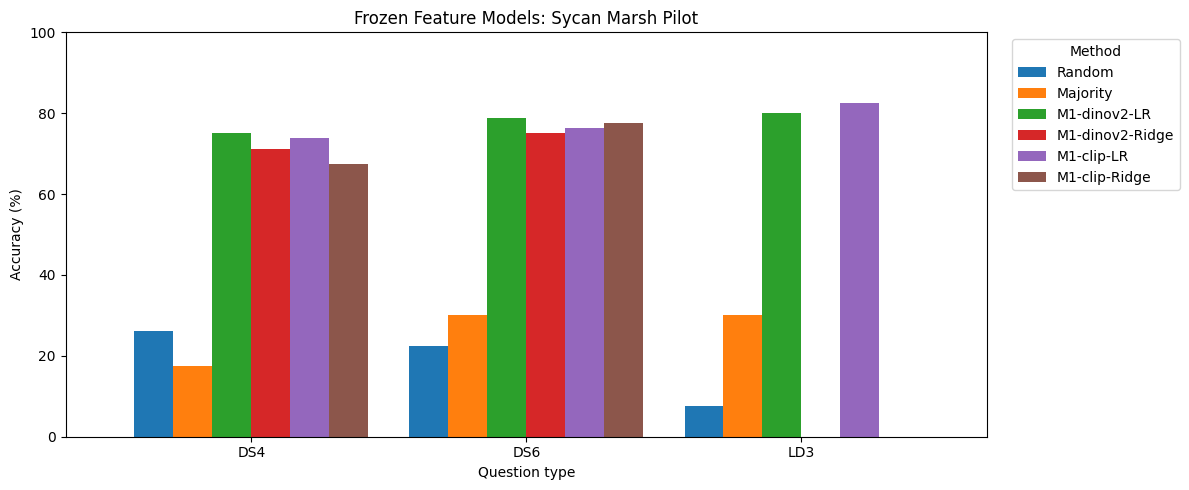

In [48]:
# Compare the pilot models and baselines
p = add_scores(
    all_preds[
        (all_preds.fold == pilot_fold) &
        all_preds.method.isin(methods)
    ]
)

acc = p.groupby(["qtype", "method"]).right.mean().unstack() * 100
acc = acc.reindex(index=list(targets), columns=methods)

ax = acc.plot(kind="bar", figsize=(12, 5), width=0.85)

ax.set_title("Frozen Feature Models: Sycan Marsh Pilot")
ax.set_xlabel("Question type")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Method", loc="upper left",
          bbox_to_anchor=(1.02, 1))

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_m1_pilot_performance.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_m1_pilot_performance.pdf",
    bbox_inches="tight"
)

plt.show()

**What stage 5 tells me:** Frozen RGB image features combined
with lightweight prediction heads can outperform simple
majority and random baselines on the Sycan Marsh validation
split.

DINOv2 with logistic regression achieves 75.0% accuracy
on DS4 and 78.8% on DS6, while CLIP with logistic regression
achieves 82.5% on LD3.

These results suggest that frozen visual features contain
useful information for wildfire scene understanding.
However, generalization to unseen burn sites remains
untested because the remaining imagery is not yet available.

## Stage 6: M0 – Zero-shot vision-language model

I evaluate a pretrained 2B vision-language model without
task-specific training, following the benchmark's multiple-choice
prompt and answer-parsing approach.

I compare two input configurations:

- M0: RGB image and question only.
- M0+temp: RGB image, question, and temperature summary.

The experiments use images resized to a maximum side of
448 pixels to accommodate the available Tesla T4 GPU.

Both configurations are evaluated on the same Sycan Marsh
validation frames used in Stage 5 for a fair comparison.

The smaller model size and lower image resolution should
be considered when comparing results with the original benchmark.

In [49]:
# 6.1 Load the small vision-language model

from transformers import AutoProcessor, AutoModelForImageTextToText

def load_vlm():
    for name in vlm_names:
        try:
            proc = AutoProcessor.from_pretrained(name)

            model = AutoModelForImageTextToText.from_pretrained(
                name,
                torch_dtype=torch.float16,
                device_map={"": 0}
            )

            model.eval()

            print("Loaded:", name)
            return name, proc, model

        except Exception as e:
            print("Could not load", name, "->", str(e)[:200])
            gc.collect()
            torch.cuda.empty_cache()

    raise RuntimeError("No VLM could be loaded")

vlm_name, proc, model = load_vlm()

print("GPU memory used (GB):",
      round(torch.cuda.memory_allocated() / 1e9, 2))

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (4 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

Loaded: Qwen/Qwen3-VL-2B-Instruct
GPU memory used (GB): 4.44


In [50]:
# 6.2 Build prompts, generate answers, and parse predictions

def load_image(path):
    with Image.open(path) as im:
        im = im.convert("RGB")
        im.thumbnail((max_side, max_side))
        return im


def build_text(question, options, temp=None, hint=None):
    context = "You are provided with an RGB visual image of a scene.\n"

    if isinstance(temp, dict) and temp:
        context += (
            "\nTemperature Summary from the Thermal Sensor (in Celsius):\n"
            f"- Minimum Temp: {temp.get('min', 'N/A')}\n"
            f"- Maximum Temp: {temp.get('max', 'N/A')}\n"
            f"- Mean Temp: {temp.get('mean', 'N/A')}\n"
            f"- Top 3% Mean: {temp.get('top3_mean', 'N/A')}\n"
        )

    if hint:
        context += "\n" + hint + "\n"

    task = (
        "Question: " + question.strip()
        + "\n\nOptions:\n"
        + "\n".join("- " + o for o in options)
        + "\n\nAnswer with exactly ONE option text (copy it verbatim)."
    )

    return context.strip(), task


def chat_prompt(context, task):
    messages = [{
        "role": "user",
        "content": [
            {"type": "text", "text": context},
            {"type": "text", "text": task},
            {"type": "image"}
        ]
    }]

    return proc.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=False
    )


def parse_choice(text, options):
    t = (text or "").strip().lower()

    # Exact match
    for o in options:
        if t == o.strip().lower():
            return o

    # Longest matching option
    for o in sorted(options, key=len, reverse=True):
        if o.strip().lower() in t:
            return o

    return None


@torch.no_grad()
def ask(model, row, temp=None, hint=None):

    context, task = build_text(
        row.question, row.options, temp, hint
    )

    inputs = proc(
        text=[chat_prompt(context, task)],
        images=[load_image(row.img_local)],
        return_tensors="pt"
    ).to(model.device)

    inputs["pixel_values"] = inputs["pixel_values"].to(model.dtype)

    out = model.generate(
        **inputs,
        max_new_tokens=32,
        do_sample=False
    )

    return proc.batch_decode(
        out[:, inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )[0]


def run_all(model, rows, use_temp=False, hints=None, desc=""):
    result = []

    for r in tqdm(list(rows.itertuples()), desc=desc):

        raw = ask(
            model,
            r,
            temp=r.temp if use_temp else None,
            hint=hints.get((r.frame, r.qtype)) if hints else None
        )

        result.append(dict(
            frame=r.frame,
            qtype=r.qtype,
            gold=r.gold,
            pred=parse_choice(raw, r.options),
            raw=raw
        ))

    return pd.DataFrame(result)


# Evaluate on the same validation frames as M1
test_rows = pilot_data[
    (pilot_data.split == "val") &
    pilot_data.img_local.notna()
].reset_index(drop=True)

print("Evaluation fold:", pilot_fold)
print("Evaluation frames:", test_rows.frame.nunique())
print("Evaluation questions:", len(test_rows))

print("\nQuestions per type:")
print(test_rows.qtype.value_counts())

Evaluation fold: sycan_pilot
Evaluation frames: 80
Evaluation questions: 240

Questions per type:
qtype
DS4    80
DS6    80
LD3    80
Name: count, dtype: int64


In [51]:
# Test one question from each target type
demo = test_rows.groupby("qtype").head(1)

for r in demo.itertuples():
    raw = ask(model, r)
    pred = parse_choice(raw, r.options)

    print("\nQuestion type:", r.qtype)
    print("Question:", r.question)
    print("Options:", r.options)
    print("Ground truth:", r.gold)
    print("Raw answer:", repr(raw))
    print("Parsed answer:", pred)
    print("Correct:", pred == r.gold)


Question type: DS4
Question: What proportion of visible vegetation is affected by fire, either actively burning or already burned?
Options: ['1-25%', '25-50%', '>50%', 'None']
Ground truth: >50%
Raw answer: '>50%'
Parsed answer: >50%
Correct: True

Question type: DS6
Question: What percentage of the RGB image is obstructed by smoke?
Options: ['1-25%', '25-50%', '50-75%', '75-100%', 'No smoke']
Ground truth: 75-100%
Raw answer: '75-100%'
Parsed answer: 75-100%
Correct: True

Question type: LD3
Question: From which region of the image does the largest smoke plume originate?
Options: ['Top-left', 'Top-right', 'Bottom-left', 'Bottom-right', 'Center', 'Spread equally', 'No smoke visible']
Ground truth: Spread equally
Raw answer: 'Top-left'
Parsed answer: Top-left
Correct: False


In [52]:
# 6.3 Quick inference test on 20 questions

quick_rows = pd.concat([
    test_rows[test_rows.qtype == q].sample(
        n=n, random_state=42
    )
    for q, n in zip(targets, [7, 7, 6])
])

t0 = time.time()

quick = run_all(model, quick_rows, desc="Quick test")

print("Seconds per question:",
      round((time.time() - t0) / len(quick), 2))

print("Could not parse:",
      int(quick.pred.isna().sum()), "of", len(quick))

print("\nRaw predictions:")
print(quick[["qtype", "gold", "raw", "pred"]].to_string(index=False))

print("\nQuick test accuracy:",
      round(100 * (quick.pred == quick.gold).mean(), 2), "%")

print("\nCHECK: Raw answers should match the available options.")

Quick test:   0%|          | 0/20 [00:00<?, ?it/s]

Seconds per question: 0.5
Could not parse: 0 of 20

Raw predictions:
qtype           gold       raw      pred
  DS4         25-50%      >50%      >50%
  DS4           >50%      >50%      >50%
  DS4         25-50%      >50%      >50%
  DS4           >50%      >50%      >50%
  DS4           None      >50%      >50%
  DS4         25-50%      >50%      >50%
  DS4           None      None      None
  DS6         25-50%   75-100%   75-100%
  DS6        75-100%   75-100%   75-100%
  DS6         25-50%   75-100%   75-100%
  DS6         25-50%   75-100%   75-100%
  DS6        75-100%   75-100%   75-100%
  DS6         25-50%   75-100%   75-100%
  DS6        75-100%   75-100%   75-100%
  LD3    Bottom-left  Top-left  Top-left
  LD3 Spread equally  Top-left  Top-left
  LD3 Spread equally  Top-left  Top-left
  LD3 Spread equally  Top-left  Top-left
  LD3 Spread equally Top-right Top-right
  LD3      Top-right  Top-left  Top-left

Quick test accuracy: 30.0 %

CHECK: Raw answers should match the avai

In [53]:
# 6.4 M0: Zero-shot evaluation on the Sycan Marsh pilot

t0 = time.time()

m0 = run_all(model, test_rows, desc="M0 Zero-shot")

# Verify prediction coverage and alignment
assert len(m0) == len(test_rows)
assert m0[["frame", "qtype", "gold"]].equals(
    test_rows[["frame", "qtype", "gold"]].reset_index(drop=True)
)

# Save predictions and raw generated answers
save_preds(m0, "M0-zeroshot", pilot_fold)

m0.to_csv(
    work / "results" / "m0_pilot_raw_predictions.csv",
    index=False
)

print("\nTotal questions:", len(m0))
print("Evaluation frames:", m0.frame.nunique())

print("Total inference time (seconds):",
      round(time.time() - t0, 2))

print("Answers that could not be parsed: %.1f%%"
      % (100 * m0.pred.isna().mean()))

# Compare predicted and correct option positions
pos_pred = [
    r.options.index(p) + 1 if p in r.options else -1
    for r, p in zip(test_rows.itertuples(), m0.pred)
]

pos_gold = [
    r.options.index(g) + 1
    for r, g in zip(test_rows.itertuples(), m0.gold)
]

position_table = pd.DataFrame({
    "chosen": pd.Series(pos_pred).value_counts(),
    "correct": pd.Series(pos_gold).value_counts()
}).fillna(0).astype(int).sort_index()

print("\nOption position distribution:")
print(position_table)

position_table.to_csv(
    work / "results" / "m0_option_positions.csv"
)

# Inspect prediction distributions for each question
for q in targets:
    d = m0[m0.qtype == q]

    print(f"\n{q} prediction distribution:")

    print(pd.DataFrame({
        "Predicted": d.pred.value_counts(),
        "Ground truth": d.gold.value_counts()
    }).fillna(0).astype(int))

# Compare methods on the same validation split
m0_methods = [
    "Random",
    "Majority",
    "M0-zeroshot",
    "M1-dinov2-LR",
    "M1-dinov2-Ridge",
    "M1-clip-LR",
    "M1-clip-Ridge"
]

m0_table = show_table(m0_methods, pilot_fold)

print("\nSycan Marsh pilot results (mean [95% CI]):")
print(m0_table.to_string(index=False))

m0_table.to_csv(
    work / "results" / "m0_m1_pilot_results.csv",
    index=False
)

M0 Zero-shot:   0%|          | 0/240 [00:00<?, ?it/s]


Total questions: 240
Evaluation frames: 80
Total inference time (seconds): 80.58
Answers that could not be parsed: 0.0%

Option position distribution:
   chosen  correct
1      62       32
2      13       54
3      76       21
4      69       42
5      19       44
6       0       27
7       1       20

DS4 prediction distribution:
        Predicted  Ground truth
1-25%           0            14
25-50%          0            27
>50%           73            11
None            7            28

DS6 prediction distribution:
          Predicted  Ground truth
1-25%             0            16
25-50%            0            24
50-75%            0             9
75-100%          61            11
No smoke         19            20

LD3 prediction distribution:
                  Predicted  Ground truth
Bottom-left               3             1
Bottom-right              1             3
Center                    0            24
No smoke visible          1            20
Spread equally            0     

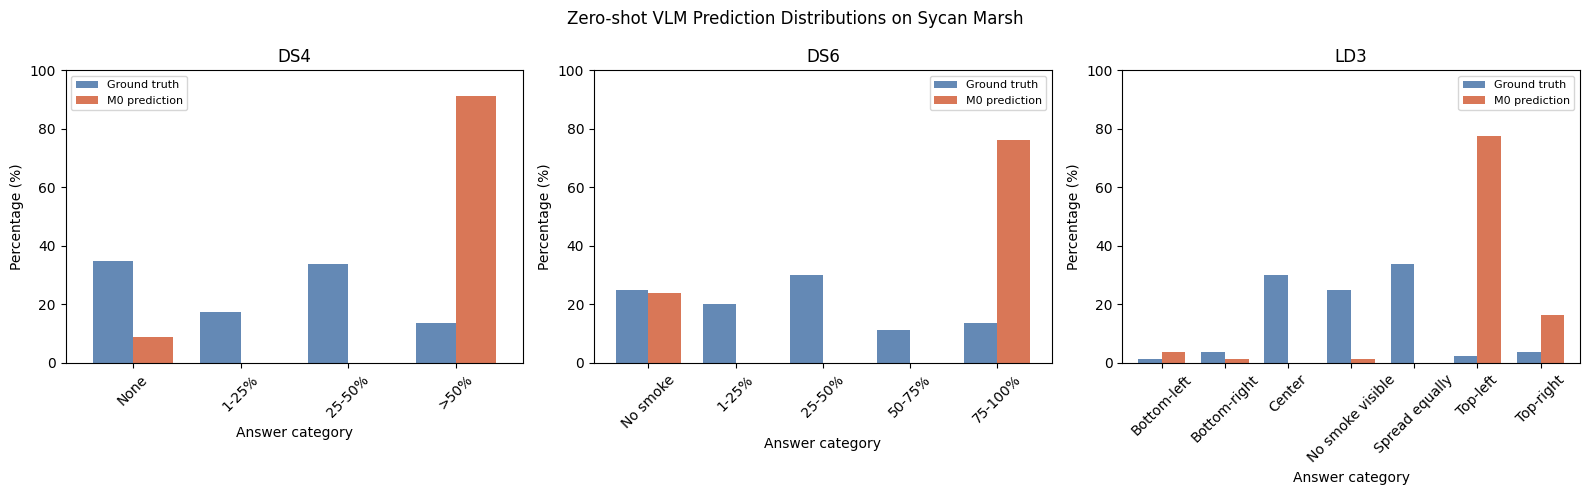

In [54]:
# Compare zero-shot predictions with ground-truth distributions

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, q in zip(axes, targets):

    d = m0[m0.qtype == q]

    counts = pd.DataFrame({
        "Ground truth": d.gold.value_counts(normalize=True) * 100,
        "M0 prediction": d.pred.value_counts(normalize=True) * 100
    }).reindex(labels[q]).fillna(0)

    counts.plot(
        kind="bar",
        ax=ax,
        color=["#6489B5", "#D97757"],
        width=0.75
    )

    ax.set_title(q)
    ax.set_xlabel("Answer category")
    ax.set_ylabel("Percentage (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8)

fig.suptitle("Zero-shot VLM Prediction Distributions on Sycan Marsh")

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_m0_prediction_bias.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_m0_prediction_bias.pdf",
    bbox_inches="tight"
)

plt.show()

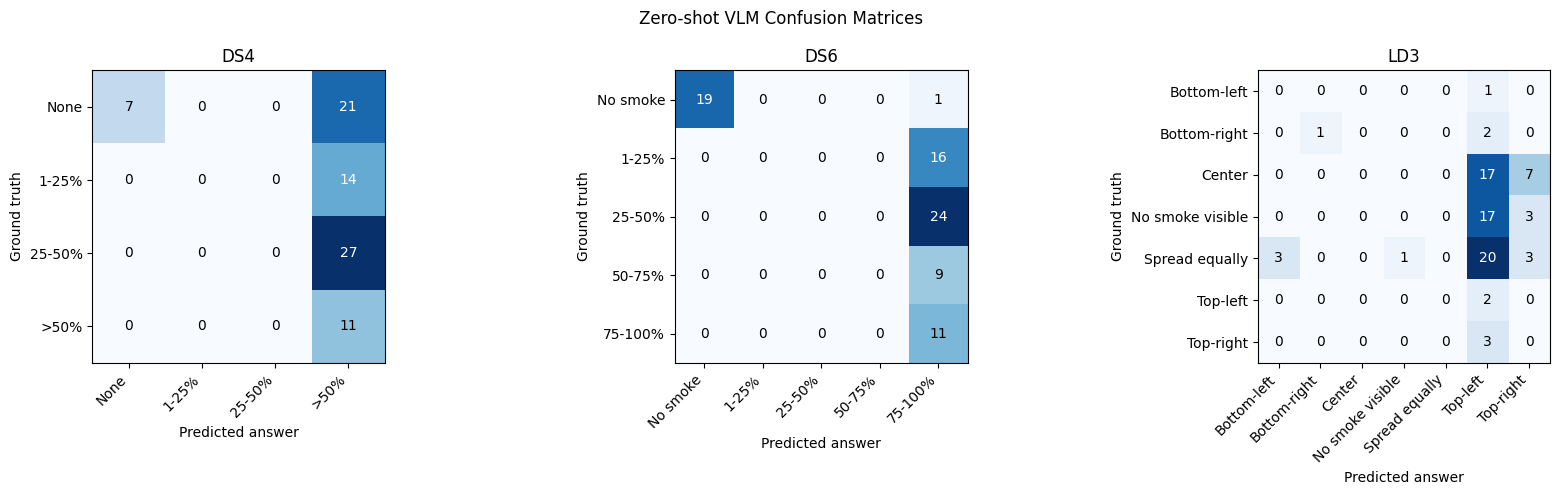

In [55]:
# Confusion matrices for zero-shot predictions

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, q in zip(axes, targets):

    d = m0[m0.qtype == q]
    names = labels[q]

    cm = confusion_matrix(
        d.gold,
        d.pred,
        labels=names
    )

    ax.imshow(cm, cmap="Blues")

    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(
                j, i, cm[i, j],
                ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black"
            )

    ax.set_xticks(range(len(names)))
    ax.set_yticks(range(len(names)))

    ax.set_xticklabels(names, rotation=45, ha="right")
    ax.set_yticklabels(names)

    ax.set_title(q)
    ax.set_xlabel("Predicted answer")
    ax.set_ylabel("Ground truth")

fig.suptitle("Zero-shot VLM Confusion Matrices")

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_m0_confusion_matrices.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_m0_confusion_matrices.pdf",
    bbox_inches="tight"
)

plt.show()

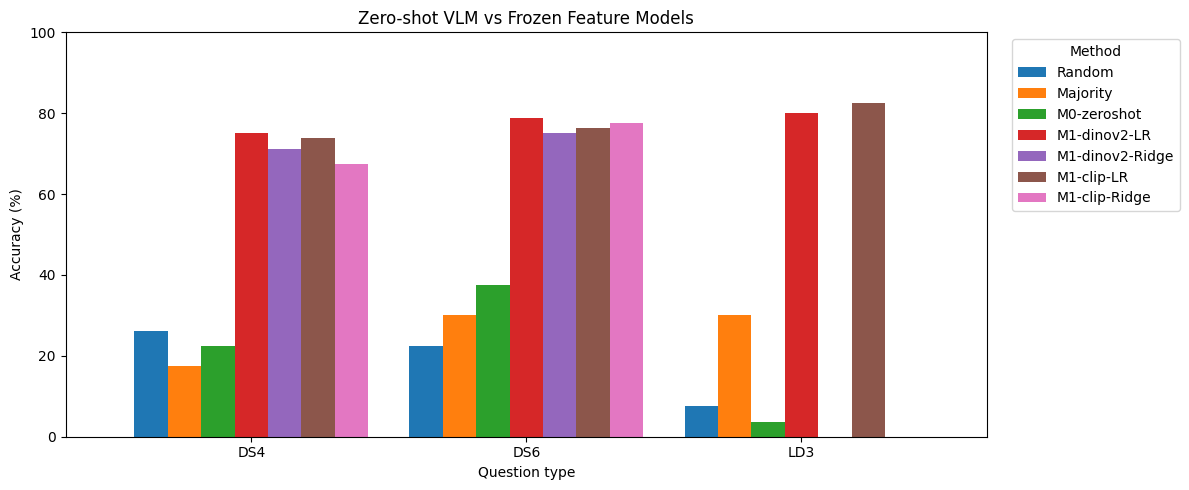

In [56]:
# Compare zero-shot VLM with supervised lightweight heads

p = add_scores(
    all_preds[
        (all_preds.fold == pilot_fold) &
        all_preds.method.isin(m0_methods)
    ]
)

acc = (
    p.groupby(["qtype", "method"]).right.mean()
    .unstack() * 100
)

acc = acc.reindex(
    index=list(targets),
    columns=m0_methods
)

ax = acc.plot(kind="bar", figsize=(12, 5), width=0.85)

ax.set_title("Zero-shot VLM vs Frozen Feature Models")
ax.set_xlabel("Question type")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

ax.legend(
    title="Method",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_m0_m1_comparison.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_m0_m1_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

**Zero-shot observation:** Qwen3-VL-2B achieves an overall
accuracy of 21.25% on the Sycan Marsh validation set.

The model shows a strong preference for the highest coverage
bins in DS4 and DS6 and the top-left location in LD3.

All generated answers are successfully parsed, suggesting
that the poor performance is not caused by parsing failures.

Frozen visual features combined with supervised lightweight
heads achieve substantially higher accuracy on the same
validation samples.

These findings motivate investigating task-specific
VLM adaptation and structured prediction hints.

In [57]:
# 6.5 M0+temp: RGB image with temperature summary

temp_keys = ["min", "max", "mean", "top3_mean"]

def valid_temp(t):
    if not isinstance(t, dict):
        return False

    try:
        return all(
            k in t and np.isfinite(float(t[k]))
            for k in temp_keys
        )
    except (TypeError, ValueError):
        return False


temp_available = test_rows.temp.apply(valid_temp)

print("Questions with valid temperature summaries:",
      int(temp_available.sum()), "of", len(test_rows))

print("Temperature summary coverage:",
      round(100 * temp_available.mean(), 2), "%")

# Inspect one available temperature summary
if temp_available.any():
    print("\nExample temperature summary:")
    print(test_rows.loc[temp_available, "temp"].iloc[0])


if temp_available.all():

    t0 = time.time()

    m0t = run_all(
        model,
        test_rows,
        use_temp=True,
        desc="M0+temp"
    )

    assert len(m0t) == len(test_rows)

    assert m0t[["frame", "qtype", "gold"]].equals(
        test_rows[["frame", "qtype", "gold"]].reset_index(drop=True)
    )

    # Save predictions and raw responses
    save_preds(m0t, "M0+temp", pilot_fold)

    m0t.to_csv(
        work / "results" / "m0_temp_pilot_raw_predictions.csv",
        index=False
    )

    print("\nInference time (seconds):",
          round(time.time() - t0, 2))

    print("Unparseable answers:",
          int(m0t.pred.isna().sum()))

    temp_table = show_table(
        ["Random", "Majority", "M0-zeroshot", "M0+temp"],
        pilot_fold
    )

    print("\nTemperature ablation results (mean [95% CI]):")
    print(temp_table.to_string(index=False))

    temp_table.to_csv(
        work / "results" / "temperature_ablation_results.csv",
        index=False
    )

else:
    print("\nTemperature summaries are missing or incomplete.")
    print("Inspect the summary keys before running M0+temp.")

Questions with valid temperature summaries: 240 of 240
Temperature summary coverage: 100.0 %

Example temperature summary:
{'min': -22.789, 'max': 483.743, 'mean': 4.779, 'std': 16.914, 'top3_mean': 57.513, 'pct_over_200': 0.123, 'pct_over_400': 0.004}


M0+temp:   0%|          | 0/240 [00:00<?, ?it/s]


Inference time (seconds): 81.33
Unparseable answers: 0

Temperature ablation results (mean [95% CI]):
     method           DS4 acc       DS4 within1       DS4 bin err           DS6 acc       DS6 within1       DS6 bin err           LD3 acc
     Random 26.2 [18.8, 33.8] 57.5 [48.8, 65.0] 1.29 [1.12, 1.46] 22.5 [12.5, 31.2] 48.8 [33.8, 66.2] 1.57 [1.24, 1.89]   7.5 [0.0, 15.0]
   Majority  17.5 [3.8, 33.8] 86.2 [67.5, 97.5] 0.96 [0.70, 1.25] 30.0 [12.5, 46.2] 61.3 [25.0, 92.6] 1.09 [0.61, 1.63] 30.0 [10.0, 52.5]
M0-zeroshot  22.5 [3.8, 46.3] 56.2 [31.2, 78.8] 1.48 [0.89, 2.10]  37.5 [7.4, 72.5] 48.8 [21.2, 77.5] 1.36 [0.64, 2.06]   3.8 [0.0, 10.0]
    M0+temp 45.0 [15.0, 72.5] 80.0 [67.5, 91.2] 0.79 [0.42, 1.15]  37.5 [7.4, 72.5] 48.8 [21.2, 77.5] 1.32 [0.61, 2.01]   3.8 [0.0, 10.0]


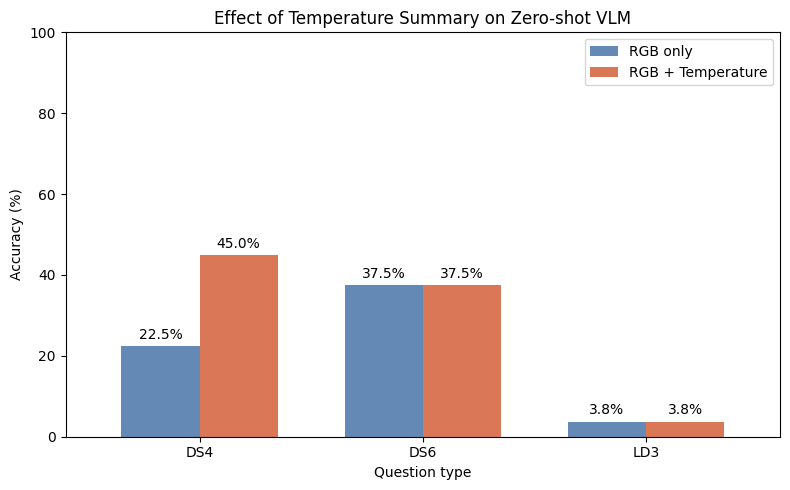

In [58]:
# Compare RGB-only and RGB with temperature summaries

p = add_scores(
    all_preds[
        (all_preds.fold == pilot_fold) &
        all_preds.method.isin(["M0-zeroshot", "M0+temp"])
    ]
)

acc = (
    p.groupby(["qtype", "method"]).right.mean()
    .unstack() * 100
)

acc = acc.reindex(
    index=list(targets),
    columns=["M0-zeroshot", "M0+temp"]
)

acc.columns = ["RGB only", "RGB + Temperature"]

ax = acc.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#6489B5", "#D97757"],
    width=0.7
)

ax.set_title("Effect of Temperature Summary on Zero-shot VLM")
ax.set_xlabel("Question type")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend()

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_temperature_ablation.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_temperature_ablation.pdf",
    bbox_inches="tight"
)

plt.show()

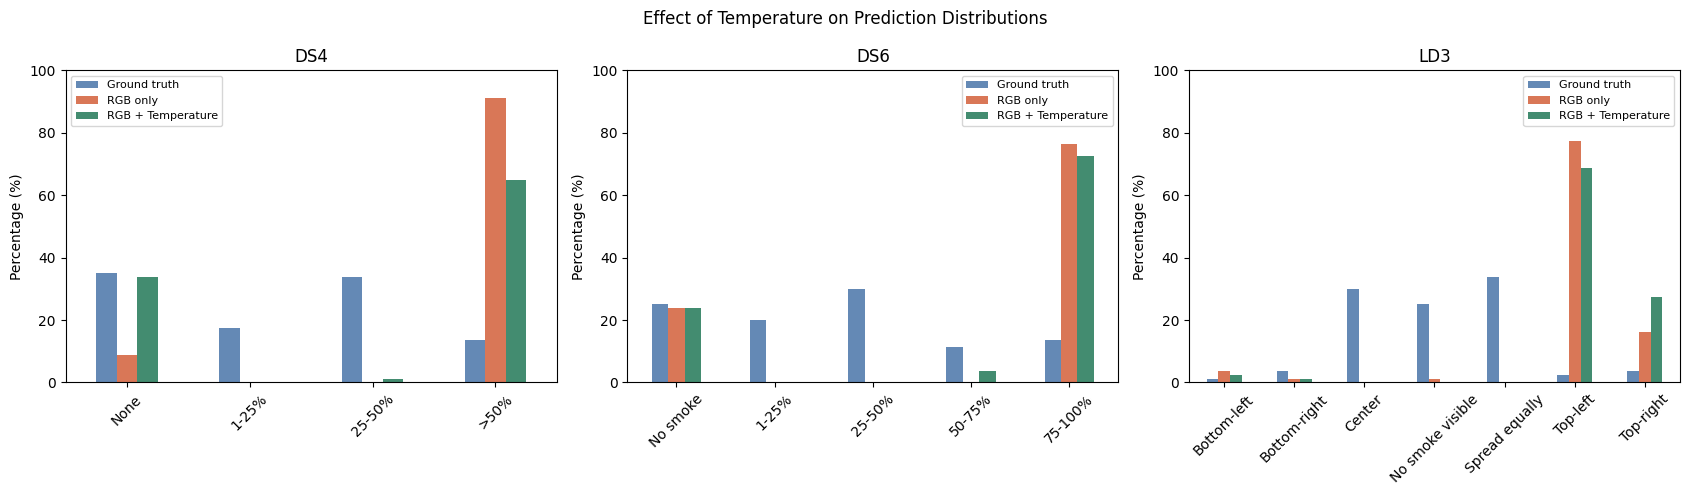

In [59]:
# Compare answer distributions before and after adding temperature

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, q in zip(axes, targets):

    a = m0[m0.qtype == q]
    b = m0t[m0t.qtype == q]

    dist = pd.DataFrame({
        "Ground truth": a.gold.value_counts(normalize=True) * 100,
        "RGB only": a.pred.value_counts(normalize=True) * 100,
        "RGB + Temperature": b.pred.value_counts(normalize=True) * 100
    }).reindex(labels[q]).fillna(0)

    dist.plot(
        kind="bar",
        ax=ax,
        color=["#6489B5", "#D97757", "#438C70"]
    )

    ax.set_title(q)
    ax.set_ylabel("Percentage (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8)

fig.suptitle("Effect of Temperature on Prediction Distributions")

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_temperature_prediction_distribution.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_temperature_prediction_distribution.pdf",
    bbox_inches="tight"
)

plt.show()

**Temperature ablation observation:** Adding temperature
statistics improves DS4 accuracy from 22.5% to 45.0%
and reduces the mean ordinal bin error from 1.48 to 0.79.

However, DS6 and LD3 exact accuracy remain unchanged.

These results suggest that global temperature statistics
may provide useful complementary information for estimating
fire-affected vegetation, but their benefit appears limited
for smoke coverage and spatial localization.

The overall accuracy increases from 21.25% to 28.75%.

In [60]:
# 6.6 M3: Zero-shot VLM with prediction hints from M1

head_preds = all_preds[
    (all_preds.method == "M1-dinov2-LR") &
    (all_preds.fold == pilot_fold)
].copy()

# Check that every evaluation question has one prediction
assert len(head_preds) == len(test_rows)
assert not head_preds.duplicated(["frame", "qtype"]).any()

expected_keys = set(zip(test_rows.frame, test_rows.qtype))
actual_keys = set(zip(head_preds.frame, head_preds.qtype))

assert expected_keys == actual_keys, "Missing or mismatched hints"

# Build hints using predictions, not ground-truth answers
hints = {
    (r.frame, r.qtype):
    f'A separate image model suggests the answer is "{r.pred}" (it can be wrong).'
    for r in head_preds.itertuples()
}

print("Available hints:", len(hints))
print("Evaluation questions:", len(test_rows))

# Inspect one example hint
print("\nExample hint:")
print(next(iter(hints.values())))

t0 = time.time()

m3 = run_all(
    model,
    test_rows,
    hints=hints,
    desc="M3"
)

assert len(m3) == len(test_rows)

assert m3[["frame", "qtype", "gold"]].equals(
    test_rows[["frame", "qtype", "gold"]].reset_index(drop=True)
)

# Save predictions and raw answers
save_preds(m3, "M3-zeroshot+hint", pilot_fold)

m3["hint"] = [
    hints[(r.frame, r.qtype)]
    for r in m3.itertuples()
]

m3.to_csv(
    work / "results" / "m3_pilot_raw_predictions.csv",
    index=False
)

print("\nInference time (seconds):",
      round(time.time() - t0, 2))

print("Unparseable answers:", int(m3.pred.isna().sum()))

m3_table = show_table([
    "Random",
    "Majority",
    "M0-zeroshot",
    "M0+temp",
    "M1-dinov2-LR",
    "M3-zeroshot+hint"
], pilot_fold)

print("\nM3 pilot results (mean [95% CI]):")
print(m3_table.to_string(index=False))

m3_table.to_csv(
    work / "results" / "m3_pilot_results.csv",
    index=False
)

Available hints: 240
Evaluation questions: 240

Example hint:
A separate image model suggests the answer is "25-50%" (it can be wrong).


M3:   0%|          | 0/240 [00:00<?, ?it/s]


Inference time (seconds): 84.89
Unparseable answers: 0

M3 pilot results (mean [95% CI]):
          method           DS4 acc        DS4 within1       DS4 bin err           DS6 acc          DS6 within1       DS6 bin err           LD3 acc
          Random 26.2 [18.8, 33.8]  57.5 [48.8, 65.0] 1.29 [1.12, 1.46] 22.5 [12.5, 31.2]    48.8 [33.8, 66.2] 1.57 [1.24, 1.89]   7.5 [0.0, 15.0]
        Majority  17.5 [3.8, 33.8]  86.2 [67.5, 97.5] 0.96 [0.70, 1.25] 30.0 [12.5, 46.2]    61.3 [25.0, 92.6] 1.09 [0.61, 1.63] 30.0 [10.0, 52.5]
     M0-zeroshot  22.5 [3.8, 46.3]  56.2 [31.2, 78.8] 1.48 [0.89, 2.10]  37.5 [7.4, 72.5]    48.8 [21.2, 77.5] 1.36 [0.64, 2.06]   3.8 [0.0, 10.0]
         M0+temp 45.0 [15.0, 72.5]  80.0 [67.5, 91.2] 0.79 [0.42, 1.15]  37.5 [7.4, 72.5]    48.8 [21.2, 77.5] 1.32 [0.61, 2.01]   3.8 [0.0, 10.0]
    M1-dinov2-LR 75.0 [56.2, 91.2] 95.0 [85.0, 100.0] 0.35 [0.10, 0.63] 78.8 [68.8, 88.8] 100.0 [100.0, 100.0] 0.21 [0.11, 0.31] 80.0 [68.8, 91.2]
M3-zeroshot+hint 75.0 [56.2

In [61]:
# Analyze whether the VLM improves or overrides M1 predictions

comparison = m3.merge(
    head_preds[["frame", "qtype", "pred"]],
    on=["frame", "qtype"],
    suffixes=("_m3", "_m1"),
    validate="one_to_one"
)

comparison["m1_correct"] = (
    comparison.pred_m1 == comparison.gold
)

comparison["m3_correct"] = (
    comparison.pred_m3 == comparison.gold
)

comparison["follows_hint"] = (
    comparison.pred_m3 == comparison.pred_m1
)

comparison["corrected"] = (
    ~comparison.m1_correct & comparison.m3_correct
)

comparison["introduced_error"] = (
    comparison.m1_correct & ~comparison.m3_correct
)

rows = []

for q in targets:
    d = comparison[comparison.qtype == q]

    rows.append({
        "qtype": q,
        "questions": len(d),
        "hint_agreement_pct": round(
            100 * d.follows_hint.mean(), 2
        ),
        "M1_errors_corrected": int(d.corrected.sum()),
        "new_errors_introduced": int(d.introduced_error.sum())
    })

hint_analysis = pd.DataFrame(rows)

print(hint_analysis.to_string(index=False))

hint_analysis.to_csv(
    work / "results" / "m3_hint_analysis.csv",
    index=False
)

qtype  questions  hint_agreement_pct  M1_errors_corrected  new_errors_introduced
  DS4         80              100.00                    0                      0
  DS6         80               98.75                    0                      0
  LD3         80                0.00                    3                     64


In [62]:
# Inspect LD3 hints and generated answers

ld3_check = comparison[
    comparison.qtype == "LD3"
].copy()

print(
    ld3_check[
        ["gold", "pred_m1", "hint", "raw", "pred_m3"]
    ].head(15).to_string(index=False)
)

print("\nM1 vs M3 prediction agreement:")

print(pd.crosstab(
    ld3_check.pred_m1,
    ld3_check.pred_m3,
    margins=True
))

          gold        pred_m1                                                                              hint       raw   pred_m3
Spread equally Spread equally A separate image model suggests the answer is "Spread equally" (it can be wrong).  Top-left  Top-left
Spread equally Spread equally A separate image model suggests the answer is "Spread equally" (it can be wrong).  Top-left  Top-left
Spread equally Spread equally A separate image model suggests the answer is "Spread equally" (it can be wrong).  Top-left  Top-left
Spread equally Spread equally A separate image model suggests the answer is "Spread equally" (it can be wrong).  Top-left  Top-left
Spread equally Spread equally A separate image model suggests the answer is "Spread equally" (it can be wrong).  Top-left  Top-left
        Center         Center         A separate image model suggests the answer is "Center" (it can be wrong).  Top-left  Top-left
Spread equally Spread equally A separate image model suggests the answer is 

In [63]:
# Compare original zero-shot and hint-assisted predictions

m0_m3 = m0.merge(
    m3[["frame", "qtype", "pred"]],
    on=["frame", "qtype"],
    suffixes=("_m0", "_m3"),
    validate="one_to_one"
)

m0_m3["same_prediction"] = (
    m0_m3.pred_m0 == m0_m3.pred_m3
)

print(
    m0_m3.groupby("qtype")
    .same_prediction.mean().mul(100)
)

qtype
DS4    17.50
DS6    35.00
LD3    91.25
Name: same_prediction, dtype: float64


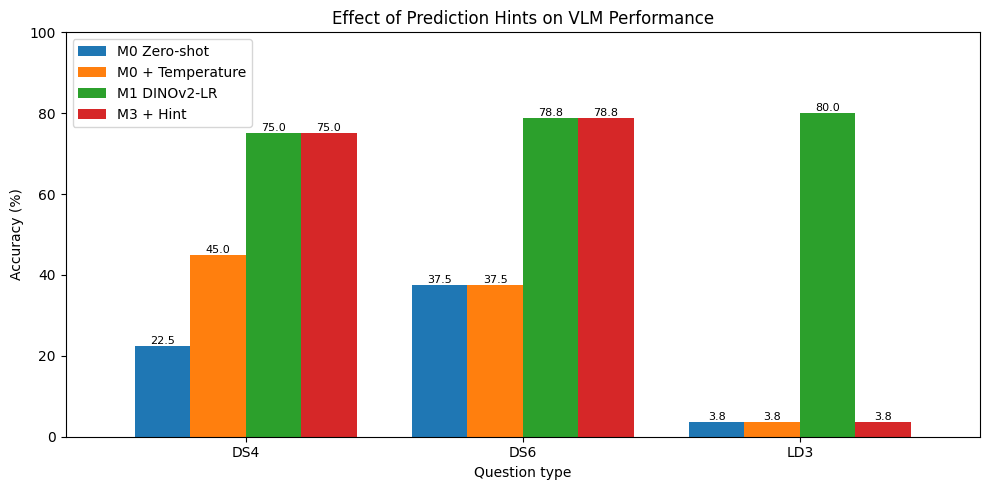

In [64]:
# Compare zero-shot, temperature, classifier and hint methods

selected = [
    "M0-zeroshot",
    "M0+temp",
    "M1-dinov2-LR",
    "M3-zeroshot+hint"
]

p = add_scores(
    all_preds[
        (all_preds.fold == pilot_fold) &
        all_preds.method.isin(selected)
    ]
)

acc = (
    p.groupby(["qtype", "method"]).right.mean()
    .unstack() * 100
)

acc = acc.reindex(
    index=list(targets),
    columns=selected
)

acc.columns = [
    "M0 Zero-shot",
    "M0 + Temperature",
    "M1 DINOv2-LR",
    "M3 + Hint"
]

ax = acc.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)

ax.set_title("Effect of Prediction Hints on VLM Performance")
ax.set_xlabel("Question type")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend()

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=8)

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_m3_pilot_performance.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_m3_pilot_performance.pdf",
    bbox_inches="tight"
)

plt.show()

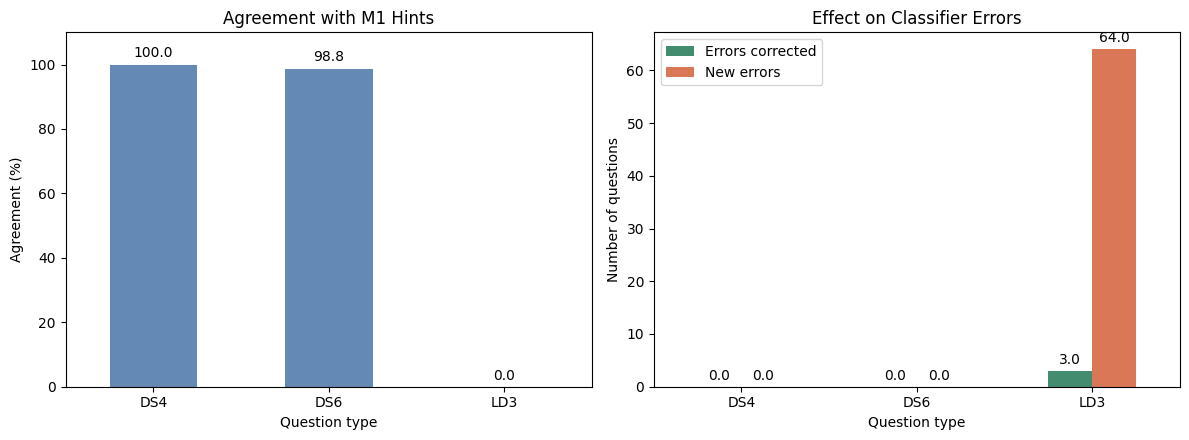

In [65]:
# Analyze agreement with the classifier hints

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

h = hint_analysis.set_index("qtype").reindex(list(targets))

h["hint_agreement_pct"].plot(
    kind="bar",
    ax=axes[0],
    color="#6489B5"
)

axes[0].set_title("Agreement with M1 Hints")
axes[0].set_ylabel("Agreement (%)")
axes[0].set_ylim(0, 110)
axes[0].set_xlabel("Question type")

h[[
    "M1_errors_corrected",
    "new_errors_introduced"
]].rename(columns={
    "M1_errors_corrected": "Errors corrected",
    "new_errors_introduced": "New errors"
}).plot(
    kind="bar",
    ax=axes[1],
    color=["#438C70", "#D97757"]
)

axes[1].set_title("Effect on Classifier Errors")
axes[1].set_ylabel("Number of questions")
axes[1].set_xlabel("Question type")
axes[1].legend()

for ax in axes:
    ax.tick_params(axis="x", rotation=0)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", padding=3)

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_m3_hint_analysis.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_m3_hint_analysis.pdf",
    bbox_inches="tight"
)

plt.show()

**Further analysis of prediction hints:** Adding classifier
hints changes 82.5% of DS4 predictions and 65.0% of DS6
predictions, but only 8.75% of LD3 predictions.

For LD3, the VLM predicts the top-left region in 68 out
of 80 cases, despite receiving hints suggesting other
answer categories.

This indicates that the effectiveness of classifier hints
varies substantially across question types. The VLM does
not improve upon the standalone classifier in this pilot
experiment.

In [66]:
# Save prediction agreement diagnostics

ld3_check.to_csv(
    work / "results" / "m3_ld3_diagnostics.csv",
    index=False
)

agreement = (
    m0_m3.groupby("qtype")
    .same_prediction.mean()
    .mul(100)
    .rename("unchanged_pct")
    .reset_index()
)

agreement["changed_pct"] = 100 - agreement["unchanged_pct"]

agreement.to_csv(
    work / "results" / "m0_m3_prediction_agreement.csv",
    index=False
)

print(agreement.to_string(index=False))

qtype  unchanged_pct  changed_pct
  DS4          17.50        82.50
  DS6          35.00        65.00
  LD3          91.25         8.75


## Stage 7: M2 – LoRA fine-tuning of the vision-language model

I fine-tune Qwen3-VL-2B using Low-Rank Adaptation (LoRA)
while keeping the original model weights and image encoder
frozen.

The training examples use the same prompt structure as M0.
The model learns to generate the correct option text.
Answer options are shuffled during training to reduce
dependence on fixed option positions.

The pilot experiment uses 320 Sycan Marsh training frames
and 80 separate validation frames. Validation samples are
excluded from gradient updates.

The LoRA adapter is saved to Google Drive after each epoch.

The objective is to investigate whether task-specific
adaptation improves coverage estimation, smoke localization,
and prediction diversity compared with the zero-shot model.

Cross-site generalization remains untested because imagery
from the other two burn sites is not yet available.

In [67]:
# 7.1 Reload the VLM and attach LoRA adapters

# Release the zero-shot model
original_vlm_name = vlm_name

del model
gc.collect()
torch.cuda.empty_cache()

from peft import LoraConfig, get_peft_model
from transformers import get_cosine_schedule_with_warmup

# Reload the same pretrained model
vlm_name, proc, base = load_vlm()

assert vlm_name == original_vlm_name, "VLM checkpoint changed"

# Select attention projections in the language model only
attention_names = ["q_proj", "k_proj", "v_proj", "o_proj"]

target_modules = [
    name for name, module in base.named_modules()
    if "language_model" in name
    and name.split(".")[-1] in attention_names
    and isinstance(module, torch.nn.Linear)
]

assert len(target_modules) > 0, "No language attention modules found"

print("\nLoRA target modules:", len(target_modules))
print("Example target modules:")
print("\n".join(target_modules[:4]))

# Configure LoRA
config = LoraConfig(
    r=lora_r,
    lora_alpha=lora_alpha,
    lora_dropout=0.05,
    task_type="CAUSAL_LM",
    target_modules=target_modules,
    bias="none"
)

model = get_peft_model(base, config)

# Disable generation cache during training
base.config.use_cache = False

if hasattr(base.config, "text_config"):
    base.config.text_config.use_cache = False

# Reduce training memory requirements
model.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={"use_reentrant": False}
)

model.enable_input_require_grads()

# Verify that only LoRA parameters are trainable
trainable_names = [
    name for name, p in model.named_parameters()
    if p.requires_grad
]

assert len(trainable_names) > 0

assert all(
    "lora_" in name and "language_model" in name
    for name in trainable_names
), "Unexpected trainable parameters"

model.train()

print("\nTrainable parameters:")
model.print_trainable_parameters()

print("\nLoRA rank:", lora_r)
print("LoRA alpha:", lora_alpha)
print("Trainable parameter tensors:", len(trainable_names))
print("Original model weights: Frozen")
print("Vision encoder: Frozen")
print("Gradient checkpointing: Enabled")

print("\nGPU memory allocated (GB):",
      round(torch.cuda.memory_allocated() / 1e9, 2))

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

Loaded: Qwen/Qwen3-VL-2B-Instruct

LoRA target modules: 112
Example target modules:
model.language_model.layers.0.self_attn.q_proj
model.language_model.layers.0.self_attn.k_proj
model.language_model.layers.0.self_attn.v_proj
model.language_model.layers.0.self_attn.o_proj


/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(



Trainable parameters:
trainable params: 6,422,528 || all params: 2,133,954,560 || trainable%: 0.3010

LoRA rank: 16
LoRA alpha: 32
Trainable parameter tensors: 224
Original model weights: Frozen
Vision encoder: Frozen
Gradient checkpointing: Enabled

GPU memory allocated (GB): 4.47


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3204: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(


In [68]:
# Save LoRA model configuration for the research report

total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

lora_details = {
    "model": vlm_name,
    "total_parameters": total_params,
    "trainable_parameters": trainable_params,
    "frozen_parameters": total_params - trainable_params,
    "trainable_percentage": 100 * trainable_params / total_params,
    "target_modules": len(target_modules),
    "rank": lora_r,
    "alpha": lora_alpha,
    "dropout": 0.05,
    "vision_encoder_frozen": True,
    "gradient_checkpointing": True,
    "gpu_memory_gb": round(
        torch.cuda.memory_allocated() / 1e9, 2
    )
}

pd.DataFrame([lora_details]).to_csv(
    work / "results" / "lora_configuration.csv",
    index=False
)

print("LoRA configuration saved.")

LoRA configuration saved.


In [69]:
# 7.2 Fine-tune the VLM on Sycan Marsh

import math

tok = proc.tokenizer

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# Select only training frames with available images
train_rows = pilot_data[
    (pilot_data.split == "train") &
    pilot_data.img_local.notna()
].sample(frac=1, random_state=42).head(train_cap).reset_index(drop=True)

# Use the same validation questions as M0 and M1
val_rows = test_rows.copy().reset_index(drop=True)

# Check data separation
assert set(train_rows.frame).isdisjoint(val_rows.frame)
assert set(train_rows.block).isdisjoint(val_rows.block)
assert train_rows.img_local.notna().all()
assert val_rows.img_local.notna().all()

print("Training frames:", train_rows.frame.nunique())
print("Training questions:", len(train_rows))

print("Validation frames:", val_rows.frame.nunique())
print("Validation questions:", len(val_rows))

print("\nTraining question distribution:")
print(train_rows.qtype.value_counts())


def training_example(r):

    # Shuffle answer options to reduce position dependence
    options = list(r.options)
    random.shuffle(options)

    assert r.gold in options

    context, task = build_text(r.question, options)
    prompt = chat_prompt(context, task)

    img = load_image(r.img_local)

    # Encode the prompt separately
    prompt_inputs = proc(
        text=[prompt],
        images=[img],
        return_tensors="pt"
    )

    prompt_ids = prompt_inputs["input_ids"]
    prompt_len = prompt_ids.shape[1]

    # Encode the prompt and correct answer
    full = proc(
        text=[prompt + r.gold + tok.eos_token],
        images=[img],
        return_tensors="pt"
    )

    # Verify that the prompt tokens match exactly
    assert torch.equal(
        full["input_ids"][:, :prompt_len],
        prompt_ids
    ), "Prompt token alignment mismatch"

    labels_ = full["input_ids"].clone()

    # Calculate loss only on the answer and EOS token
    labels_[:, :prompt_len] = -100

    if "attention_mask" in full:
        labels_[full["attention_mask"] == 0] = -100

    assert (labels_ != -100).any(), "No supervised answer tokens"

    full["labels"] = labels_

    full = full.to(model.device)
    full["pixel_values"] = full["pixel_values"].to(model.dtype)

    return full


# Check answer-only supervision before training
sample = next(train_rows.itertuples())
sample_batch = training_example(sample)

answer_tokens = sample_batch["labels"][
    sample_batch["labels"] != -100
]

print("\nTraining example verification:")
print("Ground truth:", sample.gold)
print("Supervised text:", repr(tok.decode(answer_tokens.cpu())))

print("Total input tokens:", sample_batch["input_ids"].shape[1])
print("Supervised tokens:", len(answer_tokens))

del sample_batch, answer_tokens


@torch.no_grad()
def val_accuracy():

    model.eval()

    correct = []

    try:
        for r in tqdm(
            list(val_rows.itertuples()),
            desc="Validation",
            leave=False
        ):

            raw = ask(model, r)
            pred = parse_choice(raw, r.options)

            correct.append(pred == r.gold)

    finally:
        model.train()

    return float(np.mean(correct))


# Optimizer and learning rate schedule
trainable = [
    p for p in model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable,
    lr=lora_lr,
    weight_decay=0.0
)

updates_per_epoch = math.ceil(
    len(train_rows) / accum_steps
)

total_steps = lora_epochs * updates_per_epoch

scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.05 * total_steps),
    num_training_steps=total_steps
)

scaler = torch.amp.GradScaler("cuda")

log = []
recent = []

step = 0
skipped = 0
skipped_updates = 0

start = time.time()

log_path = work / "results" / "lora_log.csv"
adapter_dir = work / "lora" / "sycan_pilot"

adapter_dir.mkdir(parents=True, exist_ok=True)

torch.cuda.reset_peak_memory_stats()

print("\nPlanned optimizer updates:", total_steps)

model.train()
optimizer.zero_grad(set_to_none=True)


for epoch in range(lora_epochs):

    order = train_rows.sample(
        frac=1,
        random_state=epoch
    ).reset_index(drop=True)

    epoch_losses = []
    group_valid = True

    progress = tqdm(
        list(order.itertuples()),
        desc=f"Epoch {epoch + 1}/{lora_epochs}"
    )

    for i, r in enumerate(progress):

        # Handle the final accumulation group
        group_start = (i // accum_steps) * accum_steps

        group_size = min(
            accum_steps,
            len(order) - group_start
        )

        batch = training_example(r)

        with torch.autocast("cuda", dtype=torch.float16):
            loss = model(**batch).loss

        if torch.isfinite(loss):

            scaler.scale(loss / group_size).backward()

            loss_value = float(loss.detach().item())

            recent.append(loss_value)
            epoch_losses.append(loss_value)

            progress.set_postfix(
                loss=f"{loss_value:.3f}",
                updates=step,
                skipped=skipped
            )

        else:
            skipped += 1
            group_valid = False

        del batch, loss

        # Update at the end of each accumulation group
        end_group = (
            (i + 1) % accum_steps == 0
            or (i + 1) == len(order)
        )

        if end_group:

            if group_valid:

                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    trainable, 1.0
                )

                old_scale = scaler.get_scale()

                scaler.step(optimizer)
                scaler.update()

                # Advance scheduler only after successful updates
                if scaler.get_scale() >= old_scale:

                    scheduler.step()
                    step += 1

                    if step % 10 == 0:

                        log.append({
                            "epoch": epoch + 1,
                            "step": step,
                            "loss": float(np.mean(
                                recent[-10 * accum_steps:]
                            )),
                            "learning_rate": optimizer.param_groups[0]["lr"],
                            "skipped": skipped,
                            "skipped_updates": skipped_updates
                        })

                        pd.DataFrame(log).to_csv(
                            log_path, index=False
                        )

                else:
                    skipped_updates += 1

            else:
                skipped_updates += 1

            optimizer.zero_grad(set_to_none=True)
            group_valid = True

    # Save adapter before validation
    checkpoint = adapter_dir / f"epoch{epoch + 1}"

    model.save_pretrained(checkpoint)
    proc.save_pretrained(checkpoint)

    # Evaluate after each epoch
    acc = val_accuracy()

    epoch_loss = (
        float(np.mean(epoch_losses))
        if epoch_losses else np.nan
    )

    log.append({
        "epoch": epoch + 1,
        "step": step,
        "epoch_loss": epoch_loss,
        "val_acc": acc,
        "skipped": skipped,
        "skipped_updates": skipped_updates,
        "elapsed_minutes": (time.time() - start) / 60
    })

    # Save training progress after every epoch
    pd.DataFrame(log).to_csv(
        log_path,
        index=False
    )

    print(f"\nEpoch {epoch + 1} completed")
    print("Mean training loss:", round(epoch_loss, 4))
    print("Validation accuracy:", round(acc * 100, 2), "%")
    print("Successful optimizer updates:", step)
    print("Non-finite losses:", skipped)
    print("Skipped optimizer updates:", skipped_updates)
    print("Adapter saved:", checkpoint)

    print("Peak GPU memory (GB):",
          round(torch.cuda.max_memory_allocated() / 1e9, 2))


model.eval()

print("\nLoRA training completed.")

print("Total training time (minutes):",
      round((time.time() - start) / 60, 2))

print("Successful optimizer updates:", step)
print("Non-finite losses:", skipped)
print("Skipped optimizer updates:", skipped_updates)

print("Training log saved:", log_path)

Training frames: 320
Training questions: 960
Validation frames: 80
Validation questions: 240

Training question distribution:
qtype
LD3    320
DS4    320
DS6    320
Name: count, dtype: int64

Training example verification:
Ground truth: No smoke visible
Supervised text: 'No smoke visible<|im_end|>'
Total input tokens: 237
Supervised tokens: 4

Planned optimizer updates: 240


Epoch 1/2:   0%|          | 0/960 [00:00<?, ?it/s]

Validation:   0%|          | 0/240 [00:00<?, ?it/s]


Epoch 1 completed
Mean training loss: 0.3188
Validation accuracy: 75.42 %
Successful optimizer updates: 120
Non-finite losses: 0
Skipped optimizer updates: 0
Adapter saved: /content/drive/MyDrive/wildfire_vqa_study/lora/sycan_pilot/epoch1
Peak GPU memory (GB): 5.04


Epoch 2/2:   0%|          | 0/960 [00:00<?, ?it/s]

Validation:   0%|          | 0/240 [00:00<?, ?it/s]


Epoch 2 completed
Mean training loss: 0.1285
Validation accuracy: 78.33 %
Successful optimizer updates: 240
Non-finite losses: 0
Skipped optimizer updates: 0
Adapter saved: /content/drive/MyDrive/wildfire_vqa_study/lora/sycan_pilot/epoch2
Peak GPU memory (GB): 5.04

LoRA training completed.
Total training time (minutes): 19.13
Successful optimizer updates: 240
Non-finite losses: 0
Skipped optimizer updates: 0
Training log saved: /content/drive/MyDrive/wildfire_vqa_study/results/lora_log.csv


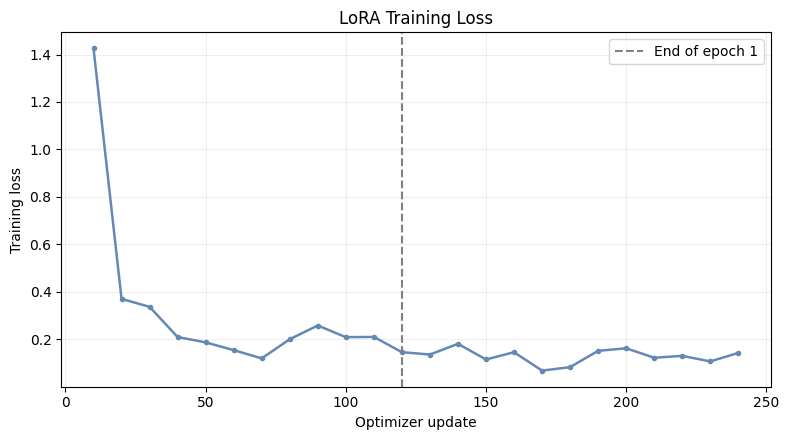

In [70]:
# Plot the LoRA training loss

history = pd.read_csv(
    work / "results" / "lora_log.csv"
)

loss_history = history.dropna(subset=["loss"])

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    loss_history.step,
    loss_history.loss,
    color="#6489B5",
    marker="o",
    markersize=3,
    linewidth=1.8
)

ax.axvline(
    x=120,
    color="gray",
    linestyle="--",
    label="End of epoch 1"
)

ax.set_title("LoRA Training Loss")
ax.set_xlabel("Optimizer update")
ax.set_ylabel("Training loss")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_lora_training_loss.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_lora_training_loss.pdf",
    bbox_inches="tight"
)

plt.show()

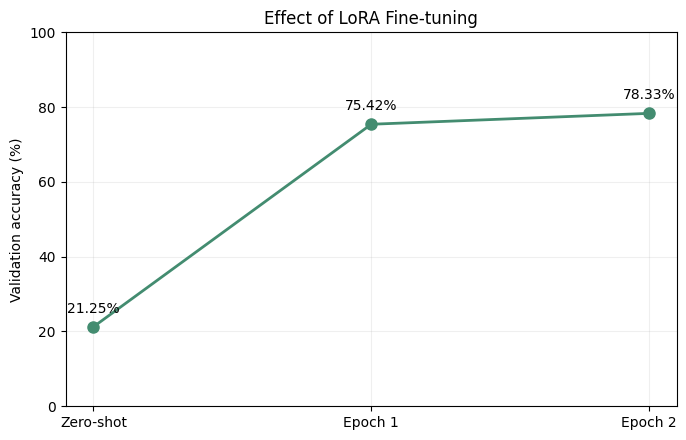

In [71]:
# Plot validation accuracy before and after adaptation

val_history = history.dropna(subset=["val_acc"])

epochs = [0] + val_history.epoch.astype(int).tolist()

accuracies = [
    100 * (m0.pred == m0.gold).mean()
] + (100 * val_history.val_acc).tolist()

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(
    epochs,
    accuracies,
    marker="o",
    markersize=8,
    linewidth=2,
    color="#438C70"
)

for x, y in zip(epochs, accuracies):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

ax.set_xticks(epochs)
ax.set_xticklabels(["Zero-shot", "Epoch 1", "Epoch 2"])
ax.set_ylim(0, 100)
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("Effect of LoRA Fine-tuning")
ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_lora_validation_accuracy.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_lora_validation_accuracy.pdf",
    bbox_inches="tight"
)

plt.show()

**LoRA training observation:** Fine-tuning Qwen3-VL-2B
for two epochs improves validation accuracy from 21.25%
to 78.33%, while updating only 0.301% of the total model
parameters.

The mean training loss decreases from 0.3188 to 0.1285.
All 240 optimizer updates complete successfully without
non-finite losses or skipped updates.

Training takes 19.13 minutes with a peak allocated GPU
memory of 5.04 GB on a Tesla T4.

These results demonstrate substantial improvement on
the within-site validation split. Generalization to
unseen burn sites remains untested.

In [72]:
# 7.3 Evaluate the fine-tuned VLM on Sycan Marsh

model.eval()

t0 = time.time()

m2 = run_all(
    model,
    test_rows,
    desc="M2 LoRA"
)

# Verify prediction coverage and alignment
assert len(m2) == len(test_rows)

assert m2[["frame", "qtype", "gold"]].equals(
    test_rows[["frame", "qtype", "gold"]].reset_index(drop=True)
)

# Save predictions
save_preds(m2, "M2-LoRA", pilot_fold)

# Save raw generated answers
m2.to_csv(
    work / "results" / "m2_pilot_raw_predictions.csv",
    index=False
)

print("\nEvaluation questions:", len(m2))
print("Evaluation frames:", m2.frame.nunique())

print("Inference time (seconds):",
      round(time.time() - t0, 2))

print("Answers that could not be parsed: %.1f%%"
      % (100 * m2.pred.isna().mean()))

# Compare all methods on the same validation split
final_methods = [
    "Random",
    "Majority",
    "M0-zeroshot",
    "M0+temp",
    "M1-dinov2-LR",
    "M1-dinov2-Ridge",
    "M1-clip-LR",
    "M1-clip-Ridge",
    "M2-LoRA",
    "M3-zeroshot+hint"
]

final_table = show_table(final_methods, pilot_fold)

print("\nComplete pilot results (mean [95% CI]):")
print(final_table.to_string(index=False))

final_table.to_csv(
    work / "results" / "final_pilot_results.csv",
    index=False
)

# Inspect prediction distributions after fine-tuning
for q in targets:

    d = m2[m2.qtype == q]

    print(f"\n{q} prediction distribution:")

    print(pd.DataFrame({
        "Predicted": d.pred.value_counts(),
        "Ground truth": d.gold.value_counts()
    }).fillna(0).astype(int))

print("\nOverall M2 accuracy:",
      round(100 * (m2.pred == m2.gold).mean(), 2), "%")

M2 LoRA:   0%|          | 0/240 [00:00<?, ?it/s]


Evaluation questions: 240
Evaluation frames: 80
Inference time (seconds): 107.46
Answers that could not be parsed: 0.0%

Complete pilot results (mean [95% CI]):
          method           DS4 acc        DS4 within1       DS4 bin err           DS6 acc          DS6 within1       DS6 bin err           LD3 acc
          Random 26.2 [18.8, 33.8]  57.5 [48.8, 65.0] 1.29 [1.12, 1.46] 22.5 [12.5, 31.2]    48.8 [33.8, 66.2] 1.57 [1.24, 1.89]   7.5 [0.0, 15.0]
        Majority  17.5 [3.8, 33.8]  86.2 [67.5, 97.5] 0.96 [0.70, 1.25] 30.0 [12.5, 46.2]    61.3 [25.0, 92.6] 1.09 [0.61, 1.63] 30.0 [10.0, 52.5]
     M0-zeroshot  22.5 [3.8, 46.3]  56.2 [31.2, 78.8] 1.48 [0.89, 2.10]  37.5 [7.4, 72.5]    48.8 [21.2, 77.5] 1.36 [0.64, 2.06]   3.8 [0.0, 10.0]
         M0+temp 45.0 [15.0, 72.5]  80.0 [67.5, 91.2] 0.79 [0.42, 1.15]  37.5 [7.4, 72.5]    48.8 [21.2, 77.5] 1.32 [0.61, 2.01]   3.8 [0.0, 10.0]
    M1-dinov2-LR 75.0 [56.2, 91.2] 95.0 [85.0, 100.0] 0.35 [0.10, 0.63] 78.8 [68.8, 88.8] 100.0 [100.0,

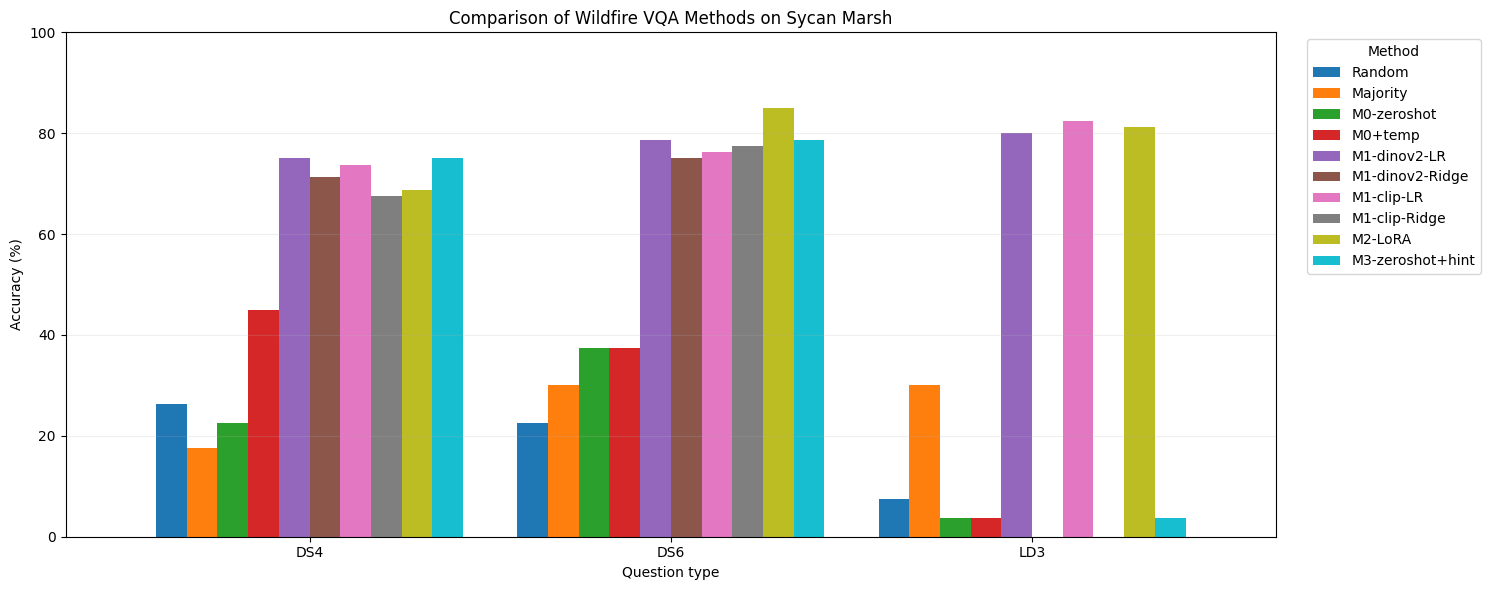

In [73]:
# Compare the accuracy of all pilot methods

p = add_scores(
    all_preds[
        (all_preds.fold == pilot_fold) &
        all_preds.method.isin(final_methods)
    ]
)

acc = (
    p.groupby(["qtype", "method"]).right.mean()
    .unstack() * 100
)

acc = acc.reindex(
    index=list(targets),
    columns=final_methods
)

fig, ax = plt.subplots(figsize=(15, 6))

acc.plot(kind="bar", ax=ax, width=0.85)

ax.set_title("Comparison of Wildfire VQA Methods on Sycan Marsh")
ax.set_xlabel("Question type")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

ax.legend(
    title="Method",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_final_pilot_comparison.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_final_pilot_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

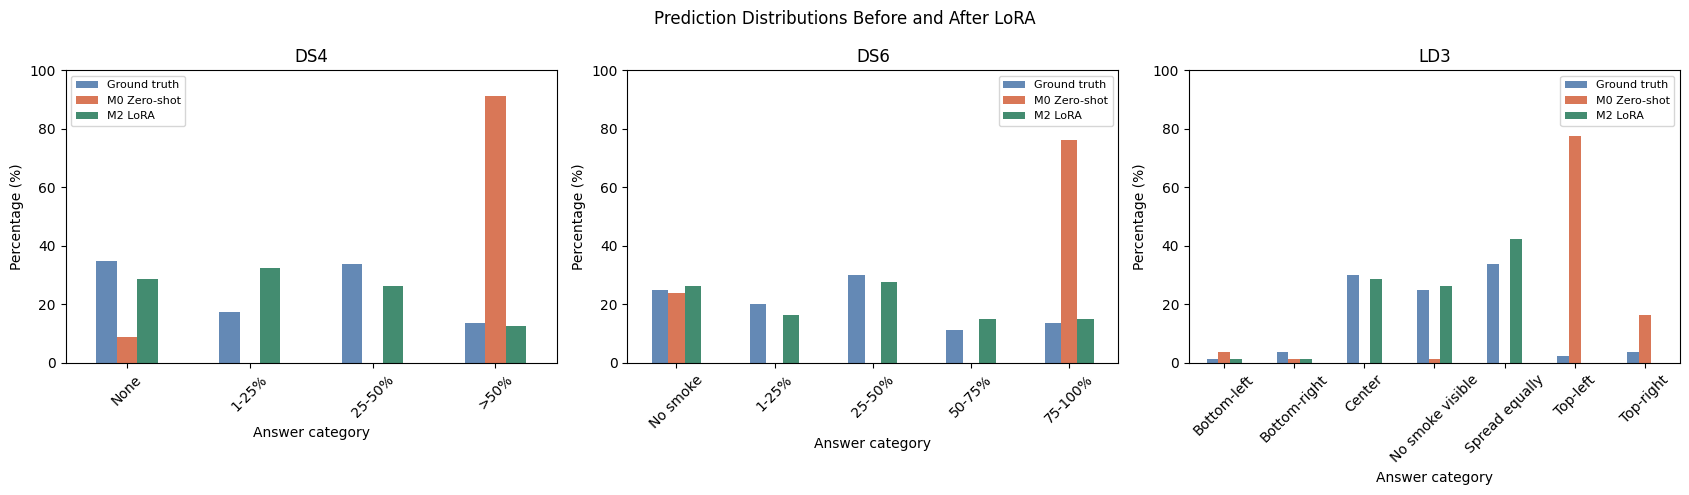

In [74]:
# Compare zero-shot and fine-tuned prediction distributions

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, q in zip(axes, targets):

    a = m0[m0.qtype == q]
    b = m2[m2.qtype == q]

    dist = pd.DataFrame({
        "Ground truth": a.gold.value_counts(normalize=True) * 100,
        "M0 Zero-shot": a.pred.value_counts(normalize=True) * 100,
        "M2 LoRA": b.pred.value_counts(normalize=True) * 100
    }).reindex(labels[q]).fillna(0)

    dist.plot(
        kind="bar",
        ax=ax,
        color=["#6489B5", "#D97757", "#438C70"]
    )

    ax.set_title(q)
    ax.set_xlabel("Answer category")
    ax.set_ylabel("Percentage (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8)

fig.suptitle("Prediction Distributions Before and After LoRA")

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_m0_m2_prediction_distribution.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_m0_m2_prediction_distribution.pdf",
    bbox_inches="tight"
)

plt.show()

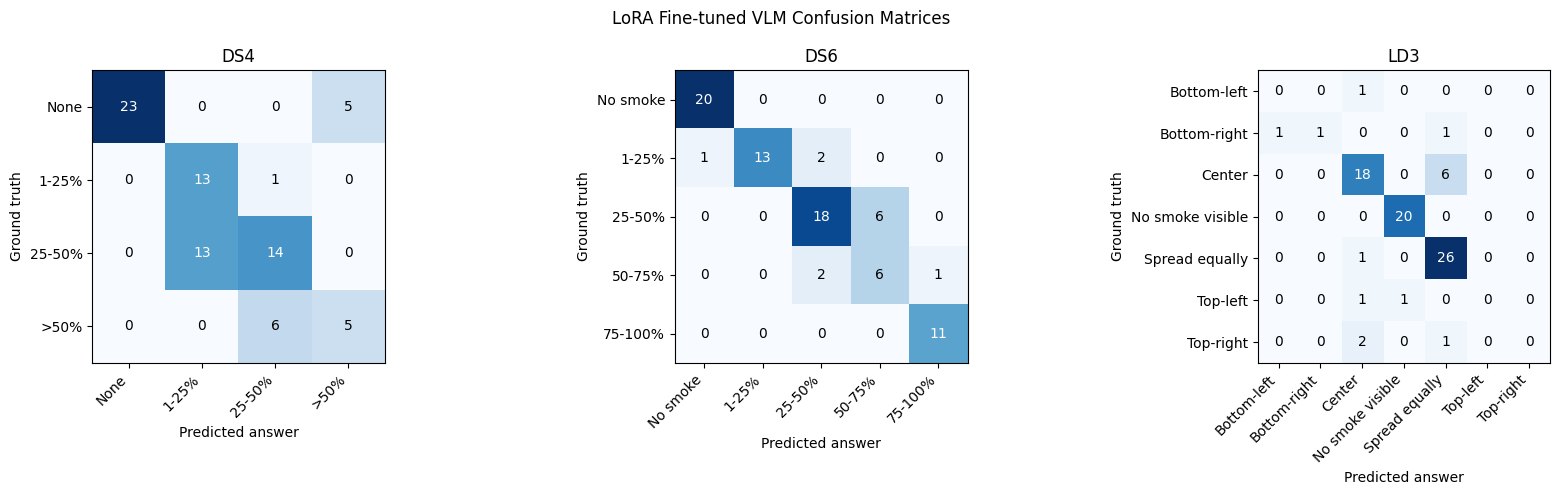

In [75]:
# Confusion matrices after LoRA fine-tuning

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, q in zip(axes, targets):

    d = m2[m2.qtype == q]
    names = labels[q]

    cm = confusion_matrix(
        d.gold,
        d.pred,
        labels=names
    )

    ax.imshow(cm, cmap="Blues")

    for i in range(len(names)):
        for j in range(len(names)):

            ax.text(
                j, i, cm[i, j],
                ha="center",
                va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black"
            )

    ax.set_xticks(range(len(names)))
    ax.set_yticks(range(len(names)))

    ax.set_xticklabels(names, rotation=45, ha="right")
    ax.set_yticklabels(names)

    ax.set_title(q)
    ax.set_xlabel("Predicted answer")
    ax.set_ylabel("Ground truth")

fig.suptitle("LoRA Fine-tuned VLM Confusion Matrices")

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_m2_confusion_matrices.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_m2_confusion_matrices.pdf",
    bbox_inches="tight"
)

plt.show()

**What stage 7 tells me:** Task-specific LoRA fine-tuning
substantially improves the performance of Qwen3-VL-2B
on the Sycan Marsh validation split.

Overall accuracy increases from 21.25% to 78.33%,
while updating only 0.301% of the model parameters.

The largest improvement occurs in smoke plume localization
(LD3), where accuracy increases from 3.75% to 81.25%.

Fine-tuning also reduces the concentration of predictions
in the highest coverage bins for DS4 and DS6. However,
some rare spatial categories remain unpredicted.

The fine-tuned VLM achieves performance comparable to
the supervised DINOv2 and CLIP classifiers.

These results demonstrate the potential of parameter-efficient
adaptation for wildfire VQA, but generalization to unseen
burn sites remains untested.

## Stage 8: final table and figures for the report

In [76]:
# 8.1 Consolidated pilot results table

order = [
    "Random",
    "Majority",
    "M0-zeroshot",
    "M0+temp",
    "M3-zeroshot+hint",
    "M1-dinov2-LR",
    "M1-dinov2-Ridge",
    "M1-clip-LR",
    "M1-clip-Ridge",
    "M2-LoRA"
]

available_methods = set(
    all_preds[all_preds.fold == pilot_fold].method
)

assert set(order).issubset(available_methods), "Missing methods"

table = show_table(order, pilot_fold)

table.to_csv(
    work / "results" / "main_table.csv",
    index=False
)

# Export the table for Overleaf
latex_table = table.to_latex(
    index=False,
    escape=True
)

(work / "results" / "main_table.tex").write_text(
    latex_table,
    encoding="utf-8"
)

print("Sycan Marsh pilot results (mean [95% CI]):")
print(table.to_string(index=False))

print("\nCSV and LaTeX tables saved.")

Sycan Marsh pilot results (mean [95% CI]):
          method           DS4 acc        DS4 within1       DS4 bin err           DS6 acc          DS6 within1       DS6 bin err           LD3 acc
          Random 26.2 [18.8, 33.8]  57.5 [48.8, 65.0] 1.29 [1.12, 1.46] 22.5 [12.5, 31.2]    48.8 [33.8, 66.2] 1.57 [1.24, 1.89]   7.5 [0.0, 15.0]
        Majority  17.5 [3.8, 33.8]  86.2 [67.5, 97.5] 0.96 [0.70, 1.25] 30.0 [12.5, 46.2]    61.3 [25.0, 92.6] 1.09 [0.61, 1.63] 30.0 [10.0, 52.5]
     M0-zeroshot  22.5 [3.8, 46.3]  56.2 [31.2, 78.8] 1.48 [0.89, 2.10]  37.5 [7.4, 72.5]    48.8 [21.2, 77.5] 1.36 [0.64, 2.06]   3.8 [0.0, 10.0]
         M0+temp 45.0 [15.0, 72.5]  80.0 [67.5, 91.2] 0.79 [0.42, 1.15]  37.5 [7.4, 72.5]    48.8 [21.2, 77.5] 1.32 [0.61, 2.01]   3.8 [0.0, 10.0]
M3-zeroshot+hint 75.0 [56.2, 91.2] 95.0 [85.0, 100.0] 0.35 [0.10, 0.63] 78.8 [68.8, 88.8]   98.8 [96.2, 100.0] 0.24 [0.11, 0.38]   3.8 [0.0, 10.0]
    M1-dinov2-LR 75.0 [56.2, 91.2] 95.0 [85.0, 100.0] 0.35 [0.10, 0.63] 78.

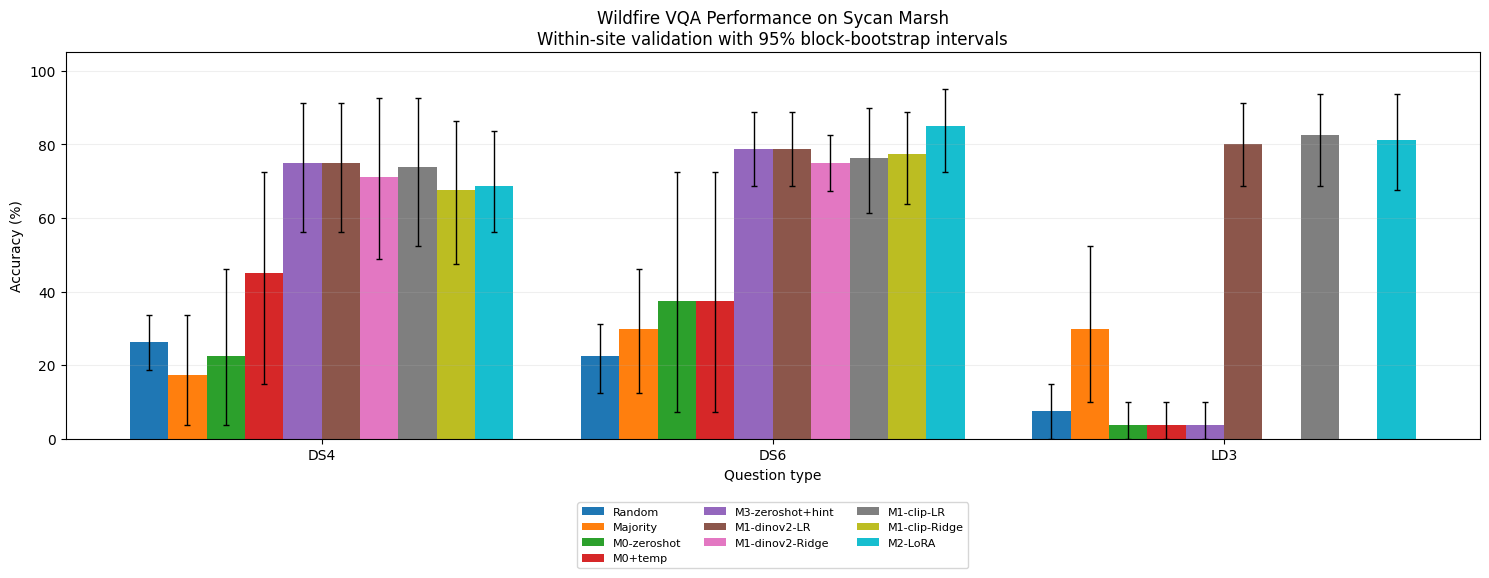

In [77]:
# 8.2 Accuracy with 95% block-bootstrap confidence intervals

qs = list(targets)

fig, ax = plt.subplots(figsize=(15, 6))

x = np.arange(len(qs))
width = 0.85 / len(order)

colors = plt.get_cmap("tab10").colors

for j, m in enumerate(order):

    d = add_scores(
        all_preds[
            (all_preds.method == m) &
            (all_preds.fold == pilot_fold)
        ]
    )

    positions = []
    means = []
    lower_errors = []
    upper_errors = []

    for i, q in enumerate(qs):

        dq = d[d.qtype == q]

        # Ridge does not predict LD3
        if dq.empty:
            continue

        mean, lo, hi = ci(dq, "right")

        if not np.isfinite([mean, lo, hi]).all():
            continue

        position = x[i] + (
            j - (len(order) - 1) / 2
        ) * width

        positions.append(position)
        means.append(100 * mean)

        lower_errors.append(
            max(0, 100 * (mean - lo))
        )

        upper_errors.append(
            max(0, 100 * (hi - mean))
        )

    ax.bar(
        positions,
        means,
        width=width,
        yerr=[lower_errors, upper_errors],
        capsize=2,
        color=colors[j % len(colors)],
        label=m,
        error_kw={"elinewidth": 1}
    )

ax.set_xticks(x)
ax.set_xticklabels(qs)

ax.set_xlabel("Question type")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 105)

ax.set_title(
    "Wildfire VQA Performance on Sycan Marsh\n"
    "Within-site validation with 95% block-bootstrap intervals"
)

ax.grid(axis="y", alpha=0.2)

ax.legend(
    fontsize=8,
    ncol=3,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15)
)

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_accuracy.pdf",
    bbox_inches="tight"
)

plt.show()

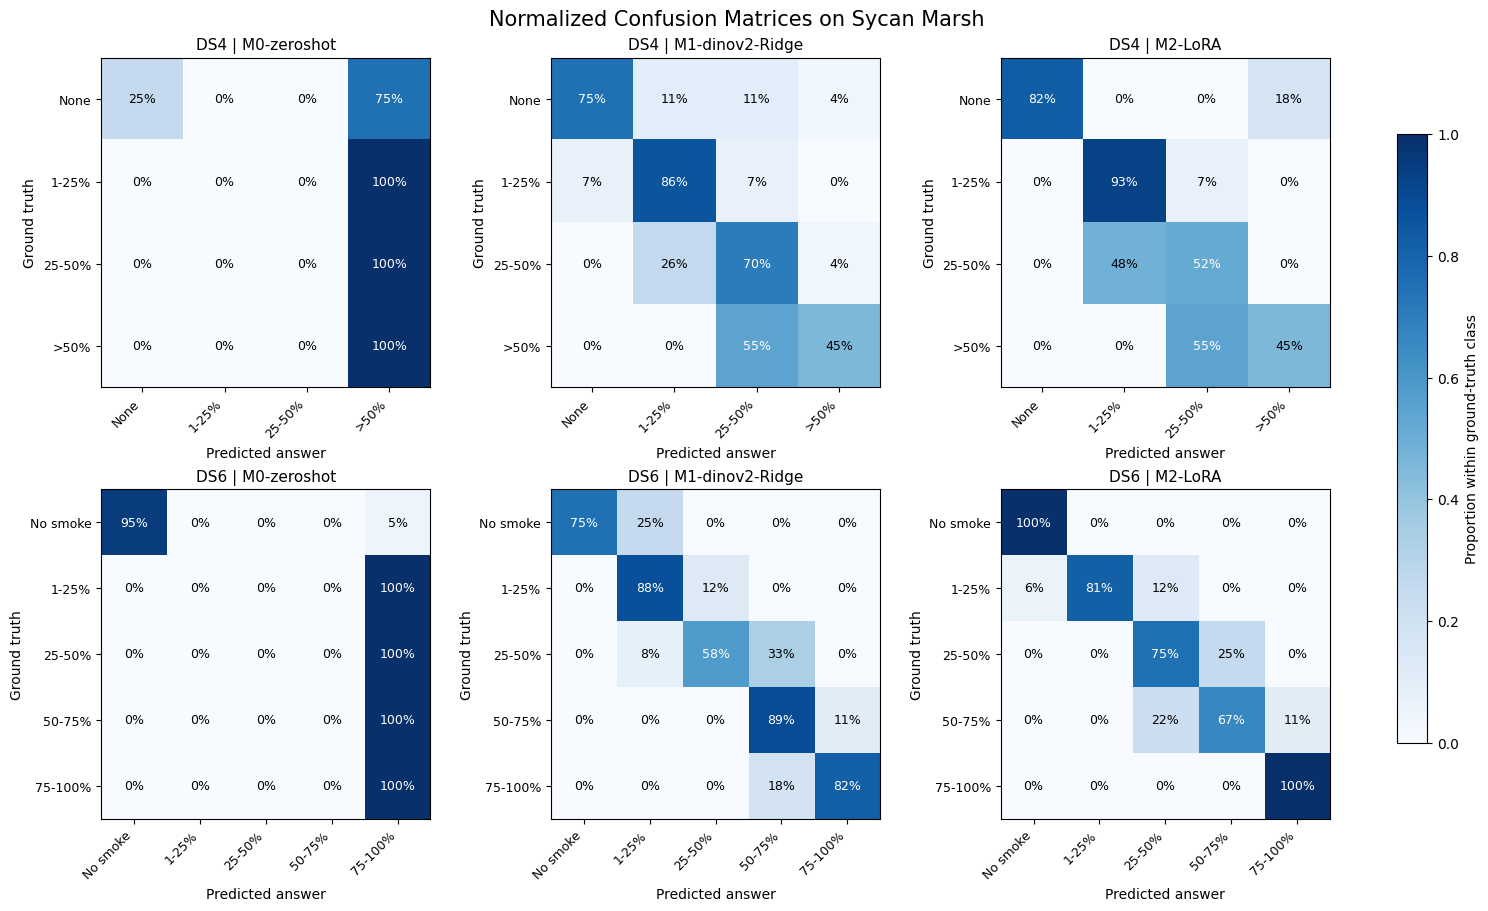

In [78]:
# 8.3 Normalized confusion matrices for ordinal questions

from sklearn.metrics import confusion_matrix

shown = [
    "M0-zeroshot",
    "M1-dinov2-Ridge",
    "M2-LoRA"
]

fig, axes = plt.subplots(
    len(ordinal),
    len(shown),
    figsize=(15, 9),
    squeeze=False,
    constrained_layout=True
)

for i, q in enumerate(ordinal):

    for j, m in enumerate(shown):

        p = all_preds[
            (all_preds.method == m) &
            (all_preds.fold == pilot_fold) &
            (all_preds.qtype == q)
        ].copy()

        assert len(p) == 80, "Unexpected prediction count"

        names = list(labels[q])

        # Preserve invalid predictions as a separate category
        pred = p.pred.where(
            p.pred.isin(names),
            "Unparsed"
        )

        cm = confusion_matrix(
            p.gold,
            pred,
            labels=names + ["Unparsed"]
        ).astype(float)

        # Remove the unused ground-truth row
        cm = cm[:-1, :]

        # Normalize by ground-truth class
        cm = cm / np.maximum(
            cm.sum(axis=1, keepdims=True), 1
        )

        # Hide the unparsed column if it is empty
        if cm[:, -1].sum() == 0:
            cm = cm[:, :-1]
            pred_names = names
        else:
            pred_names = names + ["Unparsed"]

        ax = axes[i, j]

        im = ax.imshow(
            cm,
            vmin=0,
            vmax=1,
            cmap="Blues"
        )

        # Display normalized percentages
        for a in range(cm.shape[0]):
            for b in range(cm.shape[1]):

                ax.text(
                    b, a,
                    f"{100 * cm[a, b]:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="white" if cm[a, b] > 0.5 else "black"
                )

        ax.set_xticks(range(len(pred_names)))
        ax.set_yticks(range(len(names)))

        ax.set_xticklabels(
            pred_names,
            rotation=45,
            ha="right",
            fontsize=9
        )

        ax.set_yticklabels(names, fontsize=9)

        ax.set_title(f"{q} | {m}", fontsize=11)
        ax.set_xlabel("Predicted answer")
        ax.set_ylabel("Ground truth")

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.8,
    label="Proportion within ground-truth class"
)

fig.suptitle(
    "Normalized Confusion Matrices on Sycan Marsh",
    fontsize=15
)

plt.savefig(
    work / "figures" / "fig_confusion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_confusion.pdf",
    bbox_inches="tight"
)

plt.show()

In [79]:
# 8.4 Cross-site generalization analysis

expected_burns = {
    "shoetank",
    "sycan_marsh",
    "willamette"
}

cross_methods = [
    "Majority",
    "M1-dinov2-LR",
    "M1-dinov2-Ridge",
    "M1-clip-LR"
]

chosen = all_preds[
    all_preds.method.isin(cross_methods) &
    all_preds.fold.isin(expected_burns)
].copy()

# Check whether cross-site predictions are available
available_burns = set(
    chosen[chosen.method == "M1-dinov2-LR"].fold
)

missing_burns = expected_burns - available_burns

if missing_burns:

    print("Cross-site evaluation is pending.")
    print("Completed cross-site folds:", sorted(available_burns))
    print("Missing cross-site folds:", sorted(missing_burns))

    print("\nOnly within-site Sycan Marsh results are available "
          "for the trained models.")

    print("Leave-one-burn-out figure was not generated.")

else:

    chosen["right"] = (
        chosen.gold == chosen.pred
    ).astype(float)

    fig, axes = plt.subplots(
        1, len(qs),
        figsize=(15, 5),
        sharey=True
    )

    for ax, q in zip(axes, qs):

        t = (
            chosen[chosen.qtype == q]
            .groupby(["fold", "method"])
            .right.mean()
            .unstack() * 100
        )

        t.plot(kind="bar", ax=ax)

        ax.set_title(q)
        ax.set_xlabel("Held-out burn")
        ax.set_ylabel("Accuracy (%)")
        ax.set_ylim(0, 100)
        ax.tick_params(axis="x", rotation=20)

    fig.suptitle("Leave-One-Burn-Out Evaluation")

    plt.tight_layout()

    plt.savefig(
        work / "figures" / "fig_leave_one_burn_out.png",
        dpi=300, bbox_inches="tight"
    )

    plt.savefig(
        work / "figures" / "fig_leave_one_burn_out.pdf",
        bbox_inches="tight"
    )

    plt.show()

Cross-site evaluation is pending.
Completed cross-site folds: []
Missing cross-site folds: ['shoetank', 'sycan_marsh', 'willamette']

Only within-site Sycan Marsh results are available for the trained models.
Leave-one-burn-out figure was not generated.


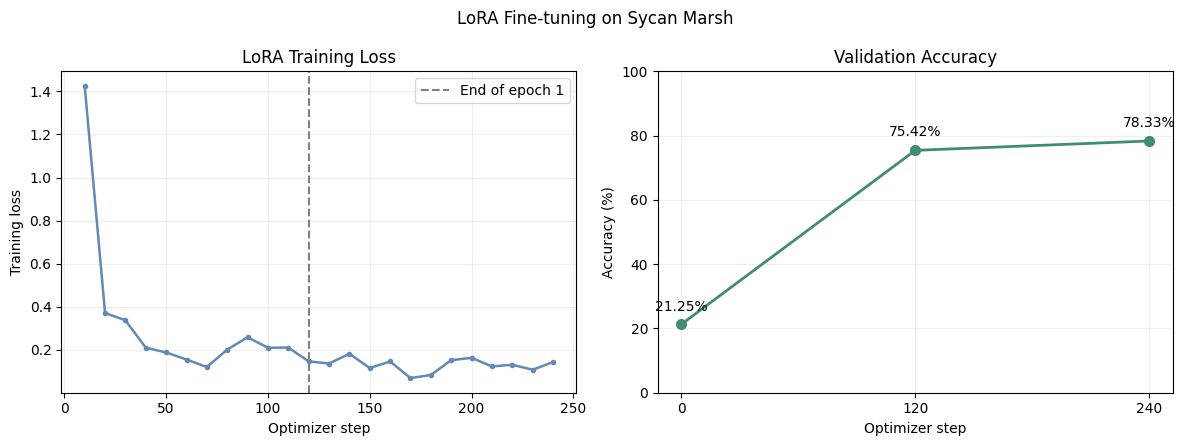

In [80]:
# 8.5 LoRA training loss and validation accuracy

lg = pd.read_csv(work / "results" / "lora_log.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Training loss
a = lg.dropna(subset=["loss"])

axes[0].plot(
    a.step,
    a.loss,
    color="#6489B5",
    marker="o",
    markersize=3,
    linewidth=1.8
)

axes[0].axvline(
    x=120,
    color="gray",
    linestyle="--",
    label="End of epoch 1"
)

axes[0].set_title("LoRA Training Loss")
axes[0].set_xlabel("Optimizer step")
axes[0].set_ylabel("Training loss")
axes[0].grid(alpha=0.2)
axes[0].legend()

# Validation accuracy
b = lg.dropna(subset=["val_acc"])

steps = [0] + b.step.tolist()

accuracies = [
    100 * (m0.pred == m0.gold).mean()
] + (100 * b.val_acc).tolist()

axes[1].plot(
    steps,
    accuracies,
    "o-",
    color="#438C70",
    linewidth=2,
    markersize=7
)

for x, y in zip(steps, accuracies):
    axes[1].annotate(
        f"{y:.2f}%",
        (x, y),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Optimizer step")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(0, 100)
axes[1].set_xticks(steps)
axes[1].grid(alpha=0.2)

fig.suptitle("LoRA Fine-tuning on Sycan Marsh")

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_lora_training.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_lora_training.pdf",
    bbox_inches="tight"
)

plt.show()

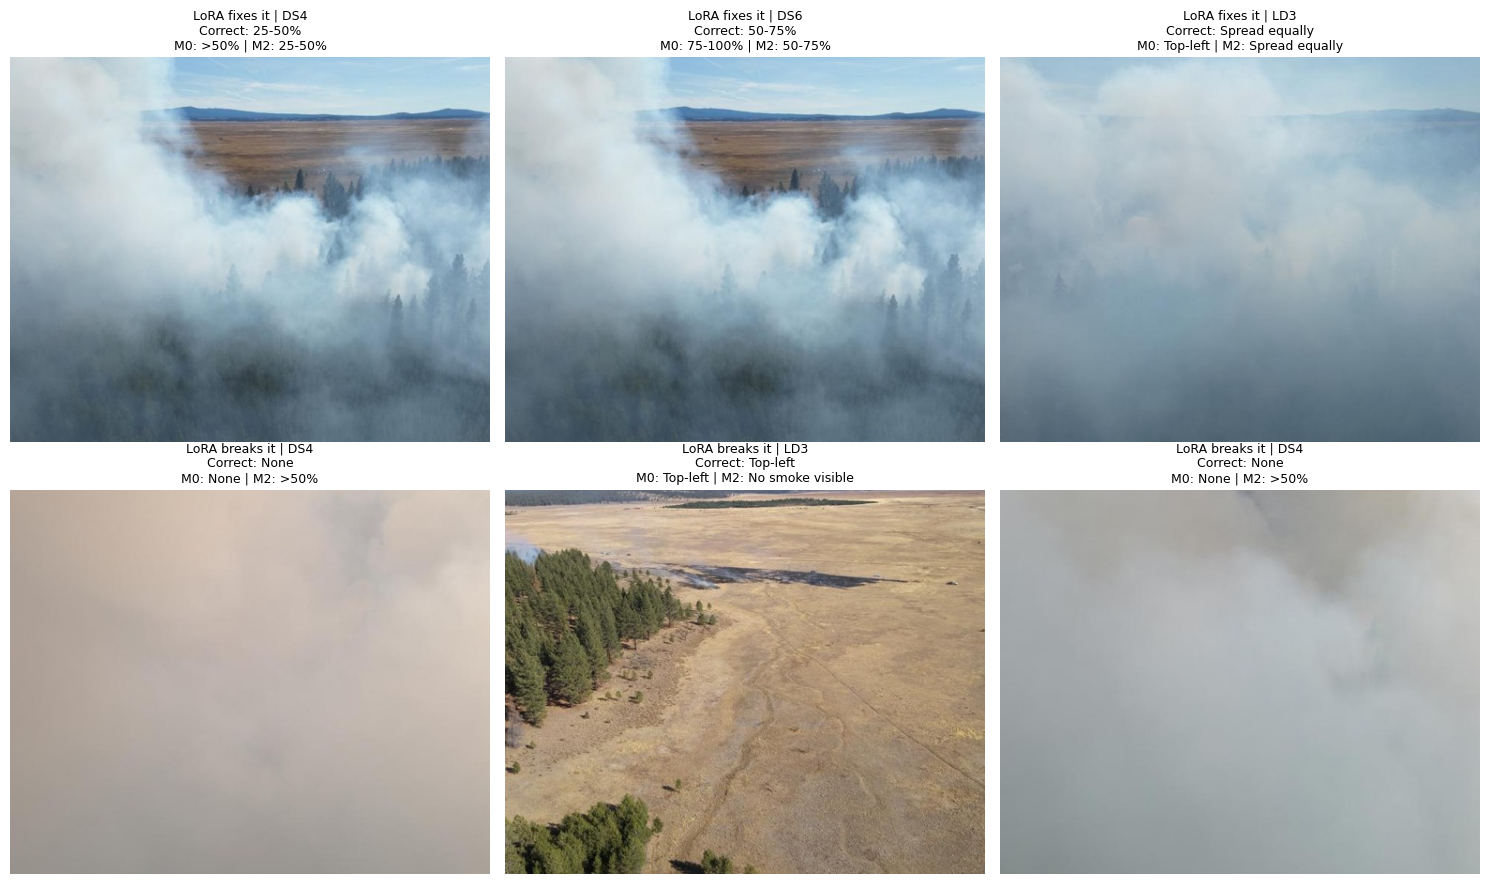

Examples shown: 6
LoRA fixes: 3 | LoRA breaks: 3


In [81]:
# 8.6 Qualitative examples: where did LoRA help or hurt?

a = all_preds[
    (all_preds.method == "M0-zeroshot") &
    (all_preds.fold == pilot_fold)
].set_index(["frame", "qtype"])

b = all_preds[
    (all_preds.method == "M2-LoRA") &
    (all_preds.fold == pilot_fold)
].set_index(["frame", "qtype"])

both = a.join(
    b,
    lsuffix="_m0",
    rsuffix="_m2",
    how="inner"
).reset_index()

# Sanity check: gold labels should match
assert (both.gold_m0 == both.gold_m2).all()

both["gold"] = both.gold_m0

fixed = both[
    (both.pred_m0 != both.gold) &
    (both.pred_m2 == both.gold)
].copy()

broken = both[
    (both.pred_m0 == both.gold) &
    (both.pred_m2 != both.gold)
].copy()

# Try to keep examples diverse across question types
fixed = (
    fixed.sort_values(["qtype", "frame"])
    .groupby("qtype", group_keys=False)
    .head(1)
)

broken = (
    broken.sort_values(["qtype", "frame"])
    .groupby("qtype", group_keys=False)
    .head(1)
)

# If fewer than 3 after diversity filtering, fill remaining slots
if len(fixed) < 3:
    extra_fixed = both[
        (both.pred_m0 != both.gold) &
        (both.pred_m2 == both.gold) &
        ~both.index.isin(fixed.index)
    ].head(3 - len(fixed))
    fixed = pd.concat([fixed, extra_fixed])

if len(broken) < 3:
    extra_broken = both[
        (both.pred_m0 == both.gold) &
        (both.pred_m2 != both.gold) &
        ~both.index.isin(broken.index)
    ].head(3 - len(broken))
    broken = pd.concat([broken, extra_broken])

fixed = fixed.head(3).assign(kind="LoRA fixes it")
broken = broken.head(3).assign(kind="LoRA breaks it")

examples = pd.concat([fixed, broken], ignore_index=True)

img_of = dict(zip(subset.frame, subset.img_local))

if len(examples) == 0:
    print("No examples where M0 and M2 differ.")
else:
    n = len(examples)
    ncols = 3
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, (_, r) in zip(axes, examples.iterrows()):
        ax.imshow(Image.open(img_of[r.frame]))
        ax.axis("off")
        ax.set_title(
            f"{r.kind} | {r.qtype}\n"
            f"Correct: {r.gold}\n"
            f"M0: {r.pred_m0} | M2: {r.pred_m2}",
            fontsize=9
        )

    # Hide unused axes
    for ax in axes[len(examples):]:
        ax.axis("off")

    plt.tight_layout()

    plt.savefig(
        work / "figures" / "fig_examples.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        work / "figures" / "fig_examples.pdf",
        bbox_inches="tight"
    )

    plt.show()

    print("Examples shown:", len(examples))
    print("LoRA fixes:", len(fixed), "| LoRA breaks:", len(broken))

In [ ]:
# 8.7 save everything for the report
shutil.make_archive("/content/results_for_report", "zip", str(work / "results"))
shutil.make_archive("/content/figures_for_report", "zip", str(work / "figures"))
print("everything is in", work)
print("also zipped in the Files panel: results_for_report.zip and figures_for_report.zip")

In [82]:
# 8.7 Export results and figures for the research report

import shutil
from pathlib import Path

export_dir = work / "exports"
export_dir.mkdir(parents=True, exist_ok=True)

# Save separate archives on Google Drive
for folder in ["results", "figures"]:

    archive = shutil.make_archive(
        str(export_dir / f"{folder}_for_report"),
        "zip",
        root_dir=str(work),
        base_dir=folder
    )

    # Copy to Colab for easy downloading
    shutil.copy2(archive, "/content/")

# Create one combined archive
report_dir = Path("/content/wildfire_vqa_report")

report_dir.mkdir(parents=True, exist_ok=True)

for folder in ["results", "figures"]:
    shutil.copytree(
        work / folder,
        report_dir / folder,
        dirs_exist_ok=True
    )

combined = shutil.make_archive(
    str(export_dir / "wildfire_vqa_report"),
    "zip",
    root_dir=str(report_dir)
)

shutil.copy2(combined, "/content/")

print("Report export completed.")

print("\nTotal result files:",
      len(list((work / "results").glob("*"))))

print("Total figure files:",
      len(list((work / "figures").glob("*"))))

print("\nSaved archives:")

for p in sorted(export_dir.glob("*.zip")):
    print(f"{p.name}: {p.stat().st_size / 1024**2:.2f} MB")

print("\nPermanent location:", export_dir)
print("Downloadable copies are also available in Colab Files.")

Report export completed.

Total result files: 20
Total figure files: 44

Saved archives:
figures_for_report.zip: 13.47 MB
results_for_report.zip: 0.04 MB
wildfire_vqa_report.zip: 13.50 MB

Permanent location: /content/drive/MyDrive/wildfire_vqa_study/exports
Downloadable copies are also available in Colab Files.


In [83]:
from google.colab import files

files.download("/content/wildfire_vqa_report.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Stage 9: Visual grounding and robustness analysis

I evaluate the dependence of the zero-shot and fine-tuned
models on visual information using blank images, shuffled
images, and shuffled answer options.

All experiments use the same 80 validation frames and
240 questions to ensure consistent comparisons.

These controls help investigate whether the observed
improvements depend on relevant visual information or
learned answer patterns.

In [84]:
# 9.1 Blank image control for M0 and M2

from PIL import Image

model.eval()

# Preserve the original image loader
original_load_image = load_image

def blank_load_image(path):
    im = original_load_image(path)

    # Preserve image dimensions but remove visual content
    return Image.new("RGB", im.size, (128, 128, 128))


print("Evaluation questions:", len(test_rows))
print("Evaluation frames:", test_rows.frame.nunique())

try:
    load_image = blank_load_image

    # Evaluate the original model without LoRA
    with model.disable_adapter():

        m0_blank = run_all(
            model,
            test_rows,
            desc="M0 Blank"
        )

    # Evaluate the fine-tuned model
    m2_blank = run_all(
        model,
        test_rows,
        desc="M2 Blank"
    )

finally:
    # Restore the original image loader
    load_image = original_load_image


# Verify prediction alignment
for d in [m0_blank, m2_blank]:

    assert len(d) == len(test_rows)

    assert d[["frame", "qtype", "gold"]].equals(
        test_rows[["frame", "qtype", "gold"]]
        .reset_index(drop=True)
    )


# Save predictions
save_preds(m0_blank, "M0-blank", pilot_fold)
save_preds(m2_blank, "M2-blank", pilot_fold)

m0_blank.to_csv(
    work / "results" / "m0_blank_predictions.csv",
    index=False
)

m2_blank.to_csv(
    work / "results" / "m2_blank_predictions.csv",
    index=False
)

# Compare original and blank-image performance
blank_methods = [
    "Random",
    "Majority",
    "M0-zeroshot",
    "M0-blank",
    "M2-LoRA",
    "M2-blank"
]

blank_table = show_table(blank_methods, pilot_fold)

print("\nBlank image control results:")
print(blank_table.to_string(index=False))

blank_table.to_csv(
    work / "results" / "blank_image_control.csv",
    index=False
)

print("\nOverall accuracy:")

for name, d in [
    ("M0 Original", m0),
    ("M0 Blank", m0_blank),
    ("M2 Original", m2),
    ("M2 Blank", m2_blank)
]:
    print(
        name,
        "| Accuracy:",
        round(100 * (d.pred == d.gold).mean(), 2),
        "% | Unparsed:", int(d.pred.isna().sum())
    )

print("\nBlank image experiment completed.")
print("Original image loader restored.")

Evaluation questions: 240
Evaluation frames: 80


M0 Blank:   0%|          | 0/240 [00:00<?, ?it/s]

M2 Blank:   0%|          | 0/240 [00:00<?, ?it/s]


Blank image control results:
     method           DS4 acc        DS4 within1       DS4 bin err           DS6 acc          DS6 within1       DS6 bin err           LD3 acc
     Random 26.2 [18.8, 33.8]  57.5 [48.8, 65.0] 1.29 [1.12, 1.46] 22.5 [12.5, 31.2]    48.8 [33.8, 66.2] 1.57 [1.24, 1.89]   7.5 [0.0, 15.0]
   Majority  17.5 [3.8, 33.8]  86.2 [67.5, 97.5] 0.96 [0.70, 1.25] 30.0 [12.5, 46.2]    61.3 [25.0, 92.6] 1.09 [0.61, 1.63] 30.0 [10.0, 52.5]
M0-zeroshot  22.5 [3.8, 46.3]  56.2 [31.2, 78.8] 1.48 [0.89, 2.10]  37.5 [7.4, 72.5]    48.8 [21.2, 77.5] 1.36 [0.64, 2.06]   3.8 [0.0, 10.0]
   M0-blank  35.0 [0.0, 70.0]  52.5 [27.5, 78.8] 1.26 [0.61, 1.86]  25.0 [0.0, 62.5]    45.0 [20.0, 71.2] 1.69 [0.84, 2.55]  25.0 [0.0, 62.5]
    M2-LoRA 68.8 [56.2, 83.8] 93.8 [81.2, 100.0] 0.44 [0.19, 0.76] 85.0 [72.5, 95.0] 100.0 [100.0, 100.0] 0.15 [0.05, 0.28] 81.2 [67.5, 93.8]
   M2-blank  35.0 [0.0, 70.0]  52.5 [27.5, 78.8] 1.26 [0.61, 1.86]  20.0 [5.0, 38.8]    75.0 [50.0, 95.0] 1.19 [0.72, 

**Blank image observation:** Removing visual information
reduces the fine-tuned model's overall accuracy from
78.33% to 26.67%.

In contrast, the zero-shot model's accuracy increases
from 21.25% to 28.33%.

These results suggest that task-specific adaptation
increases the model's reliance on visual information.
However, blank images are out-of-distribution inputs,
so additional shuffled-image controls are required.

In [86]:
# 9.2 Shuffled image control for M0 and M2
rng = np.random.default_rng(42)

frame_info = (
    test_rows[["frame", "img_local", "block"]]
    .drop_duplicates("frame")
    .reset_index(drop=True)
)

n = len(frame_info)

# Group frames by block
groups = [
    g.index.to_numpy()
    for _, g in frame_info.groupby("block")
]

# Randomize block order
rng.shuffle(groups)

# Randomize frames within each block
groups = [
    rng.permutation(g)
    for g in groups
]

# Arrange frames by randomized blocks
ordered_indices = np.concatenate(groups)

# Find the largest block size
max_block_size = max(len(g) for g in groups)

assert 2 * max_block_size <= n, "Block size is too large"

# Rotate indices to avoid same-block assignments
shifted_indices = np.roll(
    ordered_indices,
    max_block_size
)

shuffled_indices = np.empty(n, dtype=int)
shuffled_indices[ordered_indices] = shifted_indices

original_indices = np.arange(n)

# Verify the shuffled mapping
assert np.all(original_indices != shuffled_indices)

assert np.all(
    frame_info.block.to_numpy() !=
    frame_info.block.to_numpy()[shuffled_indices]
)

assert len(np.unique(shuffled_indices)) == n

print("Valid shuffled mapping generated.")
print("Total frames:", n)
print("Total blocks:", len(groups))
print("Same-frame assignments: 0")
print("Same-block assignments: 0")

# Save the shuffled image mapping
shuffle_mapping = pd.DataFrame({
    "original_frame": frame_info.frame,
    "shuffled_frame": frame_info.frame.iloc[
        shuffled_indices
    ].to_numpy(),
    "original_block": frame_info.block,
    "shuffled_block": frame_info.block.iloc[
        shuffled_indices
    ].to_numpy(),
    "shuffled_image": frame_info.img_local.iloc[
        shuffled_indices
    ].to_numpy()
})

assert shuffle_mapping.original_frame.is_unique
assert shuffle_mapping.shuffled_frame.is_unique

assert (
    shuffle_mapping.original_frame !=
    shuffle_mapping.shuffled_frame
).all()

assert (
    shuffle_mapping.original_block !=
    shuffle_mapping.shuffled_block
).all()

shuffle_mapping.to_csv(
    work / "results" / "shuffled_image_mapping.csv",
    index=False
)

# Replace only image paths, preserving original questions and labels
shuffled_rows = test_rows.copy()

shuffled_rows["img_local"] = shuffled_rows.frame.map(
    dict(zip(
        shuffle_mapping.original_frame,
        shuffle_mapping.shuffled_image
    ))
)

assert shuffled_rows.img_local.notna().all()

print("Shuffled frames:", len(shuffle_mapping))
print("Evaluation questions:", len(shuffled_rows))
print("Same-frame assignments: 0")
print("Same-block assignments: 0")

print("\nExample shuffled mapping:")
print(shuffle_mapping[
    ["original_frame", "shuffled_frame"]
].head(3).to_string(index=False))


model.eval()

# Evaluate the zero-shot model
with model.disable_adapter():

    m0_shuffled = run_all(
        model,
        shuffled_rows,
        desc="M0 Shuffled"
    )

# Evaluate the fine-tuned model
m2_shuffled = run_all(
    model,
    shuffled_rows,
    desc="M2 Shuffled"
)

# Verify prediction alignment
for d in [m0_shuffled, m2_shuffled]:

    assert len(d) == len(test_rows)

    assert d[["frame", "qtype", "gold"]].equals(
        test_rows[["frame", "qtype", "gold"]]
        .reset_index(drop=True)
    )


# Save predictions
save_preds(
    m0_shuffled, "M0-shuffled", pilot_fold
)

save_preds(
    m2_shuffled, "M2-shuffled", pilot_fold
)

m0_shuffled.to_csv(
    work / "results" / "m0_shuffled_predictions.csv",
    index=False
)

m2_shuffled.to_csv(
    work / "results" / "m2_shuffled_predictions.csv",
    index=False
)


# Compare visual grounding controls
control_methods = [
    "Random",
    "Majority",
    "M0-zeroshot",
    "M0-blank",
    "M0-shuffled",
    "M2-LoRA",
    "M2-blank",
    "M2-shuffled"
]

control_table = show_table(
    control_methods, pilot_fold
)

print("\nVisual grounding control results:")
print(control_table.to_string(index=False))

control_table.to_csv(
    work / "results" / "visual_grounding_results.csv",
    index=False
)

print("\nOverall accuracy:")

for name, d in [
    ("M0 Original", m0),
    ("M0 Blank", m0_blank),
    ("M0 Shuffled", m0_shuffled),
    ("M2 Original", m2),
    ("M2 Blank", m2_blank),
    ("M2 Shuffled", m2_shuffled)
]:

    print(
        name,
        "| Accuracy:",
        round(100 * (d.pred == d.gold).mean(), 2),
        "% | Unparsed:", int(d.pred.isna().sum())
    )

print("\nShuffled image experiment completed.")

Valid shuffled mapping generated.
Total frames: 80
Total blocks: 8
Same-frame assignments: 0
Same-block assignments: 0
Shuffled frames: 80
Evaluation questions: 240
Same-frame assignments: 0
Same-block assignments: 0

Example shuffled mapping:
                                                                                                       original_frame                                                                                                        shuffled_frame
/home/mhabibp/Downloads/flame3333/Flame 3 Computer Vision Sets/Sycan/Sycan 2A/Images/Fire/RGB/Corrected FOV/00075.JPG /home/mhabibp/Downloads/flame3333/Flame 3 Computer Vision Sets/Sycan/Sycan 2A/Images/Fire/RGB/Corrected FOV/00173.JPG
/home/mhabibp/Downloads/flame3333/Flame 3 Computer Vision Sets/Sycan/Sycan 2A/Images/Fire/RGB/Corrected FOV/00077.JPG /home/mhabibp/Downloads/flame3333/Flame 3 Computer Vision Sets/Sycan/Sycan 2A/Images/Fire/RGB/Corrected FOV/00176.JPG
/home/mhabibp/Downloads/flame3333/Flame 3 Comput

M0 Shuffled:   0%|          | 0/240 [00:00<?, ?it/s]

M2 Shuffled:   0%|          | 0/240 [00:00<?, ?it/s]


Visual grounding control results:
     method           DS4 acc        DS4 within1       DS4 bin err           DS6 acc          DS6 within1       DS6 bin err           LD3 acc
     Random 26.2 [18.8, 33.8]  57.5 [48.8, 65.0] 1.29 [1.12, 1.46] 22.5 [12.5, 31.2]    48.8 [33.8, 66.2] 1.57 [1.24, 1.89]   7.5 [0.0, 15.0]
   Majority  17.5 [3.8, 33.8]  86.2 [67.5, 97.5] 0.96 [0.70, 1.25] 30.0 [12.5, 46.2]    61.3 [25.0, 92.6] 1.09 [0.61, 1.63] 30.0 [10.0, 52.5]
M0-zeroshot  22.5 [3.8, 46.3]  56.2 [31.2, 78.8] 1.48 [0.89, 2.10]  37.5 [7.4, 72.5]    48.8 [21.2, 77.5] 1.36 [0.64, 2.06]   3.8 [0.0, 10.0]
   M0-blank  35.0 [0.0, 70.0]  52.5 [27.5, 78.8] 1.26 [0.61, 1.86]  25.0 [0.0, 62.5]    45.0 [20.0, 71.2] 1.69 [0.84, 2.55]  25.0 [0.0, 62.5]
M0-shuffled  12.5 [2.5, 28.7]  41.2 [18.8, 63.7] 1.82 [1.30, 2.42]  13.8 [0.0, 38.8]     26.2 [6.2, 50.0] 2.29 [1.45, 3.12]    1.2 [0.0, 3.8]
    M2-LoRA 68.8 [56.2, 83.8] 93.8 [81.2, 100.0] 0.44 [0.19, 0.76] 85.0 [72.5, 95.0] 100.0 [100.0, 100.0] 0.15 [0

In [87]:
# 9.3 Answer option order robustness

rng = np.random.default_rng(42)

option_rows = test_rows.copy()

def shuffle_options(options):

    original = list(options)

    # Ensure that the new order is different
    while True:

        shuffled = rng.permutation(original).tolist()

        if shuffled != original:
            return shuffled


option_rows["options"] = option_rows.options.apply(
    shuffle_options
)

# Verify that no answer options were added or removed
for old, new in zip(
    test_rows.options,
    option_rows.options
):

    assert sorted(old) == sorted(new)
    assert list(old) != list(new)

assert option_rows[["frame", "qtype", "gold"]].equals(
    test_rows[["frame", "qtype", "gold"]]
)

assert option_rows.img_local.equals(test_rows.img_local)

print("Evaluation questions:", len(option_rows))
print("Questions with changed option order:", len(option_rows))

# Save the exact option orders for reproducibility
option_mapping = pd.DataFrame({
    "frame": test_rows.frame,
    "qtype": test_rows.qtype,
    "gold": test_rows.gold,
    "original_options": test_rows.options,
    "shuffled_options": option_rows.options
})

option_mapping.to_csv(
    work / "results" / "shuffled_option_mapping.csv",
    index=False
)

print("\nExample original options:")
print(test_rows.options.iloc[0])

print("\nExample shuffled options:")
print(option_rows.options.iloc[0])


model.eval()

# Evaluate the original model
with model.disable_adapter():

    m0_options = run_all(
        model,
        option_rows,
        desc="M0 Shuffled Options"
    )

# Evaluate the fine-tuned model
m2_options = run_all(
    model,
    option_rows,
    desc="M2 Shuffled Options"
)

# Verify prediction alignment
for d in [m0_options, m2_options]:

    assert len(d) == len(test_rows)

    assert d[["frame", "qtype", "gold"]].equals(
        test_rows[["frame", "qtype", "gold"]]
        .reset_index(drop=True)
    )

# Save predictions
save_preds(
    m0_options, "M0-shuffled-options", pilot_fold
)

save_preds(
    m2_options, "M2-shuffled-options", pilot_fold
)

m0_options.to_csv(
    work / "results" / "m0_shuffled_options_predictions.csv",
    index=False
)

m2_options.to_csv(
    work / "results" / "m2_shuffled_options_predictions.csv",
    index=False
)

option_table = show_table([
    "M0-zeroshot",
    "M0-shuffled-options",
    "M2-LoRA",
    "M2-shuffled-options"
], pilot_fold)

print("\nOption-order robustness results:")
print(option_table.to_string(index=False))

option_table.to_csv(
    work / "results" / "option_order_results.csv",
    index=False
)

# Compare accuracy and prediction consistency
for name, original, shuffled in [
    ("M0", m0, m0_options),
    ("M2", m2, m2_options)
]:

    paired = original.merge(
        shuffled[["frame", "qtype", "pred"]],
        on=["frame", "qtype"],
        suffixes=("_original", "_shuffled"),
        validate="one_to_one"
    )

    print(f"\n{name}:")

    print("Original accuracy:",
          round(100 * (original.pred == original.gold).mean(), 2))

    print("Shuffled-option accuracy:",
          round(100 * (shuffled.pred == shuffled.gold).mean(), 2))

    print("Prediction consistency:",
          round(100 * (
              paired.pred_original == paired.pred_shuffled
          ).mean(), 2), "%")

    print("Unparseable answers:",
          int(shuffled.pred.isna().sum()))

print("\nOption-order robustness experiment completed.")

Evaluation questions: 240
Questions with changed option order: 240

Example original options:
['1-25%', '25-50%', '>50%', 'None']

Example shuffled options:
['None', '>50%', '25-50%', '1-25%']


M0 Shuffled Options:   0%|          | 0/240 [00:00<?, ?it/s]

M2 Shuffled Options:   0%|          | 0/240 [00:00<?, ?it/s]


Option-order robustness results:
             method           DS4 acc        DS4 within1       DS4 bin err           DS6 acc          DS6 within1       DS6 bin err           LD3 acc
        M0-zeroshot  22.5 [3.8, 46.3]  56.2 [31.2, 78.8] 1.48 [0.89, 2.10]  37.5 [7.4, 72.5]    48.8 [21.2, 77.5] 1.36 [0.64, 2.06]   3.8 [0.0, 10.0]
M0-shuffled-options 33.8 [15.0, 56.2]  60.0 [37.5, 81.2] 1.27 [0.72, 1.85]  32.5 [7.4, 62.5]    47.5 [22.5, 72.5] 1.48 [0.79, 2.10]   5.0 [1.2, 11.2]
            M2-LoRA 68.8 [56.2, 83.8] 93.8 [81.2, 100.0] 0.44 [0.19, 0.76] 85.0 [72.5, 95.0] 100.0 [100.0, 100.0] 0.15 [0.05, 0.28] 81.2 [67.5, 93.8]
M2-shuffled-options 75.0 [58.7, 90.0] 96.2 [88.8, 100.0] 0.33 [0.12, 0.54] 81.2 [67.5, 93.8] 100.0 [100.0, 100.0] 0.19 [0.06, 0.33] 81.2 [67.5, 93.8]

M0:
Original accuracy: 21.25
Shuffled-option accuracy: 23.75
Prediction consistency: 76.67 %
Unparseable answers: 0

M2:
Original accuracy: 78.33
Shuffled-option accuracy: 79.17
Prediction consistency: 93.33 %
Unpar

In [88]:
# 9.4 Combined visual grounding and robustness analysis

conditions = {
    "Original RGB": ("M0-zeroshot", "M2-LoRA"),
    "Blank image": ("M0-blank", "M2-blank"),
    "Shuffled image": ("M0-shuffled", "M2-shuffled"),
    "Shuffled options": (
        "M0-shuffled-options",
        "M2-shuffled-options"
    )
}

records = []

for condition, methods in conditions.items():

    for model_name, method in zip(["M0", "M2"], methods):

        p = all_preds[
            (all_preds.method == method) &
            (all_preds.fold == pilot_fold)
        ].copy()

        assert len(p) == 240
        assert not p.duplicated(["frame", "qtype"]).any()

        p = add_scores(p)

        for q in ["Overall"] + list(targets):

            d = p if q == "Overall" else p[p.qtype == q]

            mean, lo, hi = ci(d, "right")

            records.append({
                "model": model_name,
                "condition": condition,
                "qtype": q,
                "n": len(d),
                "accuracy": 100 * mean,
                "ci_lower": 100 * lo,
                "ci_upper": 100 * hi
            })

robustness = pd.DataFrame(records)

robustness.to_csv(
    work / "results" / "robustness_summary.csv",
    index=False
)

print("Overall robustness results:")

print(
    robustness[robustness.qtype == "Overall"]
    .round(2)
    .to_string(index=False)
)

Overall robustness results:
model        condition   qtype   n  accuracy  ci_lower  ci_upper
   M0     Original RGB Overall 240     21.25      8.33     35.42
   M2     Original RGB Overall 240     78.33     68.75     89.17
   M0      Blank image Overall 240     28.33      0.00     62.50
   M2      Blank image Overall 240     26.67     11.25     44.59
   M0   Shuffled image Overall 240      9.17      1.67     19.17
   M2   Shuffled image Overall 240      8.33      1.25     17.51
   M0 Shuffled options Overall 240     23.75     12.92     36.25
   M2 Shuffled options Overall 240     79.17     68.31     90.83


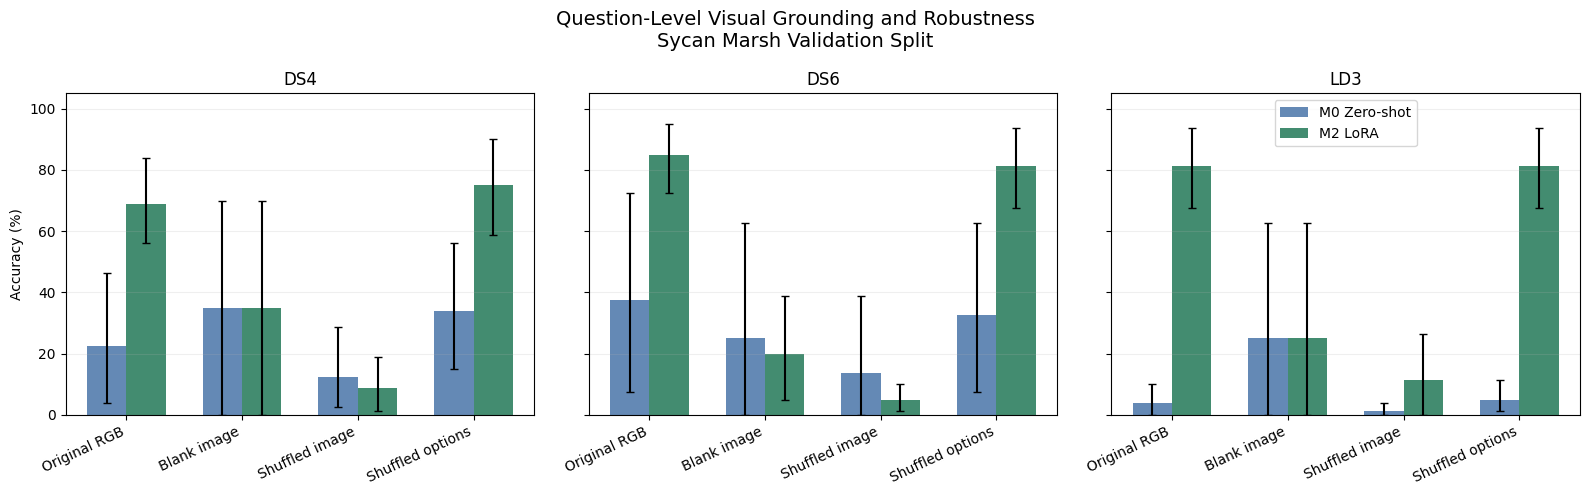

Question-wise robustness figures saved.


In [90]:
# 9.4.2 Question-wise robustness figure

robust_colors = {
    "M0": "#6489B5",
    "M2": "#438C70"
}

robust_conditions = [
    "Original RGB",
    "Blank image",
    "Shuffled image",
    "Shuffled options"
]

x = np.arange(len(robust_conditions))
width = 0.34

fig, axes = plt.subplots(
    1, len(targets),
    figsize=(16, 5),
    sharey=True
)

for ax, q in zip(axes, targets):

    for j, name in enumerate(["M0", "M2"]):

        d = (
            robustness[
                (robustness.model == name) &
                (robustness.qtype == q)
            ]
            .set_index("condition")
            .loc[robust_conditions]
        )

        errors = np.maximum(0, [
            d.accuracy - d.ci_lower,
            d.ci_upper - d.accuracy
        ])

        positions = x + (j - 0.5) * width

        ax.bar(
            positions,
            d.accuracy,
            width,
            yerr=errors,
            capsize=3,
            color=robust_colors[name],
            label="M0 Zero-shot" if name == "M0" else "M2 LoRA"
        )

    ax.set_title(q)
    ax.set_xticks(x)

    ax.set_xticklabels(
        robust_conditions,
        rotation=25,
        ha="right"
    )

    ax.set_ylim(0, 105)
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel("Accuracy (%)")
axes[-1].legend()

fig.suptitle(
    "Question-Level Visual Grounding and Robustness\n"
    "Sycan Marsh Validation Split",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_robustness_by_question.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_robustness_by_question.pdf",
    bbox_inches="tight"
)

plt.show()

print("Question-wise robustness figures saved.")

In [91]:
for p in sorted((work / "figures").glob("fig_robustness*")):
    print(p.name, "|", p.stat().st_size, "bytes")

fig_robustness_by_question.pdf | 19832 bytes
fig_robustness_by_question.png | 193196 bytes


## Stage 10: Paired statistical analysis

I use paired block bootstrap resampling to estimate
the accuracy differences between models evaluated on
the same validation questions.

Resampling is performed at the frame-block level to
account for potential dependence between nearby frames
and questions associated with the same image.

I also evaluate macro-F1 and per-class recall to examine
performance beyond overall accuracy, particularly for
minority answer categories.

In [92]:
# 10.1 Paired block bootstrap for accuracy differences

def paired_bootstrap(method_a, method_b, qtype=None,
                     n_boot=10000, seed=42):

    keys = ["frame", "qtype"]

    a = all_preds[
        (all_preds.method == method_a) &
        (all_preds.fold == pilot_fold)
    ][keys + ["gold", "pred"]].copy()

    b = all_preds[
        (all_preds.method == method_b) &
        (all_preds.fold == pilot_fold)
    ][keys + ["gold", "pred"]].copy()

    if qtype is not None:
        a = a[a.qtype == qtype]
        b = b[b.qtype == qtype]

    # Match predictions for the same questions
    paired = a.merge(
        b,
        on=keys,
        suffixes=("_a", "_b"),
        how="outer",
        indicator=True,
        validate="one_to_one"
    )

    assert (paired["_merge"] == "both").all()
    assert (paired.gold_a == paired.gold_b).all()

    expected_n = 240 if qtype is None else 80
    assert len(paired) == expected_n

    paired["block"] = paired.frame.map(block_of)

    assert paired.block.notna().all()

    paired["correct_a"] = (
        paired.pred_a == paired.gold_a
    ).astype(int)

    paired["correct_b"] = (
        paired.pred_b == paired.gold_b
    ).astype(int)

    paired["difference"] = (
        paired.correct_a - paired.correct_b
    )

    # Aggregate paired differences within blocks
    grouped = paired.groupby("block").difference.agg(
        ["sum", "count"]
    )

    sums = grouped["sum"].to_numpy()
    counts = grouped["count"].to_numpy()

    n_blocks = len(grouped)

    assert n_blocks == 8

    rng = np.random.default_rng(seed)

    # Resample the same blocks for both methods
    sampled = rng.integers(
        0,
        n_blocks,
        size=(n_boot, n_blocks)
    )

    boot = (
        sums[sampled].sum(axis=1) /
        counts[sampled].sum(axis=1)
    )

    observed = paired.difference.mean()

    lo, hi = np.percentile(boot, [2.5, 97.5])

    return {
        "method_a": method_a,
        "method_b": method_b,
        "qtype": qtype or "Overall",
        "n_questions": len(paired),
        "n_blocks": n_blocks,
        "accuracy_a": 100 * paired.correct_a.mean(),
        "accuracy_b": 100 * paired.correct_b.mean(),
        "difference_pp": 100 * observed,
        "ci_lower": 100 * lo,
        "ci_upper": 100 * hi,
        "improved_answers": int(
            (paired.difference == 1).sum()
        ),
        "worsened_answers": int(
            (paired.difference == -1).sum()
        ),
        "unchanged_correctness": int(
            (paired.difference == 0).sum()
        ),
        "ci_excludes_zero": bool(lo > 0 or hi < 0)
    }


print("Paired block bootstrap function ready.")

Paired block bootstrap function ready.


In [93]:
# Compare LoRA adaptation against zero-shot performance

lora_comparison = pd.DataFrame([
    paired_bootstrap(
        "M2-LoRA",
        "M0-zeroshot",
        qtype=q
    )
    for q in [None] + list(targets)
])

lora_comparison.to_csv(
    work / "results" / "paired_lora_vs_zeroshot.csv",
    index=False
)

display_cols = [
    "qtype",
    "accuracy_a",
    "accuracy_b",
    "difference_pp",
    "ci_lower",
    "ci_upper",
    "improved_answers",
    "worsened_answers",
    "ci_excludes_zero"
]

print("Paired comparison: M2 LoRA vs M0 Zero-shot\n")

print(
    lora_comparison[display_cols]
    .round(2)
    .to_string(index=False)
)

Paired comparison: M2 LoRA vs M0 Zero-shot

  qtype  accuracy_a  accuracy_b  difference_pp  ci_lower  ci_upper  improved_answers  worsened_answers  ci_excludes_zero
Overall       78.33       21.25          57.08     44.58     67.50               148                11              True
    DS4       68.75       22.50          46.25     15.00     75.00                46                 9              True
    DS6       85.00       37.50          47.50     21.25     72.50                38                 0              True
    LD3       81.25        3.75          77.50     63.72     91.25                64                 2              True


In [94]:
# 10.2 Paired comparison of LoRA and frozen-feature models

head_methods = [
    "M1-dinov2-LR",
    "M1-clip-LR",
    "M1-dinov2-Ridge",
    "M1-clip-Ridge"
]

head_records = []

for method in head_methods:

    # Ridge models only support ordinal questions
    if "Ridge" in method:
        eval_questions = list(ordinal)
    else:
        eval_questions = [None] + list(targets)

    for q in eval_questions:

        result = paired_bootstrap(
            "M2-LoRA",
            method,
            qtype=q
        )

        head_records.append(result)

head_comparison = pd.DataFrame(head_records)

head_comparison.to_csv(
    work / "results" / "paired_lora_vs_heads.csv",
    index=False
)

head_display_cols = [
    "method_b",
    "qtype",
    "accuracy_a",
    "accuracy_b",
    "difference_pp",
    "ci_lower",
    "ci_upper",
    "improved_answers",
    "worsened_answers",
    "ci_excludes_zero"
]

print("Paired comparison: LoRA vs frozen-feature models\n")

print(
    head_comparison[head_display_cols]
    .round(2)
    .to_string(index=False)
)

Paired comparison: LoRA vs frozen-feature models

       method_b   qtype  accuracy_a  accuracy_b  difference_pp  ci_lower  ci_upper  improved_answers  worsened_answers  ci_excludes_zero
   M1-dinov2-LR Overall       78.33       77.92           0.42     -5.83      8.33                18                17             False
   M1-dinov2-LR     DS4       68.75       75.00          -6.25    -16.25      6.25                 5                10             False
   M1-dinov2-LR     DS6       85.00       78.75           6.25     -3.75     17.50                10                 5             False
   M1-dinov2-LR     LD3       81.25       80.00           1.25     -5.00      7.50                 3                 2             False
     M1-clip-LR Overall       78.33       77.50           0.83     -5.42     10.00                17                15             False
     M1-clip-LR     DS4       68.75       73.75          -5.00    -17.50      7.50                 7                11          

In [95]:
# 10.3 Paired ablation and robustness comparisons

ablation_pairs = [
    (
        "Temperature augmentation",
        "M0+temp",
        "M0-zeroshot"
    ),
    (
        "Prediction hints",
        "M3-zeroshot+hint",
        "M0-zeroshot"
    ),
    (
        "M0 visual information",
        "M0-zeroshot",
        "M0-blank"
    ),
    (
        "M2 visual information",
        "M2-LoRA",
        "M2-blank"
    ),
    (
        "M0 correct image matching",
        "M0-zeroshot",
        "M0-shuffled"
    ),
    (
        "M2 correct image matching",
        "M2-LoRA",
        "M2-shuffled"
    ),
    (
        "M0 option-order change",
        "M0-shuffled-options",
        "M0-zeroshot"
    ),
    (
        "M2 option-order change",
        "M2-shuffled-options",
        "M2-LoRA"
    )
]

ablation_records = []

for comparison, method_a, method_b in ablation_pairs:

    for q in [None] + list(targets):

        result = paired_bootstrap(
            method_a,
            method_b,
            qtype=q
        )

        result["comparison"] = comparison
        ablation_records.append(result)

ablation_comparison = pd.DataFrame(ablation_records)

ablation_comparison.to_csv(
    work / "results" / "paired_ablation_results.csv",
    index=False
)

ablation_cols = [
    "comparison",
    "accuracy_a",
    "accuracy_b",
    "difference_pp",
    "ci_lower",
    "ci_upper",
    "ci_excludes_zero"
]

print("Overall paired ablation results:\n")

print(
    ablation_comparison[
        ablation_comparison.qtype == "Overall"
    ][ablation_cols]
    .round(2)
    .to_string(index=False)
)

print("\nQuestion-wise results:\n")

print(
    ablation_comparison[
        ablation_comparison.qtype != "Overall"
    ][
        ["comparison", "qtype",
         "difference_pp", "ci_lower",
         "ci_upper", "ci_excludes_zero"]
    ]
    .round(2)
    .to_string(index=False)
)

print("\nPaired ablation analysis completed.")

Overall paired ablation results:

               comparison  accuracy_a  accuracy_b  difference_pp  ci_lower  ci_upper  ci_excludes_zero
 Temperature augmentation       28.75       21.25           7.50      0.42     17.08              True
         Prediction hints       52.50       21.25          31.25     14.58     45.00              True
    M0 visual information       21.25       28.33          -7.08    -34.17     15.42             False
    M2 visual information       78.33       26.67          51.67     43.33     58.76              True
M0 correct image matching       21.25        9.17          12.08      3.33     22.08              True
M2 correct image matching       78.33        8.33          70.00     54.17     85.42              True
   M0 option-order change       23.75       21.25           2.50     -1.25      6.25             False
   M2 option-order change       79.17       78.33           0.83     -3.75      4.58             False

Question-wise results:

              

In [96]:
# 10.4.1 Macro-F1 and per-class performance

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

metric_methods = [
    "Random",
    "Majority",
    "M0-zeroshot",
    "M0+temp",
    "M1-dinov2-LR",
    "M1-dinov2-Ridge",
    "M1-clip-LR",
    "M1-clip-Ridge",
    "M2-LoRA",
    "M3-zeroshot+hint"
]

metric_records = []
class_records = []

for method in metric_methods:

    for q in targets:

        p = all_preds[
            (all_preds.method == method) &
            (all_preds.fold == pilot_fold) &
            (all_preds.qtype == q)
        ].copy()

        if p.empty:
            continue

        assert len(p) == 80
        assert not p.duplicated(["frame", "qtype"]).any()

        names = list(labels[q])

        gold = p.gold.astype(str).to_numpy()

        pred = p.pred.where(
            p.pred.isin(names),
            "Unparsed"
        ).astype(str).to_numpy()

        assert set(gold).issubset(set(names))

        # Calculate metrics for each answer category
        precision, recall, f1, support = (
            precision_recall_fscore_support(
                gold,
                pred,
                labels=names,
                average=None,
                zero_division=0
            )
        )

        # Macro metrics over classes present in validation
        present = support > 0

        macro_precision = precision[present].mean()
        macro_recall = recall[present].mean()
        macro_f1 = f1[present].mean()

        weighted_f1 = np.average(
            f1,
            weights=support
        )

        metric_records.append({
            "method": method,
            "qtype": q,
            "n": len(p),
            "accuracy": 100 * accuracy_score(gold, pred),
            "macro_precision": 100 * macro_precision,
            "macro_recall": 100 * macro_recall,
            "macro_f1": 100 * macro_f1,
            "weighted_f1": 100 * weighted_f1,
            "classes_present": int(present.sum()),
            "total_classes": len(names)
        })

        # Save individual class results
        for k, label in enumerate(names):

            class_records.append({
                "method": method,
                "qtype": q,
                "label": label,
                "support": int(support[k]),
                "predicted_count": int((pred == label).sum()),
                "precision": 100 * precision[k],
                "recall": (
                    100 * recall[k]
                    if support[k] > 0 else np.nan
                ),
                "f1": 100 * f1[k]
            })


classification_metrics = pd.DataFrame(metric_records)
per_class_metrics = pd.DataFrame(class_records)

classification_metrics.to_csv(
    work / "results" / "classification_metrics.csv",
    index=False
)

per_class_metrics.to_csv(
    work / "results" / "per_class_metrics.csv",
    index=False
)

print("Classification metrics (%):\n")

print(
    classification_metrics[
        [
            "method",
            "qtype",
            "accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "weighted_f1"
        ]
    ].round(2).to_string(index=False)
)

print("\nClassification metrics saved.")

Classification metrics (%):

          method qtype  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1
          Random   DS4     26.25            25.91         25.31     24.93        27.42
          Random   DS6     22.50            23.48         24.22     22.64        22.73
          Random   LD3      7.50             6.96         11.71      6.99         7.72
        Majority   DS4     17.50             4.38         25.00      7.45         5.21
        Majority   DS6     30.00             6.00         20.00      9.23        13.85
        Majority   LD3     30.00             4.29         14.29      6.59        13.85
     M0-zeroshot   DS4     22.50            28.77         31.25     16.55        17.60
     M0-zeroshot   DS6     37.50            23.61         39.00     25.60        28.56
     M0-zeroshot   LD3      3.75            14.75         19.05      8.04         2.03
         M0+temp   DS4     45.00            28.88         45.94     31.57        37.46
         M0+te

In [97]:
# 10.4.2 Macro-F1 comparison

macro_table = classification_metrics.pivot(
    index="method",
    columns="qtype",
    values="macro_f1"
).reindex(
    index=metric_methods,
    columns=list(targets)
)

macro_table.to_csv(
    work / "results" / "macro_f1_table.csv"
)

print("Macro-F1 comparison (%):\n")
print(macro_table.round(2).to_string(na_rep="N/A"))

print("\nLoRA per-class performance:\n")

print(
    per_class_metrics[
        per_class_metrics.method == "M2-LoRA"
    ][
        [
            "qtype",
            "label",
            "support",
            "predicted_count",
            "precision",
            "recall",
            "f1"
        ]
    ].round(2).to_string(index=False)
)

Macro-F1 comparison (%):

qtype               DS4    DS6    LD3
method                               
Random            24.93  22.64   6.99
Majority           7.45   9.23   6.59
M0-zeroshot       16.55  25.60   8.04
M0+temp           31.57  25.86   8.15
M1-dinov2-LR      71.57  78.16  36.51
M1-dinov2-Ridge   68.52  75.27    N/A
M1-clip-LR        71.29  75.55  37.66
M1-clip-Ridge     65.60  78.28    N/A
M2-LoRA           65.29  83.65  44.20
M3-zeroshot+hint  71.57  77.81   6.53

LoRA per-class performance:

qtype            label  support  predicted_count  precision  recall    f1
  DS4             None       28               23     100.00   82.14 90.20
  DS4            1-25%       14               26      50.00   92.86 65.00
  DS4           25-50%       27               21      66.67   51.85 58.33
  DS4             >50%       11               10      50.00   45.45 47.62
  DS6         No smoke       20               21      95.24  100.00 97.56
  DS6            1-25%       16             

In [98]:
# 10.5.1 Consolidate paired statistical comparisons

paired_summary = pd.concat(
    [
        lora_comparison.assign(
            comparison="LoRA vs Zero-shot"
        ),
        head_comparison.assign(
            comparison="LoRA vs " +
            head_comparison.method_b
        ),
        ablation_comparison
    ],
    ignore_index=True
)

paired_summary.to_csv(
    work / "results" / "paired_statistical_summary.csv",
    index=False
)

overall_stats = paired_summary[
    paired_summary.qtype == "Overall"
].copy()

overall_stats["Difference (pp)"] = (
    overall_stats.difference_pp.map(
        lambda v: f"{v:+.2f}"
    )
)

overall_stats["95% CI"] = overall_stats.apply(
    lambda r: f"[{r.ci_lower:.2f}, {r.ci_upper:.2f}]",
    axis=1
)

report_stats = overall_stats[
    ["comparison", "Difference (pp)", "95% CI"]
].copy()

report_stats.columns = [
    "Comparison",
    "Difference (pp)",
    "95% CI"
]

report_stats.to_csv(
    work / "results" / "statistical_report_table.csv",
    index=False
)

(work / "results" / "statistical_report_table.tex").write_text(
    report_stats.to_latex(index=False, escape=True),
    encoding="utf-8"
)

print("Final statistical comparison table:\n")
print(report_stats.to_string(index=False))

Final statistical comparison table:

               Comparison Difference (pp)          95% CI
        LoRA vs Zero-shot          +57.08  [44.58, 67.50]
     LoRA vs M1-dinov2-LR           +0.42   [-5.83, 8.33]
       LoRA vs M1-clip-LR           +0.83  [-5.42, 10.00]
 Temperature augmentation           +7.50   [0.42, 17.08]
         Prediction hints          +31.25  [14.58, 45.00]
    M0 visual information           -7.08 [-34.17, 15.42]
    M2 visual information          +51.67  [43.33, 58.76]
M0 correct image matching          +12.08   [3.33, 22.08]
M2 correct image matching          +70.00  [54.17, 85.42]
   M0 option-order change           +2.50   [-1.25, 6.25]
   M2 option-order change           +0.83   [-3.75, 4.58]


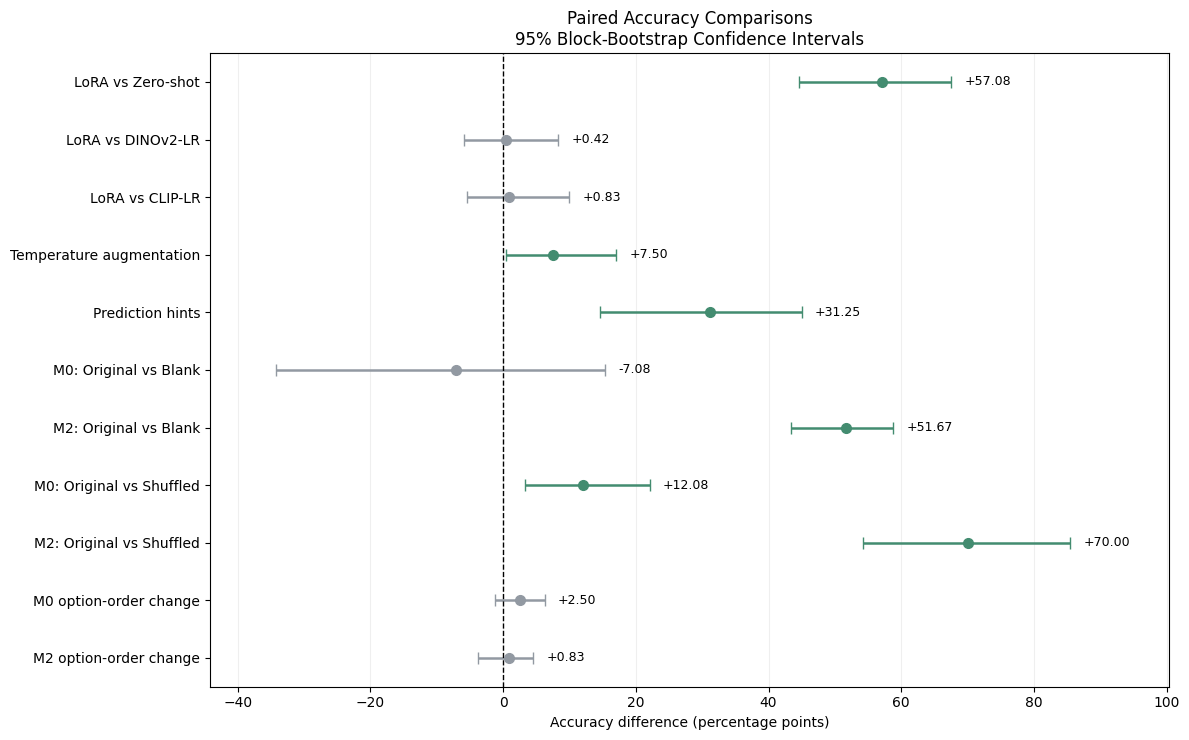

In [99]:
# 10.5.2 Forest plot of paired accuracy differences

forest = paired_summary[
    paired_summary.qtype == "Overall"
].copy().reset_index(drop=True)

forest_labels = {
    "LoRA vs M1-dinov2-LR": "LoRA vs DINOv2-LR",
    "LoRA vs M1-clip-LR": "LoRA vs CLIP-LR",
    "M0 visual information": "M0: Original vs Blank",
    "M2 visual information": "M2: Original vs Blank",
    "M0 correct image matching": "M0: Original vs Shuffled",
    "M2 correct image matching": "M2: Original vs Shuffled"
}

forest["display_name"] = forest.comparison.replace(
    forest_labels
)

fig, ax = plt.subplots(
    figsize=(12, 7.5)
)

for i, r in forest.iterrows():

    color = (
        "#438C70"
        if r.ci_excludes_zero
        else "#9299A2"
    )

    ax.errorbar(
        r.difference_pp,
        i,
        xerr=[[
            max(0, r.difference_pp - r.ci_lower)
        ], [
            max(0, r.ci_upper - r.difference_pp)
        ]],
        fmt="o",
        color=color,
        capsize=4,
        markersize=7,
        linewidth=1.8
    )

    ax.text(
        r.ci_upper + 2,
        i,
        f"{r.difference_pp:+.2f}",
        va="center",
        fontsize=9
    )

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_yticks(range(len(forest)))
ax.set_yticklabels(forest.display_name)
ax.invert_yaxis()

ax.set_xlim(
    min(-10, forest.ci_lower.min() - 10),
    forest.ci_upper.max() + 15
)

ax.set_xlabel("Accuracy difference (percentage points)")

ax.set_title(
    "Paired Accuracy Comparisons\n"
    "95% Block-Bootstrap Confidence Intervals"
)

ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_paired_comparisons.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_paired_comparisons.pdf",
    bbox_inches="tight"
)

plt.show()

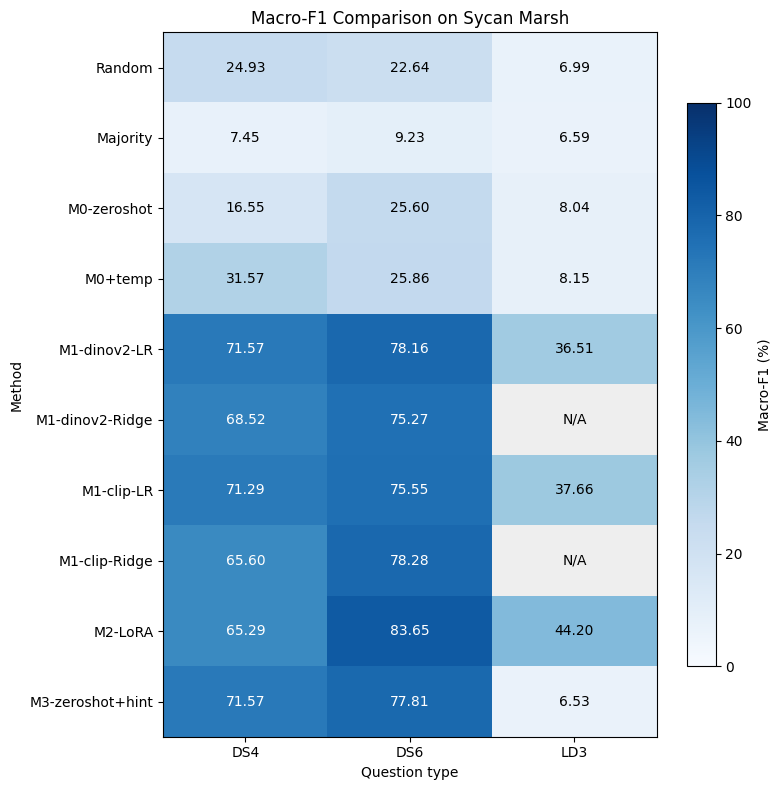

In [100]:
# 10.5.3 Macro-F1 comparison heatmap

fig, ax = plt.subplots(figsize=(8, 8))

values = macro_table.to_numpy(dtype=float)

cmap_f1 = plt.get_cmap("Blues").copy()
cmap_f1.set_bad("#eeeeee")

im = ax.imshow(
    np.ma.masked_invalid(values),
    cmap=cmap_f1,
    vmin=0,
    vmax=100,
    aspect="auto"
)

for i in range(values.shape[0]):

    for j in range(values.shape[1]):

        v = values[i, j]

        ax.text(
            j, i,
            "N/A" if np.isnan(v) else f"{v:.2f}",
            ha="center",
            va="center",
            fontsize=10,
            color=(
                "white"
                if np.isfinite(v) and v > 55
                else "black"
            )
        )

ax.set_xticks(range(len(macro_table.columns)))
ax.set_xticklabels(macro_table.columns)

ax.set_yticks(range(len(macro_table.index)))
ax.set_yticklabels(macro_table.index)

ax.set_xlabel("Question type")
ax.set_ylabel("Method")

ax.set_title(
    "Macro-F1 Comparison on Sycan Marsh"
)

fig.colorbar(
    im,
    ax=ax,
    label="Macro-F1 (%)",
    shrink=0.8
)

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_macro_f1.pdf",
    bbox_inches="tight"
)

plt.show()

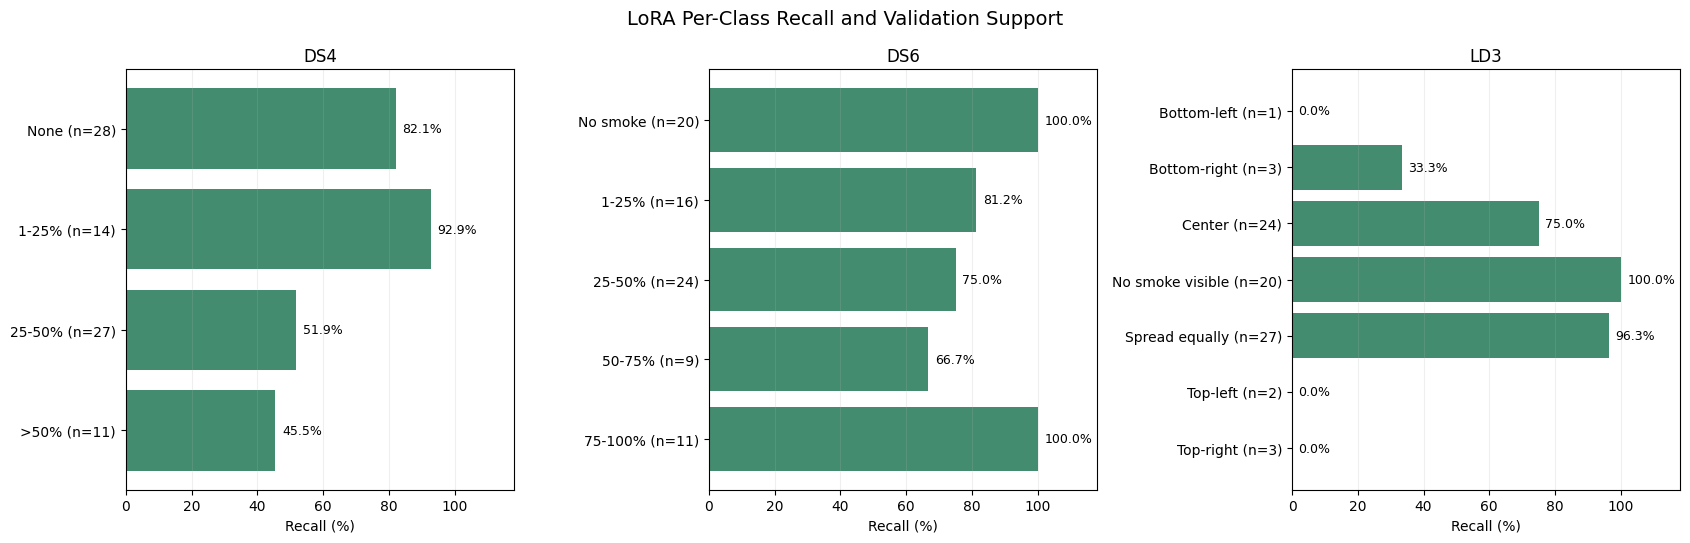

In [101]:
# 10.5.4 LoRA class-level recall and sample support

fig, axes = plt.subplots(
    1, len(targets),
    figsize=(17, 5.5),
    sharex=True
)

for ax, q in zip(axes, targets):

    d = per_class_metrics[
        (per_class_metrics.method == "M2-LoRA") &
        (per_class_metrics.qtype == q)
    ].copy()

    positions = np.arange(len(d))

    ax.barh(
        positions,
        d.recall,
        color="#438C70"
    )

    tick_labels = [
        f"{label} (n={support})"
        for label, support in zip(
            d.label, d.support
        )
    ]

    ax.set_yticks(positions)
    ax.set_yticklabels(tick_labels)
    ax.invert_yaxis()

    for i, value in enumerate(d.recall):

        if np.isfinite(value):

            ax.text(
                value + 2,
                i,
                f"{value:.1f}%",
                va="center",
                fontsize=9
            )

    ax.set_xlim(0, 118)
    ax.set_title(q)
    ax.set_xlabel("Recall (%)")
    ax.grid(axis="x", alpha=0.2)

fig.suptitle(
    "LoRA Per-Class Recall and Validation Support",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    work / "figures" / "fig_lora_per_class_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    work / "figures" / "fig_lora_per_class_recall.pdf",
    bbox_inches="tight"
)

plt.show()

In [102]:
# 11.2 Verify research outputs

from pathlib import Path

result_files = sorted(
    p for p in (work / "results").rglob("*")
    if p.is_file()
)

figure_files = sorted(
    p for p in (work / "figures").rglob("*")
    if p.is_file()
)

print("=" * 60)
print("FINAL RESEARCH OUTPUTS")
print("=" * 60)

print("\nRESULT FILES:\n")

for p in result_files:
    print(f"{p.name:50s} {p.stat().st_size / 1024:8.2f} KB")

print("\nFIGURE FILES:\n")

for p in figure_files:
    print(f"{p.name:50s} {p.stat().st_size / 1024:8.2f} KB")

print("\nTotal result files:", len(result_files))
print("Total PNG figures:", len([
    p for p in figure_files if p.suffix == ".png"
]))
print("Total PDF figures:", len([
    p for p in figure_files if p.suffix == ".pdf"
]))

print("\nLoRA checkpoints:")

for p in sorted((work / "lora").rglob("adapter_config.json")):
    print(p.parent)

print("\nAll outputs verified.")

FINAL RESEARCH OUTPUTS

RESULT FILES:

all_preds_partial.csv                                992.75 KB
baseline_results.csv                                   0.36 KB
blank_image_control.csv                                0.94 KB
classification_metrics.csv                             2.74 KB
final_pilot_results.csv                                1.54 KB
frame_splits.csv                                     177.31 KB
lora_configuration.csv                                 0.27 KB
lora_log.csv                                           1.48 KB
m0_blank_predictions.csv                              35.67 KB
m0_m1_pilot_results.csv                                1.09 KB
m0_m3_prediction_agreement.csv                         0.07 KB
m0_option_positions.csv                                0.07 KB
m0_pilot_raw_predictions.csv                          34.36 KB
m0_shuffled_options_predictions.csv                   34.54 KB
m0_shuffled_predictions.csv                           34.36 KB
m0_temp_pilot_ra

In [103]:
# 11.4 Export the complete research report package

import shutil
import zipfile

export_dir = work / "exports"
export_dir.mkdir(parents=True, exist_ok=True)

zip_path = export_dir / "wildfire_vqa_final_report.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for folder in ["results", "figures"]:

        for p in sorted((work / folder).rglob("*")):

            if p.is_file():
                z.write(
                    p,
                    arcname=str(p.relative_to(work))
                )

    # Include the image matching metadata
    mapping = work / "cache" / "sycan_image_mapping.csv"

    if mapping.exists():
        z.write(
            mapping,
            arcname="metadata/sycan_image_mapping.csv"
        )

# Verify archive integrity
with zipfile.ZipFile(zip_path, "r") as z:

    assert z.testzip() is None

    print("Archive verified successfully.")
    print("Total archived files:", len(z.namelist()))

# Copy to Colab Files panel
local_zip = Path("/content") / zip_path.name

shutil.copy2(zip_path, local_zip)

print("\nFinal archive:", zip_path.name)
print("Size:", round(zip_path.stat().st_size / 1024**2, 2), "MB")
print("Google Drive:", zip_path)
print("Colab:", local_zip)

Archive verified successfully.
Total archived files: 94

Final archive: wildfire_vqa_final_report.zip
Size: 14.33 MB
Google Drive: /content/drive/MyDrive/wildfire_vqa_study/exports/wildfire_vqa_final_report.zip
Colab: /content/wildfire_vqa_final_report.zip


In [104]:
from google.colab import files

files.download("/content/wildfire_vqa_final_report.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

This study demonstrates that task-specific LoRA adaptation
substantially improves wildfire visual question answering
on the Sycan Marsh validation split.

Overall accuracy increases from 21.25% for zero-shot
Qwen3-VL-2B-Instruct to 78.33% after LoRA fine-tuning,
an improvement of 57.08 percentage points, while training
approximately 0.301% of the model parameters.

Frozen DINOv2 and CLIP classifiers also achieve competitive
accuracies of 77.92% and 77.50%, respectively.

Blank and shuffled image controls reduce LoRA accuracy to
26.67% and 8.33%, providing evidence that its predictions
depend on relevant visual information.

The adapted model also achieves 93.33% prediction consistency
under answer-option reordering.

Despite these improvements, rare smoke localization
categories remain challenging. Cross-site generalization
and independent test-set evaluation are required before
broader conclusions can be established.